# CoralAgent-TRACE — Final Reproducible Implementation

**Purpose.** This notebook is the consolidated, executable source for the CoralAgent project. It reproduces the final 100-image development/ablation experiment, supports checkpoint-preserving expansion to a persistent 500-image bank, provides no-API post-hoc analyses, and includes the optional decisive full-500 strict GPT-5 baseline extension.

**Current proposed method:** `A3_trace_no_bleaching_tools`  
**Primary orchestrator/tool model:** OpenAI GPT-5  
**Independent verifier/judge:** xAI Grok-4.3  
**Dataset:** `CoralReefData/CoralVQA` labeled LLaVA-format split  
**Persistent bank:** 500 images × 6 questions = 3,000 rows  
**Default active development run:** first 100 bank images = 600 rows

> The broad flow diagram below includes components that exist in the codebase. The proposed A3 path disables chart detection, segmentation, and chart-free bleaching estimation; A7 activates that branch as an ablation. ReefBank is primarily an external zero-shot evaluation suite. The v12 implementation uses **question-conditioned planned routing**, not multi-agent debate and not a learned free-form tool policy.

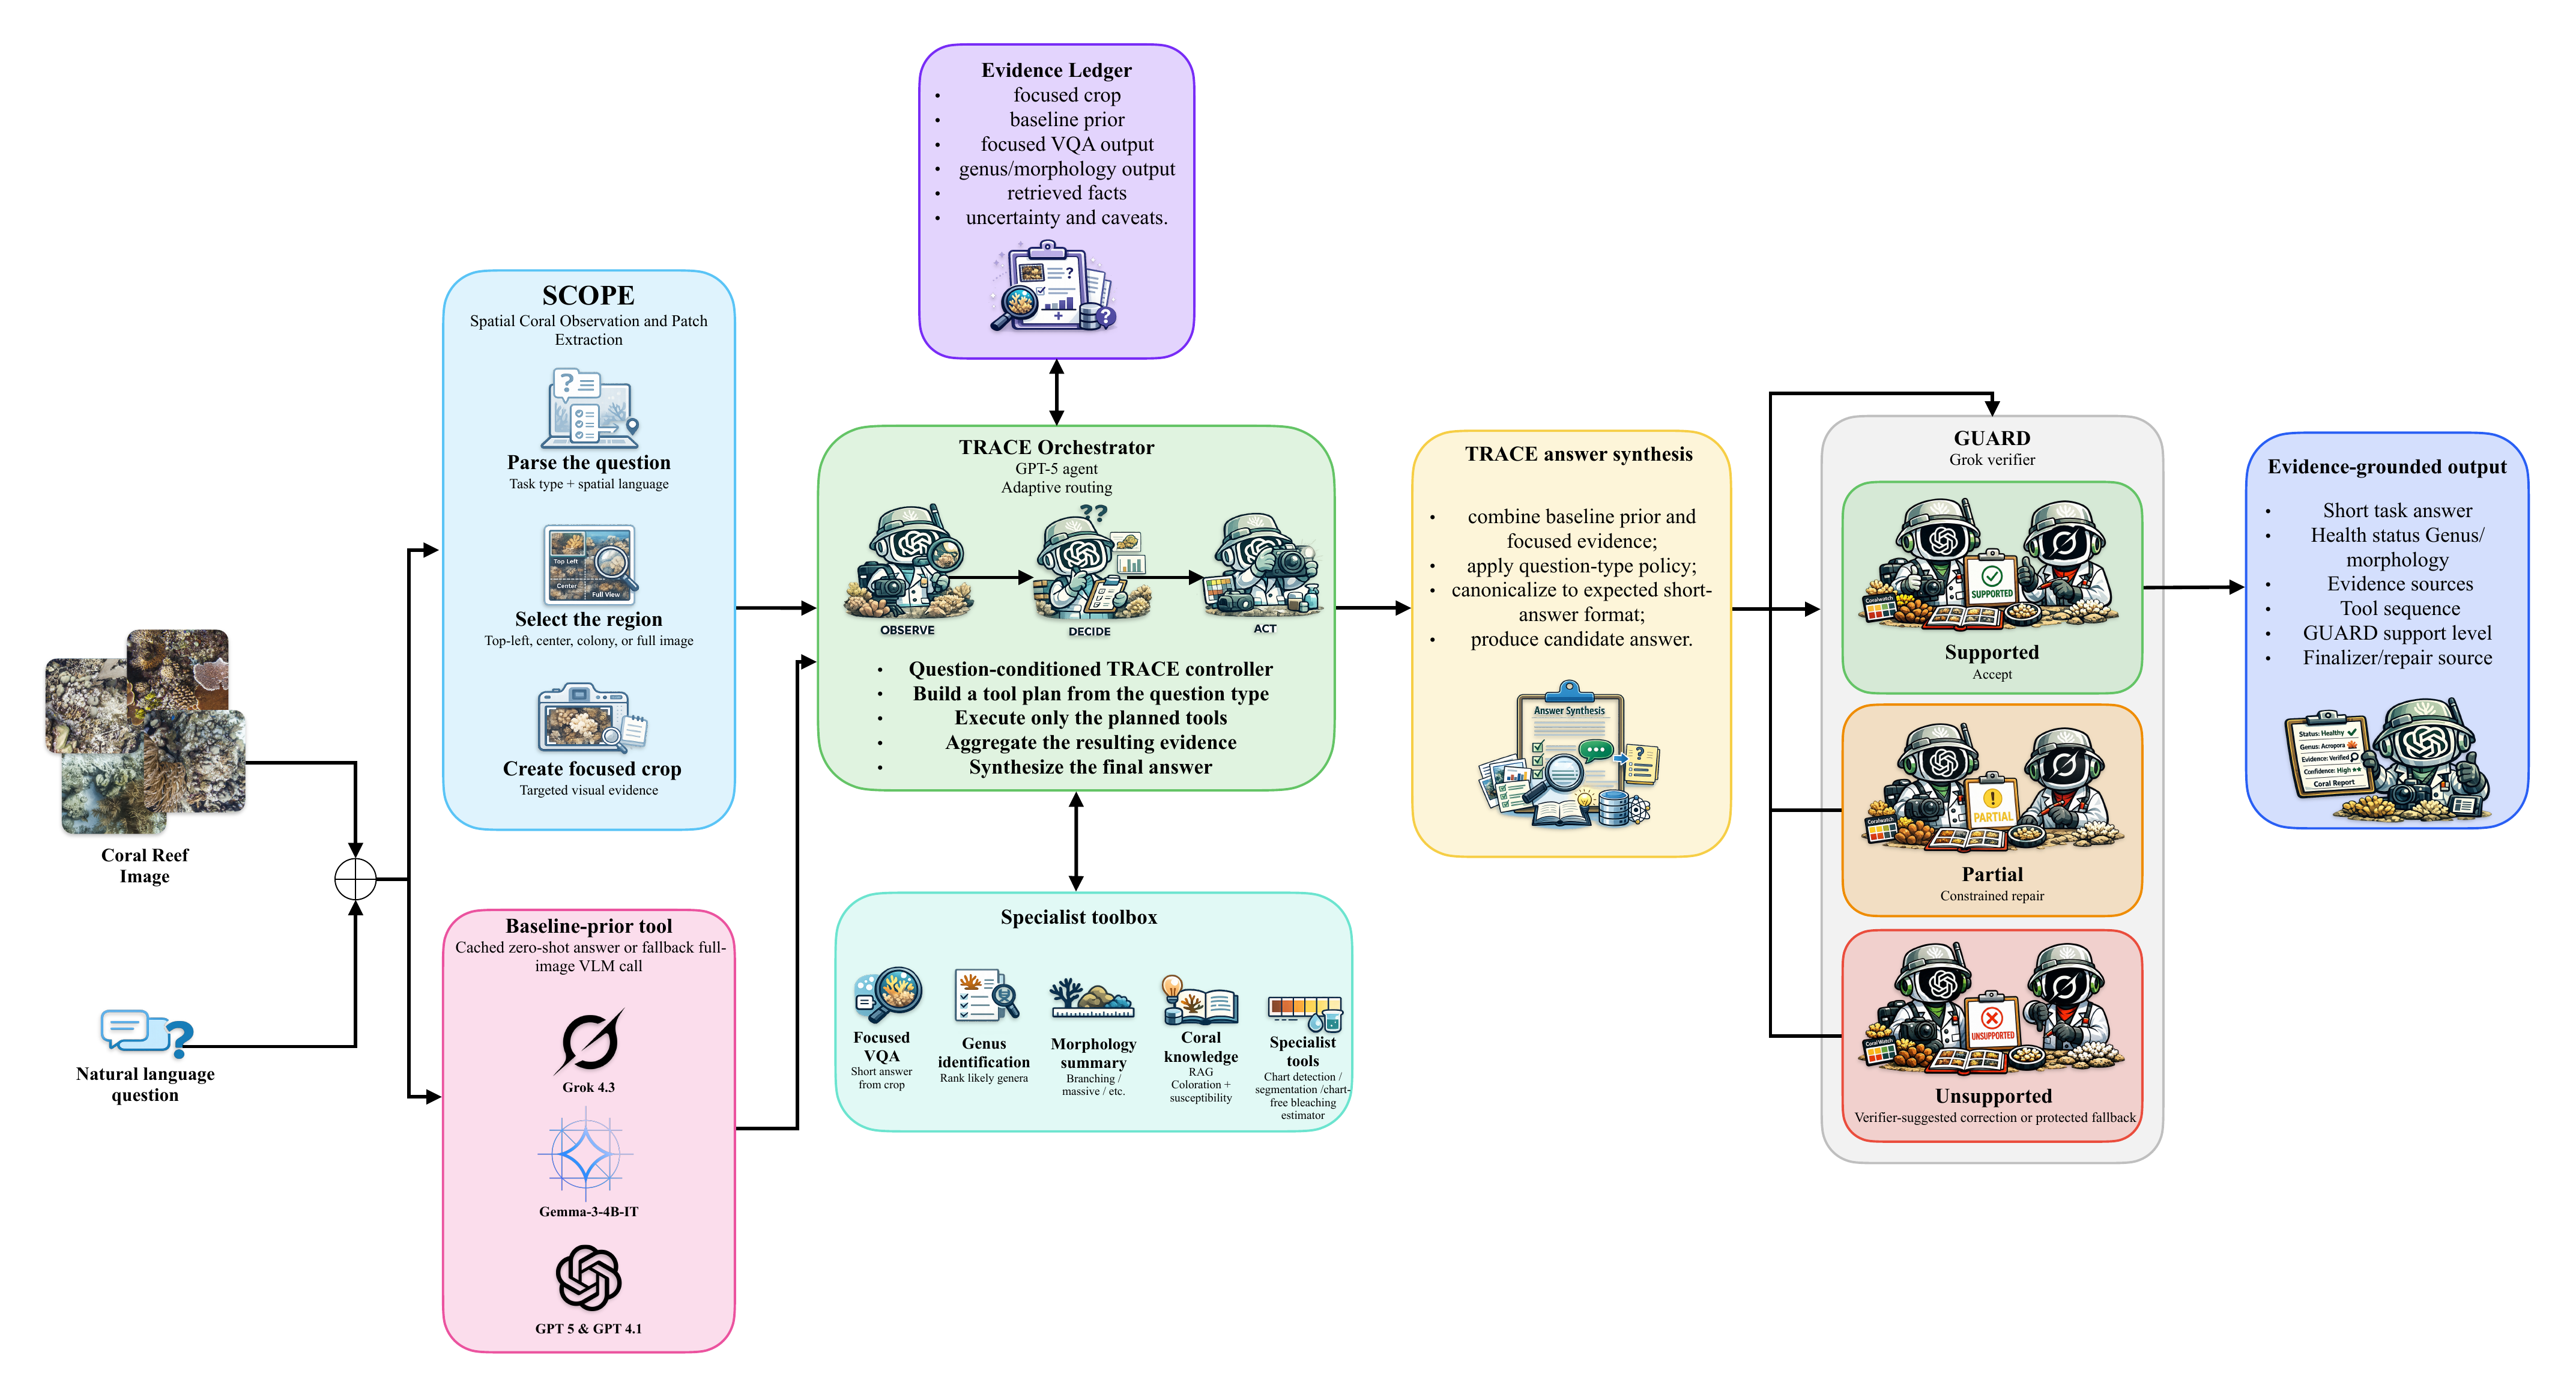

## Source-of-truth and reproducibility contract

This notebook consolidates the tested `v12c_ensemble_countfix` implementation and the later project decisions recorded in the master context document.

### Final decisions

- **CoralAgent-TRACE = A3.** A3 uses SCOPE, a transparent baseline-prior tool, focused VQA, question-conditioned specialist tools, ecological retrieval where relevant, TRACE answer synthesis, and Grok GUARD.
- **A7 is an ablation.** It adds chart detection, deterministic segmentation, and a chart-free bleaching proxy. It is not the proposed default because it did not improve the development result and increased false alarms.
- **Strict GPT-5 is the paper baseline.** The old JSON-oriented GPT-5 baseline is retained only because the original A3 baseline-prior tool was built around that checkpoint. The clean paper comparison uses `B0b_gpt5_zero_shot_strict`.
- **Qwen is exploratory only.** It is excluded from clean paper figures because most saved outputs were empty/unusable in the tested serverless path.
- **No Claude/Anthropic models.** OpenAI, xAI, and Together.ai are the supported providers.
- **Development versus validation.** The first 100 images were repeatedly inspected and are a development/ablation subset. Images 101–500 form the frozen-policy extension. Any further tuning after inspecting that extension requires a new untouched validation set such as PAC-USA.
- **No unsupported superiority claim at 500 images.** A complete strict GPT-5 baseline over all 500 images is an optional cell in this notebook; without it, the embedded-prior analysis is diagnostic only.

### Recommended run profiles

| Profile | Active images | API work | Purpose |
|---|---:|---|---|
| `development_100` | 100 | Baselines + A0–A8 | Reproduce the paper ablation |
| `extension_A3_500` | 500 | Only missing A3 rows | Scale the frozen A3 policy without recomputing 100 images |
| `analysis_only` | Existing checkpoints | None | Rebuild metrics, figures, prior audits, and qualitative cards |
| `strict_gpt5_500` | 500 | Only missing strict GPT-5 rows | Decisive full-run comparator |
| `cross_region` | Configurable | New calls | Future untouched PAC-USA validation |

## Frozen result references and sanity checks

The exact values can shift slightly with parser/canonicalization changes; the following are the final paper-facing 100-image sanity targets:

| Method | Semantic accuracy |
|---|---:|
| CoralAgent-TRACE A3 | 0.557 |
| GPT-5 strict zero-shot | 0.520 |
| GPT-4.1 zero-shot | 0.510 |
| Grok zero-shot | 0.475 |
| Gemma zero-shot | 0.438 |

The final development ablation target is: A3 0.557; A7 + chart-free bleaching tools 0.548; no retrieval 0.535; prior + SCOPE 0.468; no baseline prior 0.460; fixed all tools 0.430; no GUARD 0.430; SCOPE only 0.232.

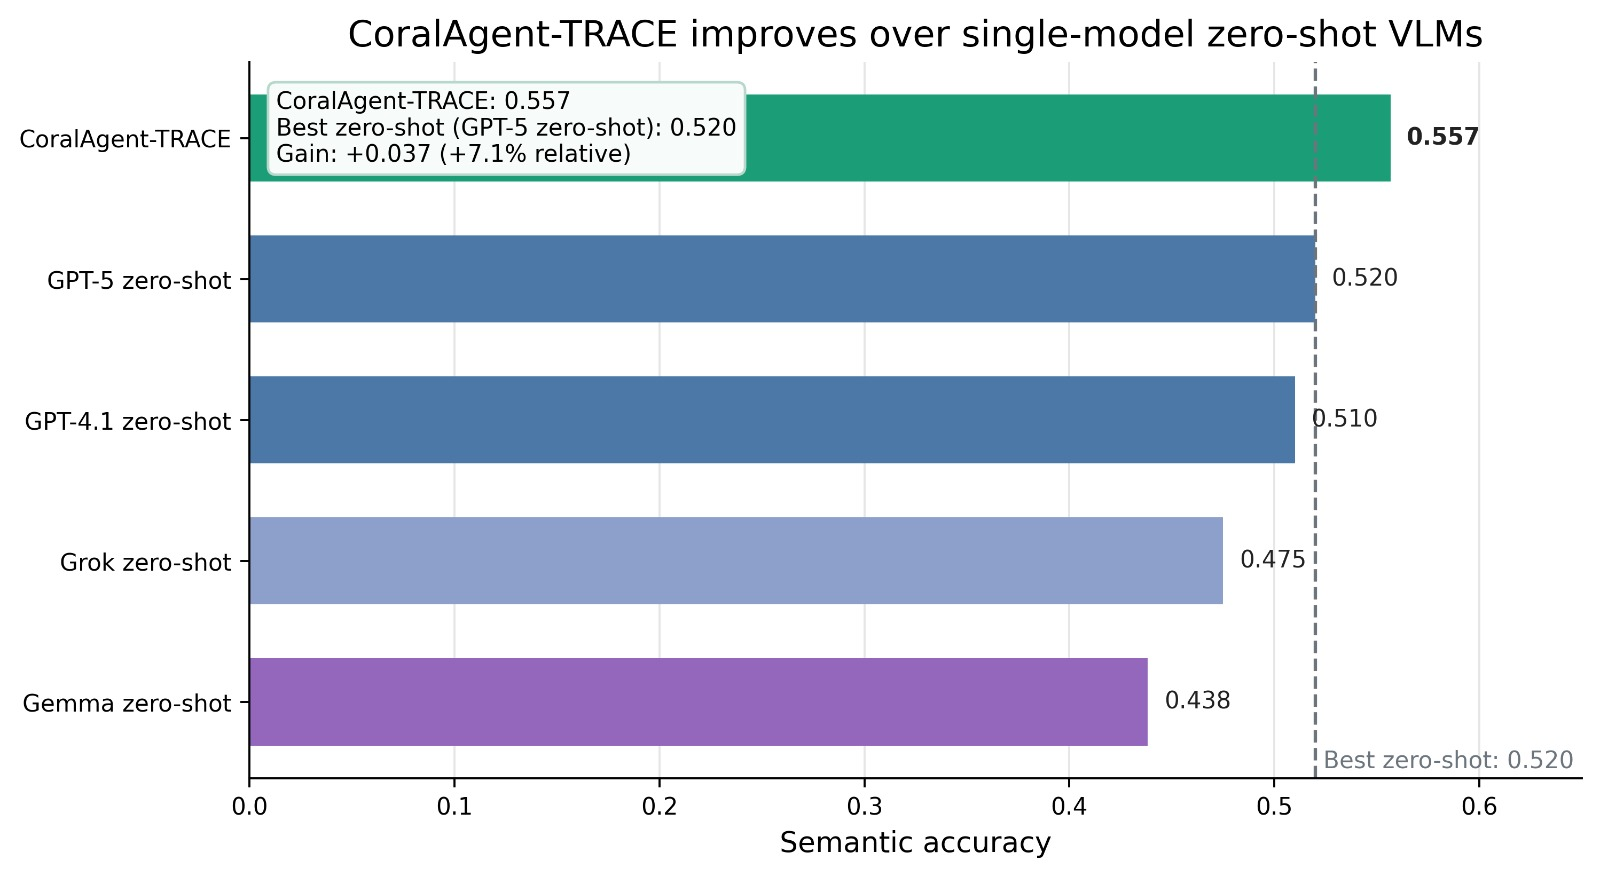

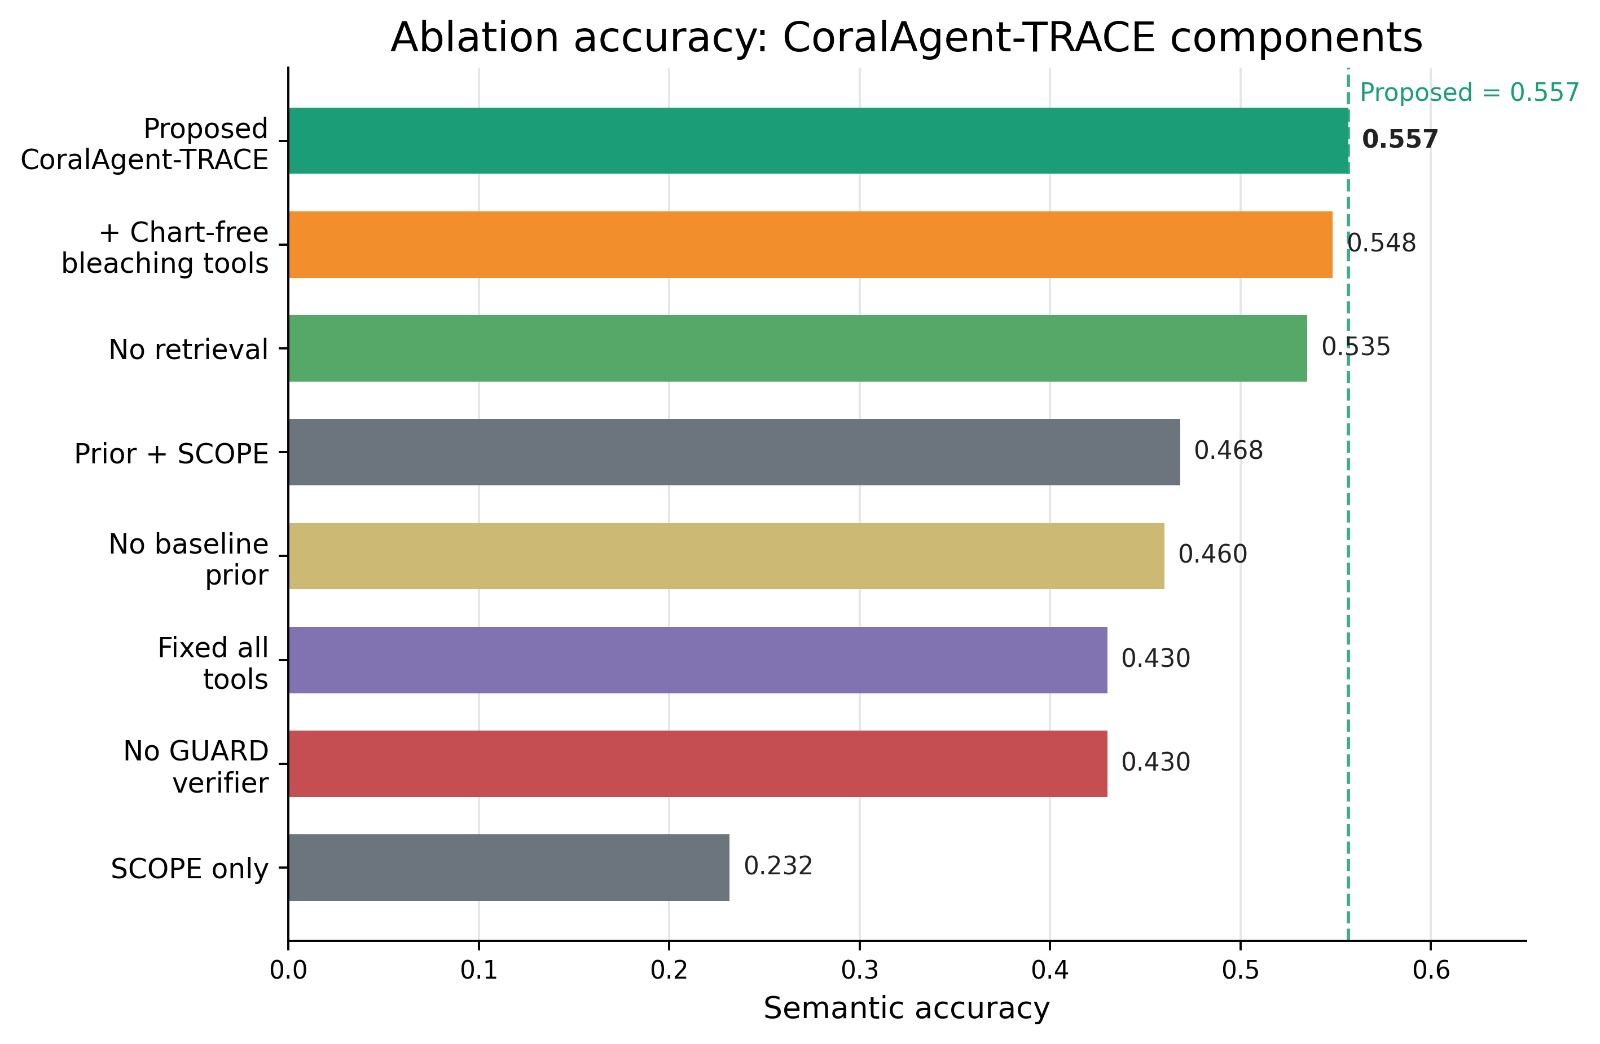

## 1. Install and repair dependencies

Run once in a fresh environment. Restart the kernel if NumPy changes. The notebook avoids Jupyter widget progress bars because some JupyterLab/Kaggle images expose a broken `FloatProgress.style` implementation.

In [ ]:
import os, sys, subprocess

# Avoid broken notebook widget progress bars in some JupyterLab/Kaggle environments.
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

# Core packages. We explicitly install modern numexpr/bottleneck because many Jupyter/Kaggle
# images include old system builds compiled against NumPy 1.x, which fail under NumPy 2.x.
packages = [
    "openai>=1.90.0",
    "huggingface_hub>=0.24.0",
    "pillow>=10.0.0",
    "tqdm>=4.66.0",
    "requests>=2.31.0",
    "pyarrow>=15.0.0",
    "numpy<2.3",
    "pandas>=2.2.3",
    "matplotlib>=3.9.0",
    "scikit-learn>=1.5.0",
    "opencv-python-headless>=4.10.0",
    "numexpr>=2.10.2",
    "bottleneck>=1.4.2",
    "scipy>=1.13.0",
    "nbformat>=5.10.0",
]

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", *packages])
print("Dependencies installed/checked.")
print("If NumPy was changed in this active kernel, restart the kernel once before continuing.")

## 2. Imports, directories, API clients, and environment snapshot

Secrets are read from environment variables, Kaggle secrets, or hidden prompts. Never save keys in the notebook. The environment snapshot is written to the output directory for auditability.

In [ ]:
import os
# Avoid Hugging Face/tqdm notebook-widget progress bars; use text progress only.
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import re
import io
import gc
import sys
import cv2
import ast
import json
import time
import base64
import zipfile
import random
import shutil
import textwrap
import traceback
import importlib
import subprocess
from pathlib import Path
from collections import Counter, defaultdict
from typing import Any, Dict, List, Optional, Tuple
from getpass import getpass

# --- Compatibility guard ----------------------------------------------------
# Some notebook images have old system numexpr/bottleneck wheels compiled against
# NumPy 1.x. With NumPy 2.x they can raise AttributeError: _ARRAY_API not found
# during `import pandas`. We repair them here before importing pandas. If repair
# fails, we mask them so pandas runs without those optional acceleration modules.
def ensure_optional_binary(pkg: str, spec: str) -> bool:
    try:
        mod = importlib.import_module(pkg)
        print(f"{pkg}: ready ({getattr(mod, '__version__', 'unknown')})")
        return True
    except Exception as first_error:
        sys.modules.pop(pkg, None)
        print(f"{pkg}: repairing after import failure: {type(first_error).__name__}: {first_error}")
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", spec])
            importlib.invalidate_caches()
            sys.modules.pop(pkg, None)
            mod = importlib.import_module(pkg)
            print(f"{pkg}: repaired ({getattr(mod, '__version__', 'unknown')})")
            return True
        except Exception as second_error:
            print(f"{pkg}: unavailable after repair; pandas will run without it. {type(second_error).__name__}: {second_error}")
            sys.modules[pkg] = None
            return False

ensure_optional_binary("numexpr", "numexpr>=2.10.2")
ensure_optional_binary("bottleneck", "bottleneck>=1.4.2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.std import tqdm
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report

from IPython.display import display, Markdown
from huggingface_hub import hf_hub_download, list_repo_files
try:
    from huggingface_hub.utils import disable_progress_bars
    disable_progress_bars()
except Exception:
    pass
from openai import OpenAI

# Keep pandas away from optional acceleration paths if the environment is fragile.
try:
    pd.set_option("compute.use_numexpr", False)
    pd.set_option("compute.use_bottleneck", False)
except Exception:
    pass
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 240)

PROJECT_ROOT = Path(os.getenv("CORALAGENT_PROJECT_ROOT", str(Path.cwd()))).expanduser()
WORK_DIR = Path(os.getenv("CORALAGENT_WORK_DIR", str(PROJECT_ROOT / "coralagent_work"))).expanduser()
DATA_DIR = WORK_DIR / "data"
IMAGE_DIR = WORK_DIR / "images"
SAMPLE_IMAGE_DIR = WORK_DIR / "sample_images"
OUTPUT_DIR = WORK_DIR / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
CACHE_DIR = WORK_DIR / "cache"

for d in [WORK_DIR, DATA_DIR, IMAGE_DIR, SAMPLE_IMAGE_DIR, OUTPUT_DIR, FIG_DIR, CACHE_DIR]:
    d.mkdir(parents=True, exist_ok=True)


def read_secret(name: str, prompt: bool = True) -> str:
    """Read an API key from env, Kaggle secrets, or a hidden prompt."""
    val = os.getenv(name, "").strip()
    if val:
        return val
    try:
        from kaggle_secrets import UserSecretsClient
        val = (UserSecretsClient().get_secret(name) or "").strip()
        if val:
            os.environ[name] = val
            return val
    except Exception:
        pass
    if prompt and os.getenv("CORALAGENT_PROMPT_FOR_KEYS", "1") == "1":
        try:
            val = getpass(f"{name} (leave blank to skip): ").strip()
            if val:
                os.environ[name] = val
                return val
        except Exception:
            pass
    return ""

OPENAI_API_KEY = read_secret("OPENAI_API_KEY")
XAI_API_KEY = read_secret("XAI_API_KEY")
TOGETHER_API_KEY = read_secret("TOGETHER_API_KEY")

openai_client = OpenAI(api_key=OPENAI_API_KEY) if OPENAI_API_KEY else None
xai_client = OpenAI(api_key=XAI_API_KEY, base_url="https://api.x.ai/v1") if XAI_API_KEY else None
together_client = OpenAI(api_key=TOGETHER_API_KEY, base_url="https://api.together.ai/v1") if TOGETHER_API_KEY else None

print("Working directory:", WORK_DIR)
print("OpenAI key:", "present" if OPENAI_API_KEY else "missing - required for baseline and CoralAgent runs")
print("xAI key:", "present" if XAI_API_KEY else "missing - verifier will fall back to OpenAI if available")
print("Together key:", "present" if TOGETHER_API_KEY else "missing - optional open-VLM path disabled")

if openai_client is None:
    print("\nNOTE: Dataset loading/debug cells will still run. Set OPENAI_API_KEY before running baseline/agent cells.")

In [ ]:
import platform
import importlib.metadata as importlib_metadata

ENVIRONMENT_SNAPSHOT = {
    "python": sys.version,
    "platform": platform.platform(),
    "executable": sys.executable,
    "packages": {},
}
for package_name in [
    "openai", "huggingface_hub", "numpy", "pandas", "matplotlib",
    "scikit-learn", "opencv-python-headless", "Pillow", "scipy", "tqdm",
]:
    try:
        ENVIRONMENT_SNAPSHOT["packages"][package_name] = importlib_metadata.version(package_name)
    except Exception:
        ENVIRONMENT_SNAPSHOT["packages"][package_name] = None

snapshot_path = OUTPUT_DIR / "environment_snapshot.json"
snapshot_path.write_text(json.dumps(ENVIRONMENT_SNAPSHOT, indent=2), encoding="utf-8")
print(json.dumps(ENVIRONMENT_SNAPSHOT, indent=2))
print("Saved:", snapshot_path)

## 3. Experiment configuration

Keep `CORALAGENT_EXPERIMENT_TAG` unchanged when expanding 100 → 500 images. The active image count is deliberately not part of the tag so completed question-level rows are reused.

In [ ]:
# Dataset
DATASET_REPO = "CoralReefData/CoralVQA"

# Important: the public CoralVQA_test.jsonl schema may expose question metadata only
# (`question_id`, `image`, `text`, `category`) without reference answers.
# For a scorable paper-ablation run, default to the labeled LLaVA-format training split.
# In the manuscript, call this a labeled CoralVQA evaluation subset, not the hidden official test set.
PRIMARY_SPLIT_FILE = os.getenv("CORALVQA_PRIMARY_SPLIT_FILE", "CoralVQA_train.jsonl")
TEST_SPLIT_FILE = os.getenv("CORALVQA_TEST_SPLIT_FILE", "CoralVQA_test.jsonl")
CROSS_REGION_SPLIT_FILE = os.getenv("CORALVQA_CROSS_REGION_SPLIT_FILE", "PAC_USA.jsonl")
USE_CROSS_REGION = os.getenv("USE_CROSS_REGION", "0") == "1"
DOWNLOAD_IMAGE_ZIP = os.getenv("DOWNLOAD_IMAGE_ZIP", "1") == "1"
LOCAL_IMAGE_ROOT = Path(os.getenv("CORALVQA_IMAGE_ROOT", "")).expanduser() if os.getenv("CORALVQA_IMAGE_ROOT") else None

# v12 run size and persistence.
# Builds a stable 500-image bank, actively runs the first 100 images by default.
# To expand a good 100-image run to 500 without recomputing completed rows, rerun with:
#   export ACTIVE_PILOT_IMAGES=500
# Keep CORALAGENT_EXPERIMENT_TAG unchanged.
PILOT_BANK_IMAGES = int(os.getenv("PILOT_BANK_IMAGES", "500"))
ACTIVE_PILOT_IMAGES = int(os.getenv("ACTIVE_PILOT_IMAGES", "100"))
QUESTIONS_PER_IMAGE = int(os.getenv("QUESTIONS_PER_IMAGE", "6"))
SMOKE_SELECTION_MODE = os.getenv("SMOKE_SELECTION_MODE", "balanced_health")  # balanced_health | first_random
SMOKE_BLEACHED_FRACTION = float(os.getenv("SMOKE_BLEACHED_FRACTION", "0.5"))
RANDOM_SEED = int(os.getenv("RANDOM_SEED", "42"))
PILOT_IMAGES = PILOT_BANK_IMAGES
SMOKE_TEST_IMAGES = ACTIVE_PILOT_IMAGES
EXPERIMENT_TAG = os.getenv("CORALAGENT_EXPERIMENT_TAG", f"v12_TRACE_bank{PILOT_BANK_IMAGES}_q{QUESTIONS_PER_IMAGE}")
FINAL_NOTEBOOK_VERSION = "v13_final_reproducible"
PAPER_PROPOSED_METHOD = "A3_trace_no_bleaching_tools"
PAPER_BLEACHING_ABLATION_METHOD = "A7_full_coralagent_trace"
PAPER_STRICT_GPT5_METHOD = "B0b_gpt5_zero_shot_strict"
PAPER_CLEAN_MAJORITY_METHOD = "B5c_reefbank_majority_vote_no_qwen"
PAPER_CLEAN_WEIGHTED_METHOD = "B6c_reefbank_weighted_vote_no_qwen"

# Run switches
RUN_REEFBANK_BASELINES = os.getenv("RUN_REEFBANK_BASELINES", "1") == "1"
RUN_TRACE_ABLATIONS = os.getenv("RUN_TRACE_ABLATIONS", "1") == "1"
RUN_VERIFIER = os.getenv("RUN_VERIFIER", "1") == "1"
RUN_LLM_JUDGE = os.getenv("RUN_LLM_JUDGE", "1") == "1"
RUN_STRICT_GPT5_BASELINE = os.getenv("RUN_STRICT_GPT5_BASELINE", "1") == "1"
RUN_QWEN_EXPLORATORY = os.getenv("RUN_QWEN_EXPLORATORY", "0") == "1"
RUN_500_EXTENSION = os.getenv("RUN_500_EXTENSION", "0") == "1"
RUN_FULL_500_STRICT_GPT5 = os.getenv("RUN_FULL_500_STRICT_GPT5", "0") == "1"
RESUME_FROM_CHECKPOINTS = os.getenv("RESUME_FROM_CHECKPOINTS", "1") == "1"
STOP_IF_PROVIDER_PROBE_FAILS = os.getenv("STOP_IF_PROVIDER_PROBE_FAILS", "1") == "1"

# Agent loop and safety switches
MAX_AGENT_STEPS = int(os.getenv("MAX_AGENT_STEPS", "5"))
MIN_TOOLS_BEFORE_ANSWER = int(os.getenv("MIN_TOOLS_BEFORE_ANSWER", "1"))
MAX_REPAIR_ROUNDS = int(os.getenv("MAX_REPAIR_ROUNDS", "1"))
INCLUDE_IMAGE_IN_AGENT_DECISION = os.getenv("INCLUDE_IMAGE_IN_AGENT_DECISION", "0") == "1"
USE_RULE_BASED_FINALIZER = os.getenv("USE_RULE_BASED_FINALIZER", "1") == "1"
STRICT_BLEACHING_CONSENSUS = os.getenv("STRICT_BLEACHING_CONSENSUS", "1") == "1"
GENUS_CONSTRAIN_TO_KNOWN = os.getenv("GENUS_CONSTRAIN_TO_KNOWN", "1") == "1"
USE_BASELINE_PRIOR_TOOL = os.getenv("USE_BASELINE_PRIOR_TOOL", "1") == "1"
COLOR_PREFER_BASELINE_PRIOR = os.getenv("COLOR_PREFER_BASELINE_PRIOR", "1") == "1"
PRESENCE_COUNT_PREFER_BASELINE_PRIOR = os.getenv("PRESENCE_COUNT_PREFER_BASELINE_PRIOR", "1") == "1"
PRESENCE_AREA_PREFER_BASELINE_PRIOR = os.getenv("PRESENCE_AREA_PREFER_BASELINE_PRIOR", "1") == "1"
GENUS_HIGH_CONFIDENCE = float(os.getenv("GENUS_HIGH_CONFIDENCE", "0.72"))
GENUS_AREA_OVERRIDE_CONFIDENCE = float(os.getenv("GENUS_AREA_OVERRIDE_CONFIDENCE", "0.86"))
GENUS_BASELINE_FALLBACK_CONFIDENCE = float(os.getenv("GENUS_BASELINE_FALLBACK_CONFIDENCE", "0.68"))
BLEACH_FRAC_YES_THRESHOLD = float(os.getenv("BLEACH_FRAC_YES_THRESHOLD", "0.18"))
BLEACH_FRAC_STRONG_YES_THRESHOLD = float(os.getenv("BLEACH_FRAC_STRONG_YES_THRESHOLD", "0.35"))
COLOR_FIRST_MENTION_PRIORITY = os.getenv("COLOR_FIRST_MENTION_PRIORITY", "1") == "1"
MORPHOLOGY_PREFER_BASELINE_WHEN_VALID = os.getenv("MORPHOLOGY_PREFER_BASELINE_WHEN_VALID", "1") == "1"
V12_VERIFIER_REPAIR = os.getenv("V12_VERIFIER_REPAIR", os.getenv("V11_VERIFIER_REPAIR", "1")) == "1"
VERIFIER_REPAIR_USES_IMAGE = os.getenv("VERIFIER_REPAIR_USES_IMAGE", "1") == "1"
PROTECT_SIMPLE_TYPES_FROM_REPAIR = os.getenv("PROTECT_SIMPLE_TYPES_FROM_REPAIR", "1") == "1"
REPAIR_PROTECTED_TYPES = set([x.strip() for x in os.getenv("REPAIR_PROTECTED_TYPES", "color_visual,genus_taxonomy,presence_count").split(",") if x.strip()])
TOOL_AUDIT_STRICT = os.getenv("TOOL_AUDIT_STRICT", "1") == "1"

# Main model choices. GPT-5 is used for the proposed CoralAgent-TRACE orchestrator/finalizer.
# Grok is used for independent GUARD verifier and judge. Qwen + Gemma are open VLM baselines and open-source verifier ablation.
OPENAI_AGENT_MODEL = os.getenv("OPENAI_AGENT_MODEL", "gpt-5")
OPENAI_TOOL_MODEL = os.getenv("OPENAI_TOOL_MODEL", OPENAI_AGENT_MODEL)
OPENAI_BASELINE_MODEL = os.getenv("OPENAI_BASELINE_MODEL", OPENAI_AGENT_MODEL)
OPENAI_GPT41_BASELINE_MODEL = os.getenv("OPENAI_GPT41_BASELINE_MODEL", "gpt-4.1")
OPENAI_JUDGE_MODEL = os.getenv("OPENAI_JUDGE_MODEL", OPENAI_AGENT_MODEL)
XAI_VERIFIER_MODEL = os.getenv("XAI_VERIFIER_MODEL", "grok-4.3")
XAI_VLM_MODEL = os.getenv("XAI_VLM_MODEL", XAI_VERIFIER_MODEL)
# Together.ai defaults are intentionally serverless vision models.
# Older choices such as Qwen/Qwen2.5-VL-72B-Instruct and google/gemma-3-27b-it
# may require dedicated endpoints on some Together accounts, which caused the v12 probe failure.
def split_model_candidates(raw: str) -> List[str]:
    vals = re.split(r"[;,]", str(raw or ""))
    out = []
    for v in vals:
        v = v.strip()
        if v and v not in out:
            out.append(v)
    return out

TOGETHER_QWEN_MODEL = os.getenv("TOGETHER_QWEN_MODEL", "Qwen/Qwen3.5-9B")
TOGETHER_GEMMA_MODEL = os.getenv("TOGETHER_GEMMA_MODEL", "google/gemma-4-31B-it")
TOGETHER_QWEN_CANDIDATES = split_model_candidates(os.getenv(
    "TOGETHER_QWEN_CANDIDATES",
    f"{TOGETHER_QWEN_MODEL};Qwen/Qwen2.5-VL-72B-Instruct;Qwen/Qwen2.5-VL-7B-Instruct"
))
TOGETHER_GEMMA_CANDIDATES = split_model_candidates(os.getenv(
    "TOGETHER_GEMMA_CANDIDATES",
    f"{TOGETHER_GEMMA_MODEL};google/gemma-3n-E4B-it;google/gemma-3-27b-it"
))
# Backward-compatible single Together variable used by older helper code.
TOGETHER_VLM_MODEL = os.getenv("TOGETHER_VLM_MODEL", TOGETHER_QWEN_MODEL)

# Provider order for existing helper call_vlm. Baselines use explicit provider/model specs below.
BASELINE_PROVIDER_ORDER = os.getenv("CORALAGENT_BASELINE_PROVIDER_ORDER", "openai,xai,together")
TOOL_PROVIDER_ORDER = os.getenv("CORALAGENT_TOOL_PROVIDER_ORDER", "openai,xai,together")
AGENT_PROVIDER_ORDER = os.getenv("CORALAGENT_AGENT_PROVIDER_ORDER", "openai")
VERIFIER_PROVIDER_ORDER = os.getenv("CORALAGENT_VERIFIER_PROVIDER_ORDER", "xai")
JUDGE_PROVIDER_ORDER = os.getenv("CORALAGENT_JUDGE_PROVIDER_ORDER", "xai")

# Zero-shot ReefBank model specifications.
REEFBANK_BASELINE_SPECS = [
    {"method": "B0_gpt5_zero_shot", "label": "GPT-5", "provider": "openai", "model": OPENAI_BASELINE_MODEL, "static_weight": 1.00},
    {"method": "B1_gpt41_zero_shot", "label": "GPT-4.1", "provider": "openai", "model": OPENAI_GPT41_BASELINE_MODEL, "static_weight": 0.92},
    {"method": "B2_grok_zero_shot", "label": "Grok", "provider": "xai", "model": XAI_VLM_MODEL, "static_weight": 0.88},
    {"method": "B3_qwen_zero_shot", "label": "Qwen-VL", "provider": "together", "model": TOGETHER_QWEN_MODEL, "static_weight": 0.70},
    {"method": "B4_gemma_zero_shot", "label": "Gemma-VL", "provider": "together", "model": TOGETHER_GEMMA_MODEL, "static_weight": 0.55},
]
BASELINE_PRIOR_METHOD = os.getenv("BASELINE_PRIOR_METHOD", "B0_gpt5_zero_shot")

# Core methods receiving expensive cross-provider LLM judge scores.
CORE_JUDGE_METHODS = set([x.strip() for x in os.getenv(
    "CORE_JUDGE_METHODS",
    "B0b_gpt5_zero_shot_strict,B6c_reefbank_weighted_vote_no_qwen,A1_prior_scope,A3_trace_no_bleaching_tools,A5_trace_no_verifier,A7_full_coralagent_trace"
).split(",") if x.strip()])

# Throttling and image handling
API_SLEEP_SECONDS = float(os.getenv("API_SLEEP_SECONDS", "0.10"))
API_MAX_RETRIES = int(os.getenv("API_MAX_RETRIES", "3"))
MAX_IMAGE_SIDE_FOR_API = int(os.getenv("MAX_IMAGE_SIDE_FOR_API", "1280"))
JPEG_QUALITY_FOR_API = int(os.getenv("JPEG_QUALITY_FOR_API", "88"))

# Output organization. EXPERIMENT_TAG intentionally does not include ACTIVE_PILOT_IMAGES.
PILOT_BANK_CSV = OUTPUT_DIR / f"pilot_bank_{EXPERIMENT_TAG}_{PILOT_BANK_IMAGES}images.csv"
PILOT_CSV = OUTPUT_DIR / f"pilot_questions_active_{EXPERIMENT_TAG}.csv"
BASELINE_DIR = OUTPUT_DIR / "baselines"
ABLATION_DIR = OUTPUT_DIR / "ablations"
BASELINE_DIR.mkdir(parents=True, exist_ok=True)
ABLATION_DIR.mkdir(parents=True, exist_ok=True)
BASELINE_JSONL = BASELINE_DIR / f"{BASELINE_PRIOR_METHOD}_{EXPERIMENT_TAG}.jsonl"  # backward-compatible prior path
AGENT_JSONL = ABLATION_DIR / f"A3_trace_no_bleaching_tools_{EXPERIMENT_TAG}.jsonl"  # final proposed A3 path
JUDGE_JSONL = OUTPUT_DIR / f"judge_results_{EXPERIMENT_TAG}.jsonl"
TRAJECTORY_JSONL = OUTPUT_DIR / f"trace_trajectories_{EXPERIMENT_TAG}.jsonl"
TOOL_CACHE_JSON = CACHE_DIR / f"tool_cache_{EXPERIMENT_TAG}.json"

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

split_file = CROSS_REGION_SPLIT_FILE if USE_CROSS_REGION else PRIMARY_SPLIT_FILE
print("Dataset repo:", DATASET_REPO)
print("Split file:", split_file)
print("Pilot bank:", PILOT_BANK_IMAGES, "images ×", QUESTIONS_PER_IMAGE, "questions")
print("Active run:", ACTIVE_PILOT_IMAGES, "images", "(set ACTIVE_PILOT_IMAGES=500 later to expand without recomputing completed rows)")
print("Experiment tag:", EXPERIMENT_TAG)
print("Working dir:", WORK_DIR)
print("Output dir:", OUTPUT_DIR)
print("Baseline dir:", BASELINE_DIR)
print("Ablation dir:", ABLATION_DIR)
print("Model roles — agent:", OPENAI_AGENT_MODEL, "| verifier/judge:", XAI_VERIFIER_MODEL, "| Qwen:", TOGETHER_QWEN_MODEL, "| Gemma:", TOGETHER_GEMMA_MODEL)
print("Core judge methods:", sorted(CORE_JUDGE_METHODS))
print("Reference answers expected:", "yes" if split_file == "CoralVQA_train.jsonl" else "maybe/no — notebook will detect this")


print("Final paper method:", PAPER_PROPOSED_METHOD)
print("Chart-free bleaching ablation:", PAPER_BLEACHING_ABLATION_METHOD)
print("Strict GPT-5 paper baseline:", PAPER_STRICT_GPT5_METHOD)

In [ ]:
RUN_PROFILE = os.getenv("CORALAGENT_RUN_PROFILE", "development_100")
PROFILE_EXPECTATIONS = {
    "development_100": {"active_images": 100, "description": "100-image baseline and ablation reproduction"},
    "extension_A3_500": {"active_images": 500, "description": "A3-only checkpoint-preserving extension"},
    "analysis_only": {"active_images": ACTIVE_PILOT_IMAGES, "description": "load checkpoints and rebuild outputs"},
    "strict_gpt5_500": {"active_images": 500, "description": "complete strict GPT-5 baseline"},
    "cross_region": {"active_images": ACTIVE_PILOT_IMAGES, "description": "future PAC-USA evaluation"},
}
print("Run profile:", RUN_PROFILE)
print("Profile expectation:", PROFILE_EXPECTATIONS.get(RUN_PROFILE, "custom"))
print("Important: environment variables are read when the configuration cell executes.")

## 4. General utilities, API wrappers, parser safeguards, and checkpoint helpers

In [ ]:
def json_default(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.ndarray,)):
        return obj.tolist()
    if isinstance(obj, Path):
        return str(obj)
    return str(obj)


def append_jsonl(path: Path, record: Dict[str, Any]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False, default=json_default) + "\n")


def read_jsonl_file(path: Path) -> List[Dict[str, Any]]:
    rows = []
    if not path.exists():
        return rows
    with path.open("r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                rows.append(json.loads(line))
            except Exception:
                pass
    return rows


def rewrite_jsonl_file(path: Path, rows: List[Dict[str, Any]]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as f:
        for record in rows:
            f.write(json.dumps(record, ensure_ascii=False, default=json_default) + "\n")


def clean_checkpoint_for_current_pilot(
    path: Path,
    current_sample_ids: set,
    *,
    drop_error_rows: bool = True,
    label: str = "checkpoint",
) -> List[Dict[str, Any]]:
    """Keep only checkpoint rows that belong to the current pilot and are usable.

    v4 used image-level sample_id values for the LLaVA train split, so only the first
    question per image was treated as complete. v5 uses question-level IDs and cleans
    stale/error rows automatically so a rerun produces 600/600 pilot answers.
    """
    rows = read_jsonl_file(path)
    if not rows:
        return []
    keep = []
    dropped_wrong_pilot = 0
    dropped_errors = 0
    seen = set()
    dropped_duplicates = 0
    for r in rows:
        sid = str(r.get("sample_id", ""))
        if sid not in current_sample_ids:
            dropped_wrong_pilot += 1
            continue
        if drop_error_rows and r.get("error"):
            dropped_errors += 1
            continue
        if sid in seen:
            dropped_duplicates += 1
            continue
        seen.add(sid)
        keep.append(r)
    if len(keep) != len(rows):
        rewrite_jsonl_file(path, keep)
        print(
            f"Cleaned {label}: kept {len(keep)}, "
            f"dropped {len(rows) - len(keep)} "
            f"(wrong pilot={dropped_wrong_pilot}, errors={dropped_errors}, duplicates={dropped_duplicates})"
        )
    return keep


def current_pilot_ids(df: pd.DataFrame) -> set:
    return set(df["sample_id"].astype(str).tolist())


def load_done_ids(path: Path, id_key: str = "sample_id") -> set:
    return {r.get(id_key) for r in read_jsonl_file(path) if r.get(id_key)}


def clean_json_text(text: str) -> str:
    text = text.strip()
    text = re.sub(r"^```(?:json)?\s*", "", text, flags=re.I)
    text = re.sub(r"\s*```$", "", text)
    return text.strip()


def parse_json_loose(text: Any) -> Dict[str, Any]:
    if isinstance(text, dict):
        return text
    if text is None:
        return {}
    text = clean_json_text(str(text))
    try:
        return json.loads(text)
    except Exception:
        pass
    match = re.search(r"\{.*\}", text, flags=re.S)
    if match:
        candidate = match.group(0)
        try:
            return json.loads(candidate)
        except Exception:
            try:
                return ast.literal_eval(candidate)
            except Exception:
                return {"raw_text": text, "parse_error": True}
    return {"raw_text": text, "parse_error": True}


def compact_text(x: Any, max_chars: int = 1200) -> str:
    s = json.dumps(x, ensure_ascii=False, default=json_default) if not isinstance(x, str) else x
    s = re.sub(r"\s+", " ", s).strip()
    return s[:max_chars] + ("..." if len(s) > max_chars else "")


def image_to_data_url(image_path: Any, max_side: int = MAX_IMAGE_SIDE_FOR_API, quality: int = JPEG_QUALITY_FOR_API) -> str:
    image_path = Path(image_path)
    img = Image.open(image_path).convert("RGB")
    img = ImageOps.exif_transpose(img)
    if max(img.size) > max_side:
        img.thumbnail((max_side, max_side))
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=quality, optimize=True)
    b64 = base64.b64encode(buf.getvalue()).decode("utf-8")
    return f"data:image/jpeg;base64,{b64}"


def get_client(provider: str):
    provider = provider.lower()
    if provider == "openai":
        if openai_client is None:
            raise RuntimeError("OPENAI_API_KEY is missing.")
        return openai_client
    if provider == "xai":
        if xai_client is None:
            raise RuntimeError("XAI_API_KEY is missing.")
        return xai_client
    if provider == "together":
        if together_client is None:
            raise RuntimeError("TOGETHER_API_KEY is missing.")
        return together_client
    raise ValueError(f"Unknown provider: {provider}")


# Some current reasoning/vision models reject explicit temperature values and only
# accept the provider default. v4 passed temperature=0.0 everywhere, which caused
# 400 errors such as: "Unsupported value: temperature does not support 0.0".
# By default, v5 omits temperature from API calls. Set CORALAGENT_SEND_TEMPERATURE=1
# only when using a model/provider that you know accepts custom temperature.
SEND_TEMPERATURE = os.getenv("CORALAGENT_SEND_TEMPERATURE", "0") == "1"


def effective_temperature(provider: str, model: str, temperature: Optional[float]) -> Optional[float]:
    if temperature is None:
        return None
    if not SEND_TEMPERATURE:
        return None
    return temperature


def _responses_create(client, model: str, instructions: str, prompt: str, image_path: Optional[Any], max_tokens: int, temperature: Optional[float]):
    user_content = [{"type": "input_text", "text": prompt}]
    if image_path:
        user_content.append({"type": "input_image", "image_url": image_to_data_url(image_path)})
    input_messages = []
    if instructions:
        input_messages.append({"role": "system", "content": instructions})
    input_messages.append({"role": "user", "content": user_content})
    kwargs = {
        "model": model,
        "input": input_messages,
        "max_output_tokens": max_tokens,
    }
    if temperature is not None:
        kwargs["temperature"] = temperature
    return client.responses.create(**kwargs)


def _chat_create(client, model: str, instructions: str, prompt: str, image_path: Optional[Any], max_tokens: int, temperature: Optional[float]):
    user_content = [{"type": "text", "text": prompt}]
    if image_path:
        user_content.append({"type": "image_url", "image_url": {"url": image_to_data_url(image_path)}})
    messages = []
    if instructions:
        messages.append({"role": "system", "content": instructions})
    messages.append({"role": "user", "content": user_content})
    kwargs = {"model": model, "messages": messages}
    if temperature is not None:
        kwargs["temperature"] = temperature
    try:
        return client.chat.completions.create(**kwargs, max_completion_tokens=max_tokens)
    except TypeError:
        return client.chat.completions.create(**kwargs, max_tokens=max_tokens)
    except Exception as e:
        msg = str(e).lower()
        if "max_completion_tokens" in msg:
            return client.chat.completions.create(**kwargs, max_tokens=max_tokens)
        raise


def call_llm(
    provider: str,
    model: str,
    prompt: str,
    instructions: str = "",
    image_path: Optional[Any] = None,
    expect_json: bool = False,
    max_tokens: int = 900,
    temperature: Optional[float] = None,
) -> Dict[str, Any]:
    client = get_client(provider)
    started = time.time()
    last_error = None
    text = ""
    raw_usage = None
    temperature_to_send = effective_temperature(provider, model, temperature)
    for attempt in range(1, API_MAX_RETRIES + 1):
        try:
            try:
                resp = _responses_create(client, model, instructions, prompt, image_path, max_tokens, temperature_to_send)
                text = getattr(resp, "output_text", None) or ""
                raw_usage = getattr(resp, "usage", None)
                if not text and hasattr(resp, "output"):
                    chunks = []
                    for item in getattr(resp, "output", []) or []:
                        for c in getattr(item, "content", []) or []:
                            if getattr(c, "text", None):
                                chunks.append(c.text)
                    text = "\n".join(chunks)
            except Exception as e1:
                # Some OpenAI-compatible providers/models still prefer Chat Completions.
                resp = _chat_create(client, model, instructions, prompt, image_path, max_tokens, temperature_to_send)
                text = resp.choices[0].message.content or ""
                raw_usage = getattr(resp, "usage", None)
            parsed = parse_json_loose(text) if expect_json else None
            return {
                "text": text,
                "json": parsed,
                "provider": provider,
                "model": model,
                "latency_s": round(time.time() - started, 3),
                "usage": raw_usage.model_dump() if hasattr(raw_usage, "model_dump") else str(raw_usage),
                "error": None,
            }
        except Exception as e:
            last_error = repr(e)
            # If a provider rejects explicit temperature, retry once with temperature omitted.
            if temperature_to_send is not None and "temperature" in str(e).lower():
                temperature_to_send = None
                time.sleep(0.5)
                continue
            time.sleep(min(2 * attempt, 8))
    return {
        "text": text,
        "json": {"error": last_error} if expect_json else None,
        "provider": provider,
        "model": model,
        "latency_s": round(time.time() - started, 3),
        "usage": None,
        "error": last_error,
    }



# ---------------------------------------------------------------------------
# v9: provider-aware VLM calls with xAI/Together/OpenAI fallback
# ---------------------------------------------------------------------------
# Earlier smoke runs showed OpenAI 429 quota/billing errors. For v9, all VLM calls
# go through call_vlm(role=...), which tries xAI/Together/OpenAI in a configurable
# order and returns the first successful response.

PROVIDER_ENV_KEYS = {"openai": "OPENAI_API_KEY", "xai": "XAI_API_KEY", "together": "TOGETHER_API_KEY"}


def split_provider_order(order: Any) -> List[str]:
    if isinstance(order, (list, tuple)):
        raw = order
    else:
        raw = str(order or "").split(",")
    out = []
    for p in raw:
        p = str(p).strip().lower()
        if p and p not in out:
            out.append(p)
    return out


def provider_available(provider: str) -> bool:
    provider = str(provider or "").lower().strip()
    try:
        get_client(provider)
        return True
    except Exception:
        return False


def model_for_provider(provider: str, role: str) -> str:
    provider = str(provider).lower().strip()
    role = str(role or "").lower().strip()
    if provider == "openai":
        if role == "baseline":
            return OPENAI_BASELINE_MODEL
        if role == "tool":
            return OPENAI_TOOL_MODEL
        if role == "judge":
            return OPENAI_JUDGE_MODEL
        return OPENAI_AGENT_MODEL
    if provider == "xai":
        return XAI_VERIFIER_MODEL if role == "verifier" else XAI_VLM_MODEL
    if provider == "together":
        return TOGETHER_VLM_MODEL
    raise ValueError(f"No model mapping for provider={provider!r}, role={role!r}")


def provider_order_for_role(role: str) -> List[str]:
    role = str(role or "agent").lower().strip()
    if role == "baseline":
        return split_provider_order(BASELINE_PROVIDER_ORDER)
    if role == "tool":
        return split_provider_order(TOOL_PROVIDER_ORDER)
    if role == "verifier":
        return split_provider_order(VERIFIER_PROVIDER_ORDER)
    if role == "judge":
        return split_provider_order(JUDGE_PROVIDER_ORDER)
    return split_provider_order(AGENT_PROVIDER_ORDER)


def available_providers_for_role(role: str) -> List[str]:
    return [p for p in provider_order_for_role(role) if provider_available(p)]


def is_quota_or_rate_error(err: Any) -> bool:
    s = str(err or "").lower()
    return any(x in s for x in [
        "429", "rate limit", "ratelimit", "quota", "billing", "insufficient_quota", "usage limit",
        "too many requests", "exceeded your current quota", "current quota"
    ])


# Override the earlier generic call_llm to avoid trying OpenAI Responses API on
# OpenAI-compatible providers. xAI and Together use Chat Completions directly.
def call_llm(
    provider: str,
    model: str,
    prompt: str,
    instructions: str = "",
    image_path: Optional[Any] = None,
    expect_json: bool = False,
    max_tokens: int = 900,
    temperature: Optional[float] = None,
) -> Dict[str, Any]:
    provider = str(provider or "").lower().strip()
    client = get_client(provider)
    started = time.time()
    last_error = None
    text = ""
    raw_usage = None
    temperature_to_send = effective_temperature(provider, model, temperature)
    for attempt in range(1, API_MAX_RETRIES + 1):
        try:
            if provider == "openai":
                try:
                    resp = _responses_create(client, model, instructions, prompt, image_path, max_tokens, temperature_to_send)
                    text = getattr(resp, "output_text", None) or ""
                    raw_usage = getattr(resp, "usage", None)
                    if not text and hasattr(resp, "output"):
                        chunks = []
                        for item in getattr(resp, "output", []) or []:
                            for c in getattr(item, "content", []) or []:
                                if getattr(c, "text", None):
                                    chunks.append(c.text)
                        text = "\n".join(chunks)
                except Exception:
                    resp = _chat_create(client, model, instructions, prompt, image_path, max_tokens, temperature_to_send)
                    text = resp.choices[0].message.content or ""
                    raw_usage = getattr(resp, "usage", None)
            else:
                resp = _chat_create(client, model, instructions, prompt, image_path, max_tokens, temperature_to_send)
                text = resp.choices[0].message.content or ""
                raw_usage = getattr(resp, "usage", None)
            parsed = parse_json_loose(text) if expect_json else None
            return {
                "text": text,
                "json": parsed,
                "provider": provider,
                "model": model,
                "latency_s": round(time.time() - started, 3),
                "usage": raw_usage.model_dump() if hasattr(raw_usage, "model_dump") else str(raw_usage),
                "error": None,
            }
        except Exception as e:
            last_error = repr(e)
            if temperature_to_send is not None and "temperature" in str(e).lower():
                temperature_to_send = None
                time.sleep(0.5)
                continue
            # Quota/rate errors usually do not improve by retrying immediately; let call_vlm fallback.
            if is_quota_or_rate_error(last_error):
                break
            time.sleep(min(2 * attempt, 8))
    return {
        "text": text,
        "json": {"error": last_error} if expect_json else None,
        "provider": provider,
        "model": model,
        "latency_s": round(time.time() - started, 3),
        "usage": None,
        "error": last_error,
    }


def call_vlm(
    role: str,
    prompt: str,
    instructions: str = "",
    image_path: Optional[Any] = None,
    expect_json: bool = False,
    max_tokens: int = 900,
    temperature: Optional[float] = None,
) -> Dict[str, Any]:
    """Call a VLM for a role using provider fallback.

    role: baseline | tool | agent | verifier | judge
    """
    errors = []
    providers = available_providers_for_role(role)
    if not providers:
        configured = provider_order_for_role(role)
        return {
            "text": "",
            "json": {"error": f"No available providers for role={role}; configured order={configured}"} if expect_json else None,
            "provider": None,
            "model": None,
            "latency_s": 0,
            "usage": None,
            "error": f"No available providers for role={role}; configured order={configured}",
            "fallback_errors": [],
        }
    for provider in providers:
        model = model_for_provider(provider, role)
        resp = call_llm(
            provider,
            model,
            prompt,
            instructions=instructions,
            image_path=image_path,
            expect_json=expect_json,
            max_tokens=max_tokens,
            temperature=temperature,
        )
        if not resp.get("error"):
            if errors:
                resp["fallback_errors"] = errors
            resp["role"] = role
            return resp
        errors.append({"provider": provider, "model": model, "error": resp.get("error")})
        # Try the next provider for quota/rate/billing/model-access errors.
        continue
    last = errors[-1] if errors else {}
    return {
        "text": "",
        "json": {"error": last.get("error"), "fallback_errors": errors} if expect_json else None,
        "provider": last.get("provider"),
        "model": last.get("model"),
        "latency_s": 0,
        "usage": None,
        "error": last.get("error", "all providers failed"),
        "fallback_errors": errors,
        "role": role,
    }


print("v9 provider fallback ready.")
for _role in ["baseline", "tool", "agent", "verifier", "judge"]:
    print(f"  {_role}: configured={provider_order_for_role(_role)} available={available_providers_for_role(_role)}")


# v6: robust short-answer extraction for JSON-like model outputs.
def extract_answer_field(x: Any, fallback: Any = "") -> str:
    """Return a short answer string from a dict/JSON/text model output."""
    obj = parse_json_loose(x) if not isinstance(x, dict) else x
    if isinstance(obj, dict) and obj.get("answer") is not None and not obj.get("parse_error"):
        ans = str(obj.get("answer", "")).strip()
    else:
        ans = str(x if x not in [None, ""] else fallback).strip()
    # If the answer itself is a JSON string, unwrap once.
    if ans.startswith("{") and '"answer"' in ans:
        obj2 = parse_json_loose(ans)
        if isinstance(obj2, dict) and obj2.get("answer") is not None:
            ans = str(obj2.get("answer", "")).strip()
    ans = re.sub(r"^```(?:json)?\s*", "", ans, flags=re.I).strip()
    ans = re.sub(r"\s*```$", "", ans).strip()
    # Keep concise answers concise. Do not truncate numbers/genera, only remove extra finalizer labels.
    ans = re.sub(r"^(answer\s*[:\-]\s*)", "", ans, flags=re.I).strip()
    return ans


def is_missing_scalar(x: Any) -> bool:
    if x is None:
        return True
    try:
        if isinstance(x, float) and np.isnan(x):
            return True
    except Exception:
        pass
    return str(x).strip().lower() in {"", "none", "nan", "null"}

print("Utility functions loaded")

## 5. Download CoralVQA metadata and print the schema

This downloads only metadata. The public test JSONL may not expose reference answers; the labeled training-format JSONL is the default scorable source. In a manuscript, call this a **labeled CoralVQA evaluation/development subset**, not the hidden official test set.

In [ ]:
class SilentTqdm:
    """Tiny tqdm replacement used only if the notebook widget progress bar crashes."""
    def __init__(self, *args, **kwargs):
        self.total = kwargs.get("total")
        self.n = kwargs.get("initial", 0)
    def __enter__(self):
        return self
    def __exit__(self, exc_type, exc, tb):
        self.close()
        return False
    def update(self, n=1):
        self.n += n
    def close(self):
        pass
    def reset(self, *args, **kwargs):
        self.n = 0
    def refresh(self, *args, **kwargs):
        pass
    def display(self, *args, **kwargs):
        pass
    def clear(self, *args, **kwargs):
        pass
    def unpause(self, *args, **kwargs):
        pass
    def set_description(self, *args, **kwargs):
        pass
    def set_description_str(self, *args, **kwargs):
        pass
    def set_postfix(self, *args, **kwargs):
        pass
    def set_postfix_str(self, *args, **kwargs):
        pass


def hf_download_file(filename: str) -> Path:
    """Download one CoralVQA file from Hugging Face without notebook-widget tqdm.

    Some JupyterLab/Kaggle setups have a broken ipywidgets/tqdm.notebook bridge and fail with:
    AttributeError: 'FloatProgress' object has no attribute 'style'.
    Passing the standard text tqdm class, then falling back to SilentTqdm, avoids that issue.
    """
    kwargs = dict(
        repo_id=DATASET_REPO,
        filename=filename,
        repo_type="dataset",
        local_dir=DATA_DIR,
    )
    try:
        path = hf_hub_download(**kwargs, tqdm_class=tqdm)
    except TypeError:
        # Older huggingface_hub versions may not expose tqdm_class.
        path = hf_hub_download(**kwargs)
    except AttributeError as e:
        msg = str(e)
        if "FloatProgress" not in msg and "style" not in msg:
            raise
        print("Hugging Face notebook progress bar failed; retrying with progress disabled.")
        try:
            disable_progress_bars()
        except Exception:
            pass
        path = hf_hub_download(**kwargs, tqdm_class=SilentTqdm)
    return Path(path)

print("Listing dataset files from Hugging Face...")
try:
    repo_files = list_repo_files(DATASET_REPO, repo_type="dataset")
    for f in repo_files:
        if f.endswith((".jsonl", ".json", ".parquet", ".zip")):
            print(" -", f)
except Exception as e:
    print("Could not list repo files, continuing with configured filename:", repr(e))

split_file = CROSS_REGION_SPLIT_FILE if USE_CROSS_REGION else PRIMARY_SPLIT_FILE
metadata_path = hf_download_file(split_file)
print("\nDownloaded metadata:", metadata_path)

raw_rows = read_jsonl_file(metadata_path)
print("Raw rows:", len(raw_rows))

if not raw_rows:
    raise RuntimeError("No rows loaded from JSONL. Check Hugging Face access and filename.")

print("\nFirst raw row keys:", list(raw_rows[0].keys()))
print("\nFirst raw row preview:")
print(json.dumps(raw_rows[0], indent=2, ensure_ascii=False, default=json_default)[:3000])

raw_df = pd.DataFrame(raw_rows)
print("\nRaw DataFrame shape:", raw_df.shape)
print("Raw columns:", list(raw_df.columns))
display(raw_df.head(3))

## 6. Normalize schemas, infer question types, derive binary labels, and verify answer availability

In [ ]:
def first_present(row: Dict[str, Any], keys: List[str], default=None):
    for k in keys:
        if k in row and row[k] not in [None, ""]:
            return row[k]
    return default


def strip_llava_image_token(text: Any) -> str:
    s = str(text or "")
    s = s.replace("<image>", " ")
    s = s.replace("\\n", "\n")
    return re.sub(r"\s+", " ", s).strip()


def clean_question_prompt(text: Any) -> str:
    """Remove dataset formatting instructions while preserving the actual question."""
    s = strip_llava_image_token(text)
    # CoralVQA test rows often append: "Answer the question using a single word..."
    s = re.sub(r"\s*Answer\s+the\s+question\s+using\s+.*$", "", s, flags=re.I | re.S).strip()
    s = re.sub(r"\s*Do\s+not\s+repeat\s*\.?.*$", "", s, flags=re.I | re.S).strip()
    return s


def extract_question_answer(row: Dict[str, Any]) -> Tuple[str, str]:
    # CoralVQA_test/PAC rows use `text` for the question; LLaVA train rows use conversations.
    q = first_present(row, [
        "question", "text", "prompt", "query", "input", "instruction", "Question", "question_text"
    ])
    a = first_present(row, [
        "answer", "answer_gt", "reference_answer", "gt_answer", "response", "output", "target", "Answer"
    ])

    conv = row.get("conversations") or row.get("conversation") or row.get("messages")
    if isinstance(conv, str):
        try:
            conv = json.loads(conv)
        except Exception:
            conv = None
    if isinstance(conv, list):
        for msg in conv:
            if not isinstance(msg, dict):
                continue
            role = str(msg.get("from", msg.get("role", ""))).lower()
            val = msg.get("value", msg.get("content", ""))
            if isinstance(val, list):
                val = " ".join(str(x) for x in val)
            val_clean = strip_llava_image_token(val)
            if q is None and role in {"human", "user"}:
                q = val_clean
            if a is None and role in {"gpt", "assistant", "model"}:
                a = val_clean

    return clean_question_prompt(q), strip_llava_image_token(a)


def normalize_image_ref(x: Any) -> str:
    s = str(x or "").strip()
    s = s.replace("\\", "/")
    s = re.sub(r"^\./", "", s)
    return s


def normalize_category_label(category: Any) -> Optional[str]:
    if category is None or str(category).strip() == "":
        return None
    s = str(category).strip().lower()
    s = s.replace("/", "_").replace("-", "_")
    s = re.sub(r"[^a-z0-9]+", "_", s).strip("_")
    return s or None


def infer_question_type(question: str, category: Any = None) -> str:
    cat = normalize_category_label(category)
    q = (question or "").lower()

    # Use CoralVQA's explicit category first when present. The question text often
    # says phrases like "coral genus" even for color questions, so text-only
    # inference can misclassify categories.
    if cat:
        if any(t in cat for t in ["bleach", "health", "disease", "stress", "condition"]):
            return "bleaching_health"
        if any(t in cat for t in ["color", "colour"]):
            return "color_visual"
        if any(t in cat for t in ["quantity", "existence", "count", "presence"]):
            return "presence_count"
        if any(t in cat for t in ["size", "shape", "structure", "structural", "integrity", "morphology"]):
            return "morphology_visual"
        if any(t in cat for t in ["category", "genus", "species", "taxon"]):
            return "genus_taxonomy"
        if any(t in cat for t in ["region", "ocean", "location", "reef"]):
            return "region_context"

    if any(t in q for t in ["bleach", "bleached", "bleaching", "health", "healthy", "disease", "dead", "alive", "stress", "condition", "pale", "white"]):
        return "bleaching_health"
    if any(t in q for t in ["color", "colour", "brown", "green", "purple", "yellow"]):
        return "color_visual"
    if any(t in q for t in ["how many", "count", "number of", "present", "visible", "there"]):
        return "presence_count"
    if any(t in q for t in ["shape", "branch", "massive", "plate", "encrust", "morphology", "structure", "structural", "integrity", "size"]):
        return "morphology_visual"
    if any(t in q for t in ["genus", "species", "type of coral", "what coral", "taxon", "taxonomic"]):
        return "genus_taxonomy"
    if any(t in q for t in ["where", "location", "region", "ocean", "reef"]):
        return "region_context"
    return cat or "other"


def _first_number_for_binary(s: Any):
    m = re.search(r"-?\d+(?:\.\d+)?", str(s or ""))
    if not m:
        return None
    try:
        return float(m.group(0))
    except Exception:
        return None


def binary_label_from_qa(question: str, answer: str) -> Optional[str]:
    q = (question or "").lower()
    a = (answer or "").lower().strip()
    yes = re.search(r"\b(yes|true|present)\b", a) is not None
    no = re.search(r"\b(no|false|absent|not present)\b", a) is not None
    first_num = _first_number_for_binary(a) if '_first_number_for_binary' in globals() else None

    # Numeric bleaching-count questions: 0 bleached objects means healthy/no visible bleaching;
    # positive counts imply visible bleaching.
    if any(t in q for t in ["bleach", "bleached", "bleaching"]):
        if first_num is not None:
            try:
                return "healthy" if float(first_num) <= 0 else "bleached"
            except Exception:
                pass
        if yes:
            return "bleached"
        if no or "not bleached" in a or "unbleached" in a or "no bleaching" in a:
            return "healthy"

    # Health/good-condition polarity.
    if any(t in q for t in ["healthy", "health", "good condition"]):
        if yes or re.search(r"\bhealthy\b", a):
            return "healthy"
        if no or any(t in a for t in ["bleached", "unhealthy", "stressed", "dead"]):
            return "bleached"

    neg_bleach = any(t in a for t in ["not bleached", "no bleaching", "unbleached", "healthy", "normal", "live coral"])
    pos_bleach = any(t in a for t in ["bleached", "bleaching", "pale", "white", "whitened", "stressed", "unhealthy"])
    if pos_bleach and not neg_bleach:
        return "bleached"
    if neg_bleach:
        return "healthy"
    return None


def normalize_rows(raw_rows: List[Dict[str, Any]]) -> pd.DataFrame:
    normalized = []
    image_keys = ["image", "image_path", "image_file", "file_name", "filename", "img", "path", "oquadratid"]
    genus_keys = ["label_name", "genus", "taxon", "scientific_name"]
    category_keys = ["question_type", "category", "dimension", "attribute"]
    for idx, row in enumerate(raw_rows):
        q, a = extract_question_answer(row)
        image_ref = normalize_image_ref(first_present(row, image_keys, ""))
        row_id = str(first_present(row, ["id", "question_id", "qid"], idx))
        genus = first_present(row, genus_keys, None)
        category_raw = first_present(row, category_keys, None)
        image_id = Path(image_ref).stem if image_ref else str(first_present(row, ["oquadratid", "image_id", "id"], idx))
        normalized.append({
            "row_index": idx,
            "row_id": row_id,
            "image_ref": image_ref,
            "image_id": image_id,
            "question": q,
            "answer_gt": a,
            "question_type": infer_question_type(q, category_raw),
            "question_category_raw": category_raw,
            "gt_binary": binary_label_from_qa(q, a),
            "genus_hint_metadata": genus,
            "raw": row,
        })
    df = pd.DataFrame(normalized)
    # Question-level ID. In CoralVQA_train.jsonl, the raw `id` field can be the
    # constant string "CoralVQA" for many rows, so image_id + row_id is not unique.
    # Include row_index to make checkpoints/evaluation one row per question.
    df["sample_id"] = (
        df["image_id"].astype(str)
        + "__" + df["row_id"].astype(str)
        + "__r" + df["row_index"].astype(str)
    )
    if df["sample_id"].duplicated().any():
        raise RuntimeError("Internal error: sample_id is still not unique after row_index patch.")
    return df

vqa_df = normalize_rows(raw_rows)
print("Normalized shape:", vqa_df.shape)
print("Unique images:", vqa_df["image_id"].nunique())
print("Question type counts:")
display(vqa_df["question_type"].value_counts().rename_axis("question_type").reset_index(name="n"))
print("Raw category counts:")
display(vqa_df["question_category_raw"].fillna("None").value_counts().head(20).rename_axis("question_category_raw").reset_index(name="n"))
print("Reference answers found:", int(vqa_df["answer_gt"].astype(str).str.len().gt(0).sum()), "/", len(vqa_df))
print("Ground-truth binary labels found:")
display(vqa_df["gt_binary"].value_counts(dropna=False).rename_axis("gt_binary").reset_index(name="n"))
print("Questions per image summary:")
display(vqa_df.groupby("image_id").size().describe().to_frame("questions_per_image"))
print("Example normalized rows:")
display(vqa_df[["sample_id", "image_ref", "question", "answer_gt", "question_type", "question_category_raw", "gt_binary", "genus_hint_metadata"]].head(8))

if vqa_df["question"].astype(str).str.len().eq(0).all():
    raise RuntimeError("Question parsing failed: all normalized questions are empty. Send the raw schema output back for a patch.")
if vqa_df["answer_gt"].astype(str).str.len().eq(0).all():
    print("\nNOTE: This split has no reference answers exposed. Baseline and CoralAgent can still run, but semantic accuracy/F1 will be skipped.")
    print("For a scorable pilot, rerun with PRIMARY_SPLIT_FILE='CoralVQA_train.jsonl' or set CORALVQA_PRIMARY_SPLIT_FILE accordingly before launching Jupyter.")


# v9: infer canonical labels from the labeled split for stricter short-answer prompting/finalization.
def _looks_like_label_answer(x: Any) -> bool:
    s = str(x or "").strip()
    if not s or len(s) > 60:
        return False
    if re.search(r"\d", s):
        return False
    if s.lower() in {"yes", "no", "true", "false", "none", "unclear", "unknown"}:
        return False
    return bool(re.search(r"^[A-Za-z][A-Za-z ._/-]*$", s))

KNOWN_GENUS_LIST = sorted({
    str(x).strip() for x in vqa_df.loc[vqa_df["question_type"].eq("genus_taxonomy"), "answer_gt"].dropna()
    if _looks_like_label_answer(x)
})
# Keep only likely genus-like labels; CoralVQA labels are mostly one-word or simple taxon names.
KNOWN_GENUS_LIST = [g for g in KNOWN_GENUS_LIST if len(g.split()) <= 3 and g.lower() not in {"hard", "soft", "coral", "fish"}]
COLOR_CANONICAL = ["Brown", "Beige", "Gray", "Grey", "White", "Cream", "Yellow", "Green", "Blue", "Purple", "Pink", "Orange", "Red", "Black", "Tan", "Color", "Grayscale"]
MORPHOLOGY_CANONICAL = ["Branching", "Massive", "Columnar", "Plating", "Encrusting", "Foliose", "Mushroom", "Boulder", "Tubular", "Fan-like", "Soft", "Hard", "Mixed"]
print("Known genus labels inferred:", len(KNOWN_GENUS_LIST))
print(KNOWN_GENUS_LIST[:50])

## 7. Build or load the persistent 500-image bank

The first 100 images are health-balanced for development. Six question types are preferred per image: bleaching/health, genus, color, morphology, presence/count, and other. The original row index is included in `sample_id` to prevent the historical image-level checkpoint-collapse bug.

In [ ]:
def question_priority(row: pd.Series) -> float:
    q = str(row["question"]).lower()
    qt = row["question_type"]
    gt_bin = str(row.get("gt_binary") or "").lower()
    score = 0.0
    if qt == "bleaching_health":
        score += 10
    if gt_bin == "bleached":
        score += 24
    elif gt_bin == "healthy":
        score += 8
    if qt == "genus_taxonomy":
        score += 6
    if qt in ["color_visual", "morphology_visual"]:
        score += 4
    if any(t in q for t in ["bleach", "health", "healthy", "stress", "pale", "white"]):
        score += 5
    if any(t in q for t in ["genus", "species", "type"]):
        score += 2
    if gt_bin in {"bleached", "healthy"} and re.search(r"\b(does|do|is|are|can|has|have)\b", q):
        score += 3
    score -= min(len(q) / 1000, 1)
    return score


def select_questions_for_image(group: pd.DataFrame, n: int) -> pd.DataFrame:
    g = group.copy()
    g["priority"] = g.apply(question_priority, axis=1)
    selected_idx = []
    preferred_types = ["bleaching_health", "genus_taxonomy", "color_visual", "morphology_visual", "presence_count", "other"]
    for qt in preferred_types:
        candidates = g[(g["question_type"] == qt) & (~g.index.isin(selected_idx))].sort_values("priority", ascending=False)
        if len(candidates) and len(selected_idx) < n:
            selected_idx.append(candidates.index[0])
    if len(selected_idx) < n:
        remaining = g[~g.index.isin(selected_idx)].sort_values("priority", ascending=False)
        selected_idx.extend(list(remaining.index[: n - len(selected_idx)]))
    return g.loc[selected_idx[:n]].drop(columns=["priority"])


eligible_images = vqa_df.groupby("image_id").filter(lambda g: len(g) >= QUESTIONS_PER_IMAGE)
eligible_image_ids = sorted(eligible_images["image_id"].unique())
print("Eligible images with at least", QUESTIONS_PER_IMAGE, "questions:", len(eligible_image_ids))

if len(eligible_image_ids) < PILOT_BANK_IMAGES:
    print("Warning: fewer eligible images than requested. Reducing PILOT_BANK_IMAGES.")
    PILOT_BANK_IMAGES = len(eligible_image_ids)

rng = random.Random(RANDOM_SEED)


def _image_ids_with_condition(cond_fn):
    out = []
    for image_id, group in eligible_images.groupby("image_id"):
        try:
            if cond_fn(group):
                out.append(image_id)
        except Exception:
            pass
    rng.shuffle(out)
    return out


def build_pilot_bank() -> pd.DataFrame:
    positive_image_ids = _image_ids_with_condition(lambda g: (g["gt_binary"] == "bleached").any())
    healthy_image_ids = _image_ids_with_condition(lambda g: (g["gt_binary"] == "healthy").any() and not (g["gt_binary"] == "bleached").any())
    neutral_image_ids = _image_ids_with_condition(lambda g: not (g["gt_binary"].isin(["healthy", "bleached"])).any())
    all_shuffled = list(eligible_image_ids)
    rng.shuffle(all_shuffled)

    front_images = []
    if SMOKE_SELECTION_MODE == "balanced_health":
        # Balance the first ACTIVE_PILOT_IMAGES for a meaningful 100-image run, then fill the rest of the 500-image bank.
        balance_n = min(ACTIVE_PILOT_IMAGES if ACTIVE_PILOT_IMAGES else PILOT_BANK_IMAGES, PILOT_BANK_IMAGES)
        target_pos = min(len(positive_image_ids), max(1, int(round(balance_n * SMOKE_BLEACHED_FRACTION))))
        target_healthy = min(len(healthy_image_ids), max(0, balance_n - target_pos))
        front_images.extend(positive_image_ids[:target_pos])
        front_images.extend([x for x in healthy_image_ids if x not in front_images][:target_healthy])
        for x in all_shuffled:
            if len(front_images) >= balance_n:
                break
            if x not in front_images:
                front_images.append(x)
        print("v12 balanced front-of-bank selection:")
        print(" - candidate images with gt_binary=bleached:", len(positive_image_ids))
        print(" - candidate healthy-only images:", len(healthy_image_ids))
        print(" - balanced front images:", len(front_images))
    else:
        front_images = all_shuffled[: min(ACTIVE_PILOT_IMAGES or PILOT_BANK_IMAGES, len(all_shuffled))]

    chosen_images = list(front_images)
    for x in all_shuffled:
        if len(chosen_images) >= PILOT_BANK_IMAGES:
            break
        if x not in chosen_images:
            chosen_images.append(x)
    chosen_images = chosen_images[:PILOT_BANK_IMAGES]

    parts = []
    for image_id in chosen_images:
        group = vqa_df[vqa_df["image_id"] == image_id]
        parts.append(select_questions_for_image(group, QUESTIONS_PER_IMAGE))

    bank = pd.concat(parts, ignore_index=True)
    bank["pilot_image_index"] = bank.groupby("image_id", sort=False).ngroup()
    bank["pilot_question_index"] = bank.groupby("image_id", sort=False).cumcount()
    if bank["sample_id"].duplicated().any():
        bank["sample_id"] = (
            bank["image_id"].astype(str)
            + "__pilotq" + bank["pilot_question_index"].astype(str)
            + "__r" + bank["row_index"].astype(str)
        )
    assert bank["sample_id"].is_unique, "Pilot sample_id must be unique per image-question row."
    return bank


if PILOT_BANK_CSV.exists():
    print("Loading existing persistent v12 pilot bank:", PILOT_BANK_CSV)
    full_pilot_df = pd.read_csv(PILOT_BANK_CSV)
    # keep only the first configured number of images in case the env requests fewer than the saved bank
    saved_images = list(full_pilot_df.drop_duplicates("image_id")["image_id"])
    if len(saved_images) < PILOT_BANK_IMAGES:
        print("WARNING: saved pilot bank has fewer images than requested; rebuilding bank.")
        full_pilot_df = build_pilot_bank()
        full_pilot_df.to_csv(PILOT_BANK_CSV, index=False)
else:
    full_pilot_df = build_pilot_bank()
    full_pilot_df.to_csv(PILOT_BANK_CSV, index=False)

image_order = list(full_pilot_df.drop_duplicates("image_id")["image_id"])
active_n = len(image_order) if ACTIVE_PILOT_IMAGES <= 0 else min(ACTIVE_PILOT_IMAGES, len(image_order))
active_images = image_order[:active_n]
pilot_df = full_pilot_df[full_pilot_df["image_id"].isin(active_images)].copy().reset_index(drop=True)
pilot_df["active_image_index"] = pilot_df.groupby("image_id", sort=False).ngroup()
pilot_df.to_csv(PILOT_CSV, index=False)

print("Persistent pilot bank saved:", PILOT_BANK_CSV)
print("Active pilot CSV saved:", PILOT_CSV)
print("Bank images:", full_pilot_df["image_id"].nunique(), "Bank rows:", len(full_pilot_df))
print("Active images:", pilot_df["image_id"].nunique(), "Active rows:", len(pilot_df))
print("Expansion path: rerun with ACTIVE_PILOT_IMAGES=500 and the same EXPERIMENT_TAG to process only missing rows.")
print("Unique active sample IDs:", pilot_df["sample_id"].nunique())
print("Question type mix:")
display(pilot_df["question_type"].value_counts().rename_axis("question_type").reset_index(name="n"))
print("Active binary-label mix:")
display(pilot_df["gt_binary"].value_counts(dropna=False).rename_axis("gt_binary").reset_index(name="n"))
print("Binary rows by image, first 40:")
display(pilot_df[pilot_df["gt_binary"].notna()].groupby(["image_id", "gt_binary"]).size().rename("n").reset_index().head(40))
display(pilot_df[["active_image_index", "pilot_question_index", "sample_id", "image_ref", "question", "answer_gt", "question_type", "gt_binary"]].head(24))

## 8. No-API bank balance and checkpoint coverage diagnostic

In [ ]:
# v12 debug: no API calls. Confirm balance, persistence, and checkpoint coverage before spending on inference.
print("Active rows:", len(pilot_df))
print("Active images:", pilot_df["image_id"].nunique())
print("Bank CSV:", PILOT_BANK_CSV, "exists:", PILOT_BANK_CSV.exists())
print("Active CSV:", PILOT_CSV, "exists:", PILOT_CSV.exists())
print("Question types:")
display(pilot_df["question_type"].value_counts().rename_axis("question_type").reset_index(name="n"))

binary_rows = pilot_df[pilot_df["gt_binary"].notna()].copy()
print("Ground-truth binary rows in active subset:", len(binary_rows))
display(binary_rows["gt_binary"].value_counts().rename_axis("gt_binary").reset_index(name="n"))

print("Selected binary/health questions, first 60:")
display(binary_rows[["image_id", "sample_id", "question", "answer_gt", "gt_binary"]].head(60))

has_bleached = (binary_rows["gt_binary"] == "bleached").any() if len(binary_rows) else False
has_healthy = (binary_rows["gt_binary"] == "healthy").any() if len(binary_rows) else False
print("Contains bleached positives:", bool(has_bleached))
print("Contains healthy negatives:", bool(has_healthy))
if not has_bleached:
    print("WARNING: no gt_binary=bleached rows selected. Increase ACTIVE_PILOT_IMAGES or change RANDOM_SEED.")
if not has_healthy:
    print("WARNING: no gt_binary=healthy rows selected. Increase ACTIVE_PILOT_IMAGES or change RANDOM_SEED.")

pilot_ids_debug = current_pilot_ids(pilot_df) if "current_pilot_ids" in globals() else set(pilot_df["sample_id"].astype(str))
for label, path in [("baseline", BASELINE_JSONL), ("agent", AGENT_JSONL), ("judge", JUDGE_JSONL), ("trajectory", TRAJECTORY_JSONL)]:
    rows = read_jsonl_file(path) if "read_jsonl_file" in globals() else []
    matching = [r for r in rows if str(r.get("sample_id", "")) in pilot_ids_debug]
    print(f"Checkpoint coverage — {label}: {len(matching)} / {len(pilot_df)} active rows at {path}")

## 9. Resolve and extract only active images

The image archive is large. It is downloaded once and cached; only active images are extracted. A local image root can be supplied with `CORALVQA_IMAGE_ROOT`.

In [ ]:
def build_local_image_index(root: Path) -> Dict[str, Path]:
    exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    index = {}
    if root and root.exists():
        for p in root.rglob("*"):
            if p.suffix.lower() in exts:
                rel = str(p.relative_to(root)).replace("\\", "/").lower()
                index[rel] = p
                index[p.name.lower()] = p
                index[p.stem.lower()] = p
    return index


def resolve_from_local_index(image_ref: str, index: Dict[str, Path]) -> Optional[Path]:
    ref = normalize_image_ref(image_ref).lower()
    candidates = [ref, Path(ref).name, Path(ref).stem]
    for c in candidates:
        if c in index:
            return index[c]
    # Endswith fallback.
    for k, p in index.items():
        if k.endswith(ref) or k.endswith(Path(ref).name):
            return p
    return None


def download_image_zip() -> Path:
    print("Downloading CoralVQA_Image.zip. This is large; Hugging Face will cache it after the first download.")
    return hf_download_file("CoralVQA_Image.zip")


def build_zip_member_index(zip_path: Path) -> Tuple[List[str], Dict[str, str]]:
    with zipfile.ZipFile(zip_path, "r") as zf:
        names = [n for n in zf.namelist() if not n.endswith("/")]
    index = {}
    for n in names:
        low = n.replace("\\", "/").lower()
        index[low] = n
        index[Path(low).name] = n
        index[Path(low).stem] = n
    return names, index


def resolve_zip_member(image_ref: str, member_index: Dict[str, str]) -> Optional[str]:
    ref = normalize_image_ref(image_ref).lower()
    candidates = [ref, Path(ref).name, Path(ref).stem]
    for c in candidates:
        if c in member_index:
            return member_index[c]
    for k, member in member_index.items():
        if k.endswith(ref) or k.endswith(Path(ref).name):
            return member
    return None


def extract_sample_images_from_zip(zip_path: Path, image_refs: List[str], out_dir: Path) -> Dict[str, str]:
    out_dir.mkdir(parents=True, exist_ok=True)
    names, member_index = build_zip_member_index(zip_path)
    print("Zip image members:", len(names))
    resolved = {}
    missing = []
    with zipfile.ZipFile(zip_path, "r") as zf:
        for ref in tqdm(sorted(set(image_refs)), desc="Extracting sampled images"):
            member = resolve_zip_member(ref, member_index)
            if member is None:
                missing.append(ref)
                continue
            suffix = Path(member).suffix or ".jpg"
            safe_name = re.sub(r"[^A-Za-z0-9_.-]+", "_", Path(ref).stem or Path(member).stem) + suffix
            out_path = out_dir / safe_name
            if not out_path.exists():
                with zf.open(member) as src, out_path.open("wb") as dst:
                    shutil.copyfileobj(src, dst)
            resolved[ref] = str(out_path)
    if missing:
        print("Missing image refs in zip:", len(missing))
        print(missing[:10])
    return resolved

# Resolve sampled image paths.
image_path_map = {}

if LOCAL_IMAGE_ROOT and LOCAL_IMAGE_ROOT.exists():
    print("Using local image root:", LOCAL_IMAGE_ROOT)
    local_index = build_local_image_index(LOCAL_IMAGE_ROOT)
    for ref in sorted(pilot_df["image_ref"].unique()):
        p = resolve_from_local_index(ref, local_index)
        if p:
            image_path_map[ref] = str(p)

missing_after_local = [r for r in pilot_df["image_ref"].unique() if r not in image_path_map]
print("Resolved locally:", len(image_path_map), "Missing:", len(missing_after_local))

if missing_after_local and DOWNLOAD_IMAGE_ZIP:
    zip_path = download_image_zip()
    extracted = extract_sample_images_from_zip(zip_path, missing_after_local, SAMPLE_IMAGE_DIR)
    image_path_map.update(extracted)

pilot_df["local_image_path"] = pilot_df["image_ref"].map(image_path_map)
missing = pilot_df["local_image_path"].isna().sum()
print("Pilot rows with resolved image path:", len(pilot_df) - missing, "/", len(pilot_df))
if missing:
    display(pilot_df[pilot_df["local_image_path"].isna()][["image_ref", "question"]].head(10))
    raise RuntimeError("Some sampled images could not be resolved. Check image_ref schema or local image root.")

pilot_df.to_csv(PILOT_CSV, index=False)
print("Updated pilot CSV with local image paths:", PILOT_CSV)

first_image = Path(pilot_df.iloc[0]["local_image_path"])
print("First image:", first_image, first_image.exists())
display(Image.open(first_image).resize((320, int(320 * Image.open(first_image).size[1] / Image.open(first_image).size[0]))))

## 10. Provider/model probe

One tiny vision request per required model is used to detect invalid model IDs, missing credentials, unsupported serverless endpoints, and provider-format errors before an expensive run.

In [ ]:
def probe_model_once(spec: Dict[str, Any], first_row: pd.Series, *, required: bool = True, candidate_for: str = "") -> Dict[str, Any]:
    prompt = "Answer with JSON only: {\"answer\": \"ok\"}. This is a connectivity probe for a coral VQA run."
    try:
        resp = call_llm(
            spec["provider"], spec["model"], prompt,
            instructions="Return only valid JSON.",
            image_path=first_row["local_image_path"], expect_json=True, max_tokens=40, temperature=0.0
        )
        ok = resp.get("error") in [None, ""]
        return {
            "method": spec.get("method"),
            "provider": spec["provider"],
            "model": spec["model"],
            "ok": bool(ok),
            "required": bool(required),
            "candidate_for": candidate_for or spec.get("method", ""),
            "selected": False,
            "error": resp.get("error"),
            "text_preview": str(resp.get("text", ""))[:120],
        }
    except Exception as e:
        return {
            "method": spec.get("method"),
            "provider": spec["provider"],
            "model": spec["model"],
            "ok": False,
            "required": bool(required),
            "candidate_for": candidate_for or spec.get("method", ""),
            "selected": False,
            "error": repr(e),
            "text_preview": "",
        }


def _update_reefbank_spec_model(method_id: str, selected_model: str) -> None:
    for s in REEFBANK_BASELINE_SPECS:
        if s.get("method") == method_id:
            s["model"] = selected_model
            return


def probe_together_candidate_group(method_id: str, label: str, candidates: List[str], first_row: pd.Series) -> List[Dict[str, Any]]:
    """Probe candidate Together model strings and select the first working model.

    Failed non-selected candidates are logged but are not required. If no candidate works,
    the final row for that method is marked required=True and the notebook stops.
    """
    global TOGETHER_QWEN_MODEL, TOGETHER_GEMMA_MODEL, TOGETHER_VLM_MODEL
    rows = []
    selected_model = None
    candidates = [c for c in candidates if c]
    for cand in candidates:
        row = probe_model_once({"method": method_id, "provider": "together", "model": cand}, first_row, required=False, candidate_for=method_id)
        rows.append(row)
        if row["ok"]:
            selected_model = cand
            row["selected"] = True
            row["required"] = True
            break
    if selected_model is None:
        # No candidate worked. Add a synthetic required failure row so the stop logic is explicit.
        rows.append({
            "method": method_id,
            "provider": "together",
            "model": " | ".join(candidates),
            "ok": False,
            "required": True,
            "candidate_for": method_id,
            "selected": False,
            "error": f"No working Together.ai {label} serverless candidate. Use a dedicated endpoint model string or update {label.upper()} candidates.",
            "text_preview": "",
        })
        return rows
    _update_reefbank_spec_model(method_id, selected_model)
    if method_id == "B3_qwen_zero_shot":
        TOGETHER_QWEN_MODEL = selected_model
        TOGETHER_VLM_MODEL = selected_model
    if method_id == "B4_gemma_zero_shot":
        TOGETHER_GEMMA_MODEL = selected_model
    return rows


# Required probes: OpenAI/xAI baseline models + auto-selected Together Qwen/Gemma + Grok verifier/judge.
provider_probe_rows = []
if len(pilot_df):
    first_row_for_probe = pilot_df.iloc[0]
    for spec in REEFBANK_BASELINE_SPECS:
        if spec["method"] == "B3_qwen_zero_shot" and not RUN_QWEN_EXPLORATORY:
            print("Skipping exploratory Qwen provider probe.")
            continue
        if spec["provider"] == "together" and spec["method"] == "B3_qwen_zero_shot":
            provider_probe_rows.extend(probe_together_candidate_group(spec["method"], "qwen", TOGETHER_QWEN_CANDIDATES, first_row_for_probe))
        elif spec["provider"] == "together" and spec["method"] == "B4_gemma_zero_shot":
            provider_probe_rows.extend(probe_together_candidate_group(spec["method"], "gemma", TOGETHER_GEMMA_CANDIDATES, first_row_for_probe))
        else:
            provider_probe_rows.append(probe_model_once(spec, first_row_for_probe, required=True))
    provider_probe_rows.append(probe_model_once({"method": "GUARD_grok_verifier", "provider": "xai", "model": XAI_VERIFIER_MODEL}, first_row_for_probe, required=True))
else:
    print("pilot_df is empty; cannot run provider probe.")

provider_probe_df = pd.DataFrame(provider_probe_rows)
probe_path = OUTPUT_DIR / f"provider_probe_{EXPERIMENT_TAG}.csv"
provider_probe_df.to_csv(probe_path, index=False)
print("Provider probe saved:", probe_path)
display(provider_probe_df)

print("Selected Together models after probe:")
print("  Qwen:", TOGETHER_QWEN_MODEL)
print("  Gemma:", TOGETHER_GEMMA_MODEL)
print("Updated ReefBank specs:")
display(pd.DataFrame(REEFBANK_BASELINE_SPECS)[["method", "provider", "model", "label"]])

failed_required = provider_probe_df[(provider_probe_df.get("required", True).astype(bool)) & (~provider_probe_df["ok"].astype(bool))]
if STOP_IF_PROVIDER_PROBE_FAILS and len(failed_required):
    raise RuntimeError("Provider probe failed for required models. Fix API keys/model IDs before running v12b. See provider_probe_df.")

## 11. Curated coral knowledge base and TF-IDF retrieval

In [ ]:
CORAL_KB = [
    {"topic": "bleaching_general", "genus": "general", "text": "Coral bleaching is a stress response in which corals lose symbiotic algae or algal pigments, often making tissue look pale, cream, or white. Heat stress and high irradiance are common causes."},
    {"topic": "image_caveat", "genus": "general", "text": "Apparent coral color in underwater photographs is affected by depth, turbidity, camera white balance, shadows, sediment, algae, and artificial lighting. Color alone is noisy evidence."},
    {"topic": "chart_caveat", "genus": "general", "text": "A CoralWatch chart or equivalent color reference improves bleaching estimation because it anchors image colors against known reference swatches. Without a chart, bleaching percentages are approximate."},
    {"topic": "multi_colony", "genus": "general", "text": "A single reef image can contain multiple colonies and genera. Health assessment should avoid assuming the whole image has one status unless the question asks for the dominant coral."},
    {"topic": "threshold_caveat", "genus": "general", "text": "Small differences in coral color score or apparent brightness can be unreliable under uncontrolled lighting; use conservative severity labels when confidence is low."},
    {"topic": "Acropora", "genus": "Acropora", "text": "Acropora commonly has branching, tabular, or corymbose forms. It may appear tan, cream, brown, greenish, or pale naturally, and it is often bleaching-sensitive under heat stress."},
    {"topic": "Porites", "genus": "Porites", "text": "Porites often forms massive, boulder, lobate, or encrusting colonies. Many Porites are naturally tan, brown, yellow-brown, or darker; some pale coloration can be normal."},
    {"topic": "Montipora", "genus": "Montipora", "text": "Montipora can be plating, encrusting, or branching. Natural colors can include brown, tan, green, purple, or pale tones; look for uniform tissue paling versus normal growth margins."},
    {"topic": "Pocillopora", "genus": "Pocillopora", "text": "Pocillopora often has compact branching or cauliflower-like morphology. It can show patchy or whole-colony paling during bleaching, but branch tips may naturally be lighter."},
    {"topic": "Stylophora", "genus": "Stylophora", "text": "Stylophora is a branching coral with blunt branches. Natural colors include brown, pink, purple, cream, or green; branch tips and new growth can be lighter than older tissue."},
    {"topic": "Favia_Favites", "genus": "Favia/Favites", "text": "Brain corals such as Favia/Favites have polygonal corallites and may be brown, green, yellow, or mottled. Bleaching can appear as paling across corallite walls or centers."},
    {"topic": "Platygyra", "genus": "Platygyra", "text": "Platygyra often has maze-like valleys. Natural ridges and valleys can differ in color; bleaching should be inferred from broad tissue paling, not just ridge highlights."},
    {"topic": "Goniastrea", "genus": "Goniastrea", "text": "Goniastrea is a massive brain-like coral with polygonal corallites. Brown or green-brown tissue can be healthy; patchy white tissue may suggest bleaching or mortality."},
    {"topic": "Dipsastraea", "genus": "Dipsastraea", "text": "Dipsastraea colonies are massive/submassive with discrete corallites. Naturally brown, green, or tan tissue should not be automatically called bleached."},
    {"topic": "Millepora", "genus": "Millepora", "text": "Millepora fire corals can be yellow, tan, or brown and may form branching or plate-like structures. Pale yellow does not necessarily mean bleaching."},
    {"topic": "bleaching_visual", "genus": "general", "text": "Visual signs supporting bleaching include widespread low-saturation pale tissue, loss of normal brown/green pigmentation, and white tissue while colony structure remains intact."},
    {"topic": "mortality_vs_bleaching", "genus": "general", "text": "Recently bleached coral often remains structurally intact and pale/white. Dead coral may be overgrown by algae, sedimented, eroded, or show bare skeleton; distinguish these when possible."},
    {"topic": "severity", "genus": "general", "text": "A practical image-only severity scale: healthy/no visible bleaching, mild if small patches or slight paling, moderate if substantial colony area is pale, severe if most visible tissue is white/pale."},
]

kb_df = pd.DataFrame(CORAL_KB)
kb_df["doc"] = kb_df["topic"] + " " + kb_df["genus"] + " " + kb_df["text"]
vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
kb_matrix = vectorizer.fit_transform(kb_df["doc"])


def retrieve_knowledge(query: str, genus: Optional[str] = None, top_k: int = 5) -> List[Dict[str, Any]]:
    full_query = query or "coral bleaching health image color"
    if genus:
        full_query += " " + str(genus)
    qv = vectorizer.transform([full_query])
    sims = cosine_similarity(qv, kb_matrix).ravel()
    order = np.argsort(-sims)[:top_k]
    hits = []
    for idx in order:
        row = kb_df.iloc[idx].to_dict()
        row["score"] = float(sims[idx])
        hits.append(row)
    return hits

print("Knowledge base documents:", len(kb_df))
display(kb_df[["topic", "genus", "text"]].head(10))
print("Example retrieval:")
display(pd.DataFrame(retrieve_knowledge("Acropora pale bleaching color", genus="Acropora", top_k=4)))

## 12. Deterministic tools

Includes SCOPE crops and the optional prototype chart/segmentation/bleaching branch. The latter is disabled in proposed A3 and enabled only in A7.

In [ ]:
FOCUS_CROP_DIR = CACHE_DIR / "focus_crops"
FOCUS_CROP_DIR.mkdir(parents=True, exist_ok=True)


def infer_focus_region(question: Any) -> Dict[str, Any]:
    """Infer a coarse crop region from CoralVQA spatial language."""
    q = str(question or "").lower().replace("-", " ")
    vertical = None
    horizontal = None
    if any(t in q for t in ["upper", "top"]):
        vertical = "top"
    if any(t in q for t in ["lower", "bottom"]):
        vertical = "bottom"
    if "left" in q:
        horizontal = "left"
    if "right" in q:
        horizontal = "right"
    if any(t in q for t in ["center", "centre", "middle", "central"]):
        if vertical is None:
            vertical = "center"
        if horizontal is None:
            horizontal = "center"
    if vertical is None and horizontal is None:
        return {"region_label": "whole_image", "bbox_norm": [0.0, 0.0, 1.0, 1.0], "uses_crop": False}
    if vertical is None:
        vertical = "center"
    if horizontal is None:
        horizontal = "center"
    y_map = {"top": (0.00, 0.48), "center": (0.22, 0.78), "bottom": (0.52, 1.00)}
    x_map = {"left": (0.00, 0.48), "center": (0.22, 0.78), "right": (0.52, 1.00)}
    y0, y1 = y_map[vertical]
    x0, x1 = x_map[horizontal]
    return {
        "region_label": f"{vertical}_{horizontal}",
        "bbox_norm": [float(x0), float(y0), float(x1), float(y1)],
        "uses_crop": True,
    }


def focus_image_path(row: pd.Series, pad: float = 0.04) -> Path:
    """Return a question-specific crop path when a spatial target exists; otherwise original image path."""
    source = Path(row["local_image_path"])
    region = infer_focus_region(row.get("question", ""))
    if not region.get("uses_crop"):
        return source
    safe_id = re.sub(r"[^A-Za-z0-9_.-]+", "_", str(row["sample_id"]))[:180]
    out_path = FOCUS_CROP_DIR / f"focus_{safe_id}_{region['region_label']}.jpg"
    if out_path.exists():
        return out_path
    img = Image.open(source).convert("RGB")
    img = ImageOps.exif_transpose(img)
    w, h = img.size
    x0, y0, x1, y1 = region["bbox_norm"]
    # Small padding so target corals on boundaries are retained.
    x0 = max(0.0, x0 - pad); y0 = max(0.0, y0 - pad)
    x1 = min(1.0, x1 + pad); y1 = min(1.0, y1 + pad)
    crop_box = (int(x0 * w), int(y0 * h), int(x1 * w), int(y1 * h))
    crop = img.crop(crop_box)
    crop.save(out_path, quality=92)
    return out_path


def focus_metadata(row: pd.Series) -> Dict[str, Any]:
    region = infer_focus_region(row.get("question", ""))
    path = focus_image_path(row)
    return {
        "region_label": region["region_label"],
        "bbox_norm": region["bbox_norm"],
        "uses_crop": bool(region["uses_crop"]),
        "focus_image_path": str(path),
        "original_image_path": str(row["local_image_path"]),
    }

def load_rgb_for_cv(image_path: Any, max_side: int = 1024) -> np.ndarray:
    img = Image.open(image_path).convert("RGB")
    img = ImageOps.exif_transpose(img)
    if max(img.size) > max_side:
        img.thumbnail((max_side, max_side))
    return np.array(img)


def save_mask_overlay(rgb: np.ndarray, mask: np.ndarray, out_prefix: Path) -> Dict[str, str]:
    out_prefix.parent.mkdir(parents=True, exist_ok=True)
    mask_img = (mask.astype(np.uint8) * 255)
    mask_path = str(out_prefix.with_suffix(".mask.png"))
    overlay_path = str(out_prefix.with_suffix(".overlay.jpg"))
    Image.fromarray(mask_img).save(mask_path)
    overlay = rgb.copy().astype(np.float32)
    # Highlight mask without relying on a particular matplotlib style.
    outline = cv2.morphologyEx(mask_img, cv2.MORPH_GRADIENT, np.ones((5, 5), np.uint8)) > 0
    overlay[outline] = 255
    blended = (0.72 * rgb.astype(np.float32) + 0.28 * overlay).clip(0, 255).astype(np.uint8)
    Image.fromarray(blended).save(overlay_path, quality=90)
    return {"mask_path": mask_path, "overlay_path": overlay_path}


def simple_coral_segmentation(image_path: Any, image_id: str = "image") -> Dict[str, Any]:
    rgb = load_rgb_for_cv(image_path)
    h, w = rgb.shape[:2]
    rgb_float = rgb.astype(np.float32) / 255.0
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV).astype(np.float32)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)

    # Downsample pixels for k-means speed.
    flat_rgb = rgb.reshape(-1, 3).astype(np.float32)
    flat_hsv = hsv.reshape(-1, 3).astype(np.float32)
    flat_lab = lab.reshape(-1, 3).astype(np.float32)
    n_pixels = flat_rgb.shape[0]
    sample_n = min(60000, n_pixels)
    rng = np.random.default_rng(RANDOM_SEED)
    idx = rng.choice(n_pixels, size=sample_n, replace=False) if n_pixels > sample_n else np.arange(n_pixels)

    features = np.column_stack([
        flat_rgb[idx] / 255.0,
        flat_hsv[idx, 1] / 255.0,
        flat_hsv[idx, 2] / 255.0,
        flat_lab[idx, 1] / 255.0,
        flat_lab[idx, 2] / 255.0,
    ]).astype(np.float32)

    K = 5
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 40, 0.2)
    _, labels, centers = cv2.kmeans(features, K, None, criteria, 3, cv2.KMEANS_PP_CENTERS)

    # Assign all pixels to nearest center.
    all_features = np.column_stack([
        flat_rgb / 255.0,
        flat_hsv[:, 1] / 255.0,
        flat_hsv[:, 2] / 255.0,
        flat_lab[:, 1] / 255.0,
        flat_lab[:, 2] / 255.0,
    ]).astype(np.float32)
    dists = ((all_features[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    all_labels = dists.argmin(axis=1)

    cluster_stats = []
    keep_clusters = []
    for k in range(K):
        pix = flat_rgb[all_labels == k]
        hpix = flat_hsv[all_labels == k]
        if len(pix) == 0:
            continue
        mean_rgb = pix.mean(axis=0) / 255.0
        mean_hsv = hpix.mean(axis=0)
        sat = float(mean_hsv[1] / 255.0)
        val = float(mean_hsv[2] / 255.0)
        r, g, b = [float(x) for x in mean_rgb]
        blue_green_water = (b > r + 0.08 and b > g + 0.02) or (g > r + 0.12 and sat > 0.35 and val > 0.25)
        very_dark = val < 0.12
        too_bright_background = val > 0.92 and sat < 0.12
        warm_or_textured = (r + 0.5 * g - b) > -0.05 or sat > 0.28
        score = 0.45 * sat + 0.35 * val + 0.25 * max(r - b, 0) + 0.15 * max(g - b, 0)
        if blue_green_water:
            score -= 0.35
        if very_dark or too_bright_background:
            score -= 0.25
        keep = (score > 0.25 and not very_dark and warm_or_textured)
        cluster_stats.append({
            "cluster": k,
            "share": float(len(pix) / n_pixels),
            "mean_rgb": [round(float(x), 3) for x in mean_rgb],
            "sat": round(sat, 3),
            "val": round(val, 3),
            "water_like": bool(blue_green_water),
            "score": round(float(score), 3),
            "keep": bool(keep),
        })
        if keep:
            keep_clusters.append(k)

    if not keep_clusters:
        # Fallback: central region likely contains the subject in CoralVQA quadrat images.
        mask = np.zeros((h, w), dtype=bool)
        y0, y1 = int(0.12 * h), int(0.88 * h)
        x0, x1 = int(0.12 * w), int(0.88 * w)
        mask[y0:y1, x0:x1] = True
        fallback = True
    else:
        mask = np.isin(all_labels.reshape(h, w), keep_clusters)
        mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)).astype(bool)
        mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8)).astype(bool)
        # Remove tiny components.
        num_labels, labels_img, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
        cleaned = np.zeros_like(mask)
        min_area = max(50, int(0.002 * h * w))
        for lab_id in range(1, num_labels):
            if stats[lab_id, cv2.CC_STAT_AREA] >= min_area:
                cleaned |= labels_img == lab_id
        mask = cleaned
        fallback = False
        frac = mask.mean()
        if frac < 0.015 or frac > 0.92:
            fallback = True
            mask = np.zeros((h, w), dtype=bool)
            y0, y1 = int(0.10 * h), int(0.90 * h)
            x0, x1 = int(0.10 * w), int(0.90 * w)
            mask[y0:y1, x0:x1] = True

    mask_pixels = rgb[mask]
    hsv_pixels = hsv[mask]
    lab_pixels = lab[mask]
    stats = {
        "image_shape": [int(h), int(w)],
        "mask_fraction": float(mask.mean()),
        "mask_pixels": int(mask.sum()),
        "fallback_used": bool(fallback),
        "cluster_stats": cluster_stats,
    }
    if len(mask_pixels):
        stats.update({
            "mean_rgb": [round(float(x), 3) for x in (mask_pixels.mean(axis=0) / 255.0)],
            "median_rgb": [round(float(x), 3) for x in (np.median(mask_pixels, axis=0) / 255.0)],
            "mean_saturation": round(float(hsv_pixels[:, 1].mean() / 255.0), 3),
            "mean_value": round(float(hsv_pixels[:, 2].mean() / 255.0), 3),
            "mean_lab": [round(float(x), 3) for x in lab_pixels.mean(axis=0)],
        })
    out_prefix = FIG_DIR / f"seg_{re.sub(r'[^A-Za-z0-9_.-]+', '_', str(image_id))}"
    stats.update(save_mask_overlay(rgb, mask, out_prefix))
    return stats


def estimate_bleaching_from_segmentation(image_path: Any, seg: Dict[str, Any], chart_present: bool = False) -> Dict[str, Any]:
    rgb = load_rgb_for_cv(image_path)
    mask_path = seg.get("mask_path")
    if mask_path and Path(mask_path).exists():
        mask = np.array(Image.open(mask_path).convert("L")) > 127
        if mask.shape != rgb.shape[:2]:
            mask = cv2.resize(mask.astype(np.uint8), (rgb.shape[1], rgb.shape[0]), interpolation=cv2.INTER_NEAREST).astype(bool)
    else:
        h, w = rgb.shape[:2]
        mask = np.zeros((h, w), dtype=bool)
        mask[int(0.1*h):int(0.9*h), int(0.1*w):int(0.9*w)] = True
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV).astype(np.float32)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    sat = hsv[..., 1] / 255.0
    val = hsv[..., 2] / 255.0
    L = lab[..., 0] / 255.0
    A = (lab[..., 1] - 128) / 128.0
    B = (lab[..., 2] - 128) / 128.0
    chroma = np.sqrt(A * A + B * B)

    coral_sat = sat[mask]
    coral_val = val[mask]
    coral_L = L[mask]
    coral_chroma = chroma[mask]
    if len(coral_sat) == 0:
        return {"error": "empty mask", "bleached_fraction": None, "severity": "unknown", "confidence": 0.0}

    # v6 guardrail: do not infer bleaching from whiteness in grayscale / low-chroma
    # macro / archive-style imagery. CoralVQA includes non-underwater and grayscale images;
    # those are valid VQA examples but unsafe for chart-free color bleaching estimates.
    mask_rgb = rgb[mask].astype(np.float32) / 255.0
    channel_spread = float(np.mean(mask_rgb.max(axis=1) - mask_rgb.min(axis=1))) if len(mask_rgb) else 0.0
    mean_sat = float(np.mean(coral_sat))
    mean_val = float(np.mean(coral_val))
    low_chroma_image = (mean_sat < 0.13 and channel_spread < 0.075)
    if low_chroma_image and not chart_present:
        return {
            "method": "chart_free_estimate_suppressed_by_color_guardrail",
            "bleached_fraction": None,
            "very_white_fraction": None,
            "severity": "not_applicable_low_color_evidence",
            "health_status_hint": "unclear",
            "mean_saturation_in_mask": round(mean_sat, 3),
            "mean_value_in_mask": round(mean_val, 3),
            "mean_lightness_in_mask": round(float(np.mean(coral_L)), 3),
            "mean_chroma_in_mask": round(float(np.mean(coral_chroma)), 3),
            "channel_spread": round(channel_spread, 3),
            "confidence": 0.12,
            "caveat": "Image/crop is grayscale or very low-chroma; chart-free bleaching from paleness is not reliable and is intentionally suppressed.",
        }

    pale = ((coral_sat < 0.30) & (coral_val > 0.55)) | ((coral_L > 0.70) & (coral_chroma < 0.20))
    very_white = ((coral_sat < 0.18) & (coral_val > 0.68)) | ((coral_L > 0.78) & (coral_chroma < 0.16))
    bleached_fraction = float(np.mean(pale))
    very_white_fraction = float(np.mean(very_white))

    if bleached_fraction < 0.10:
        severity = "healthy_or_no_visible_bleaching"
    elif bleached_fraction < 0.30:
        severity = "mild_bleaching"
    elif bleached_fraction < 0.60:
        severity = "moderate_bleaching"
    else:
        severity = "severe_bleaching"

    # Confidence is lower when fallback segmentation was used or mask is very small/large.
    mask_fraction = float(seg.get("mask_fraction", 0.0) or 0.0)
    confidence = 0.72
    if seg.get("fallback_used"):
        confidence -= 0.18
    if mask_fraction < 0.03 or mask_fraction > 0.85:
        confidence -= 0.15
    if chart_present:
        confidence += 0.10
    confidence = float(np.clip(confidence, 0.15, 0.90))

    return {
        "method": "chart_aware_color_estimate" if chart_present else "chart_free_hsv_lab_pale_pixel_estimate",
        "bleached_fraction": round(bleached_fraction, 3),
        "very_white_fraction": round(very_white_fraction, 3),
        "severity": severity,
        "mean_saturation_in_mask": round(float(np.mean(coral_sat)), 3),
        "mean_value_in_mask": round(float(np.mean(coral_val)), 3),
        "mean_lightness_in_mask": round(float(np.mean(coral_L)), 3),
        "mean_chroma_in_mask": round(float(np.mean(coral_chroma)), 3),
        "confidence": round(confidence, 3),
        "caveat": "This is a chart-free proxy unless a CoralWatch chart is actually detected and calibrated. Treat percentage as approximate under uncontrolled underwater lighting.",
    }

print("Deterministic perception tools loaded")

## 13. Cached VLM specialist tools

In [ ]:
def load_tool_cache() -> Dict[str, Any]:
    if TOOL_CACHE_JSON.exists():
        try:
            return json.loads(TOOL_CACHE_JSON.read_text(encoding="utf-8"))
        except Exception:
            return {}
    return {}


def save_tool_cache(cache: Dict[str, Any]) -> None:
    TOOL_CACHE_JSON.write_text(json.dumps(cache, ensure_ascii=False, indent=2, default=json_default), encoding="utf-8")

TOOL_CACHE = load_tool_cache()


def cache_key(row: pd.Series, tool_name: str) -> str:
    # Question-level cache is required because spatial crops and questions differ within each image.
    return f"{row['sample_id']}::{tool_name}"


def get_cached(row: pd.Series, tool_name: str):
    return TOOL_CACHE.get(cache_key(row, tool_name))


def set_cached(row: pd.Series, tool_name: str, value: Any):
    TOOL_CACHE[cache_key(row, tool_name)] = value
    save_tool_cache(TOOL_CACHE)
    return value


JSON_ONLY = "Return only valid JSON. Do not wrap the JSON in markdown."


def _known_genus_prompt(max_items: int = 90) -> str:
    labels = globals().get("KNOWN_GENUS_LIST", []) or []
    if not labels:
        return ""
    return ", ".join(labels[:max_items])


def _tool_answer_rules(row: pd.Series) -> str:
    q = str(row.get("question", "")).lower()
    qt = str(row.get("question_type", "other"))
    rules = [
        "Answer the exact question that was asked, not a broader coral-health report.",
        "Use the shortest CoralVQA-style answer possible."
    ]
    if qt == "genus_taxonomy" or "which coral genus" in q or ("identify" in q and "genus" in q):
        kg = _known_genus_prompt()
        if kg and GENUS_CONSTRAIN_TO_KNOWN:
            rules.append(f"If the answer is a genus, choose one exact label from this known CoralVQA genus list when possible: {kg}.")
        rules.append("If the crop does not clearly show the requested coral, answer unclear rather than inventing a genus.")
    if qt == "color_visual" or "color" in q or "colour" in q:
        rules.append("For color questions, answer with one color word when possible, such as Brown, Beige, Gray, White, Green, Yellow, Purple, Pink, or Grayscale.")
        rules.append("Do not convert beige/tan coral to bleached unless the question explicitly asks about bleaching.")
    if qt == "presence_count" or any(t in q for t in ["how many", "number of", "count"]):
        rules.append("For count questions, answer only the number when possible. If no target coral/species is visible, answer 0.")
        rules.append("If the question asks which genus has greatest visible surface area, answer the genus name rather than a number.")
    if qt == "bleaching_health" or any(t in q for t in ["bleach", "bleached", "bleaching"]):
        rules.append("For visible bleaching yes/no questions, answer Yes only when bleaching is clearly visible in living coral tissue; otherwise answer No or Unclear.")
        rules.append("Do not infer bleaching from grayscale, low-chroma macro, skeletal, or scale-bar images.")
    if any(t in q for t in ["known for", "susceptib", "prone", "stress resistance", "high stress"]):
        rules.append("For susceptibility/stress-resistance questions, use visible genus plus domain knowledge; do not answer based only on whether the image looks pale.")
    return "\n- " + "\n- ".join(rules)


def tool_spatial_focus(row: pd.Series) -> Dict[str, Any]:
    cached = get_cached(row, "spatial_focus")
    if cached:
        return cached
    return set_cached(row, "spatial_focus", focus_metadata(row))


def _baseline_checkpoint_lookup(sample_id: Any) -> Dict[str, Any]:
    """Look up the transparent baseline-prior answer.

    v12 uses a multi-model ReefBank. The baseline-prior tool defaults to the GPT-5 zero-shot
    checkpoint, not an ensemble and not ground truth. Set BASELINE_PRIOR_METHOD to change this.
    """
    sid = str(sample_id)
    prior_path = globals().get("BASELINE_PRIOR_JSONL", globals().get("BASELINE_JSONL"))
    try:
        rows = read_jsonl_file(Path(prior_path))
    except Exception:
        rows = read_jsonl_file(BASELINE_JSONL)
    for rec in rows:
        if str(rec.get("sample_id", "")) == sid:
            return rec
    return {}


def tool_baseline_prior(row: pd.Series) -> Dict[str, Any]:
    """Return the already-computed zero-shot baseline answer as a transparent tool observation.

    This is not ground truth. It is the same full-image VQA answer used for the baseline comparison.
    If the baseline checkpoint is missing for this row, the tool falls back to making the same baseline-style
    full-image call so that the agent can still run.
    """
    cached = get_cached(row, "baseline_prior")
    if cached:
        return cached
    rec = _baseline_checkpoint_lookup(row["sample_id"])
    if rec and not rec.get("error"):
        result = {
            "answer": extract_answer_field(rec.get("answer_pred", "")),
            "source": "baseline_checkpoint",
            "baseline_method": rec.get("method", "zero_shot_vlm"),
            "provider": rec.get("provider"),
            "model": rec.get("model"),
            "confidence": rec.get("confidence"),
            "raw_prediction": rec.get("prediction"),
            "error": None,
        }
        return set_cached(row, "baseline_prior", result)

    # Fallback: same style as baseline, full image, no tool observations.
    prompt = f"""
Answer the CoralVQA question from the full image. Use the shortest direct answer possible.
Question: {row['question']}
Question type: {row['question_type']}
Rules:{_tool_answer_rules(row)}
Return JSON with keys: answer, confidence, visual_evidence.
"""
    resp = call_vlm("baseline", prompt, instructions=JSON_ONLY, image_path=row["local_image_path"], expect_json=True, max_tokens=350)
    parsed = resp.get("json") or {"answer": resp.get("text", "")}
    result = {
        "answer": extract_answer_field(parsed.get("answer", resp.get("text", ""))),
        "source": "fallback_full_image_vqa_call",
        "provider": resp.get("provider"),
        "model": resp.get("model"),
        "confidence": parsed.get("confidence"),
        "visual_evidence": parsed.get("visual_evidence"),
        "error": resp.get("error"),
    }
    return set_cached(row, "baseline_prior", result)


def tool_focused_vqa(row: pd.Series) -> Dict[str, Any]:
    cached = get_cached(row, "focused_vqa")
    if cached:
        return cached
    focus = tool_spatial_focus(row)
    prompt = f"""
Answer the exact CoralVQA question using the provided image or spatial crop.
Question: {row['question']}
Question type: {row['question_type']}
Focus region: {focus['region_label']} (crop used: {focus['uses_crop']})

Rules:{_tool_answer_rules(row)}

Return JSON with keys:
- answer: shortest direct answer
- confidence: number from 0 to 1
- visual_evidence: one short phrase grounded in the crop
- uncertainty: one short uncertainty/caveat if relevant
"""
    resp = call_vlm("tool", prompt, instructions=JSON_ONLY, image_path=focus["focus_image_path"], expect_json=True, max_tokens=420)
    result = resp["json"] or {"answer": resp["text"]}
    result["answer"] = extract_answer_field(result.get("answer", resp.get("text", "")))
    result["focus"] = focus
    result["_tool_provider"] = resp["provider"]
    result["_tool_model"] = resp["model"]
    result["_latency_s"] = resp["latency_s"]
    result["_error"] = resp.get("error")
    return set_cached(row, "focused_vqa", result)


def tool_image_summary(row: pd.Series) -> Dict[str, Any]:
    cached = get_cached(row, "image_summary")
    if cached:
        return cached
    focus = tool_spatial_focus(row)
    prompt = f"""
You are a coral reef image analyst. Inspect the image/crop and summarize only visible evidence for the exact question.
Question: {row['question']}
Question type: {row['question_type']}
Focus region: {focus['region_label']} (crop used: {focus['uses_crop']})
Rules:{_tool_answer_rules(row)}
Return JSON with keys:
- direct_answer_candidate: shortest likely answer to the question
- scene_summary: short description of the focused region
- visible_coral_count: approximate number or 'unclear'
- dominant_morphology: branching/massive/plating/encrusting/columnar/tubular/fan-like/mixed/unclear
- dominant_colors: list of visible coral colors
- health_visual_notes: signs of bleaching, paling, algal overgrowth, mortality, sediment, grayscale/low-color caveat, or uncertainty
- uncertainty: one sentence
"""
    resp = call_vlm("tool", prompt, instructions=JSON_ONLY, image_path=focus["focus_image_path"], expect_json=True, max_tokens=620)
    result = resp["json"] or {"raw_text": resp["text"]}
    if result.get("direct_answer_candidate") is not None:
        result["direct_answer_candidate"] = extract_answer_field(result.get("direct_answer_candidate"))
    result["focus"] = focus
    result["_tool_provider"] = resp["provider"]
    result["_tool_model"] = resp["model"]
    result["_latency_s"] = resp["latency_s"]
    result["_error"] = resp.get("error")
    return set_cached(row, "image_summary", result)


def tool_chart_detection(row: pd.Series) -> Dict[str, Any]:
    cached = get_cached(row, "chart_detection")
    if cached:
        return cached
    prompt = """
Determine whether a physical CoralWatch coral health color chart or similar color reference card is visible anywhere in this image.
Return JSON with keys:
- chart_present: true/false
- confidence: number from 0 to 1
- chart_type: CoralWatch/other_color_reference/none/unclear
- evidence: brief visual evidence
- usable_for_color_calibration: true/false
"""
    # Chart detection uses the full image, not the crop.
    resp = call_vlm("tool", prompt, instructions=JSON_ONLY, image_path=row["local_image_path"], expect_json=True, max_tokens=420)
    result = resp["json"] or {"chart_present": False, "confidence": 0, "raw_text": resp["text"]}
    cp = result.get("chart_present", False)
    if isinstance(cp, str):
        result["chart_present"] = cp.strip().lower() in {"true", "yes", "present"}
    result["_tool_provider"] = resp["provider"]
    result["_tool_model"] = resp["model"]
    result["_latency_s"] = resp["latency_s"]
    result["_error"] = resp.get("error")
    return set_cached(row, "chart_detection", result)


def tool_segmentation(row: pd.Series) -> Dict[str, Any]:
    cached = get_cached(row, "segmentation")
    if cached:
        return cached
    focus = tool_spatial_focus(row)
    result = simple_coral_segmentation(focus["focus_image_path"], image_id=f"{row['sample_id']}_{focus['region_label']}")
    result["focus"] = focus
    result["tool_note"] = "Approximate OpenCV k-means foreground mask on the question-focused crop. Replace with SAM/CoralSCOP for final production experiments."
    return set_cached(row, "segmentation", result)


def tool_bleaching_estimation(row: pd.Series) -> Dict[str, Any]:
    cached = get_cached(row, "bleaching_estimation")
    if cached:
        return cached
    focus = tool_spatial_focus(row)
    chart = tool_chart_detection(row)
    seg = tool_segmentation(row)
    chart_present = bool(chart.get("chart_present")) and float(chart.get("confidence", 0) or 0) >= 0.50
    result = estimate_bleaching_from_segmentation(focus["focus_image_path"], seg, chart_present=chart_present)
    result["focus"] = focus
    result["chart_detection"] = {k: chart.get(k) for k in ["chart_present", "confidence", "chart_type", "usable_for_color_calibration", "evidence"]}
    # v12: explicit strong/weak signal field for final consensus.
    frac = result.get("bleached_fraction")
    severity = str(result.get("severity", "")).lower()
    suppressed = "suppressed" in str(result.get("method", "")).lower() or "not_applicable" in severity
    strong = False
    weak = False
    try:
        if frac is not None:
            strong = float(frac) >= BLEACH_FRAC_STRONG_YES_THRESHOLD
            weak = float(frac) >= BLEACH_FRAC_YES_THRESHOLD
    except Exception:
        pass
    if any(t in severity for t in ["moderate", "severe"]):
        strong = True
        weak = True
    elif "mild" in severity:
        weak = True
    if suppressed:
        strong = False
        weak = False
    result["bleaching_signal"] = "strong" if strong else ("weak" if weak else "none")
    result["suppressed_by_guardrail"] = bool(suppressed)
    return set_cached(row, "bleaching_estimation", result)


def tool_genus_identification(row: pd.Series) -> Dict[str, Any]:
    cached = get_cached(row, "genus_identification")
    if cached:
        return cached
    focus = tool_spatial_focus(row)
    known = _known_genus_prompt()
    prompt = f"""
Identify the most likely coral genus relevant to the exact question and spatial focus.
Question: {row['question']}
Question type: {row['question_type']}
Focus region: {focus['region_label']} (crop used: {focus['uses_crop']})

Important constraints:
- Do not use hidden metadata or the reference answer.
- If the crop does not contain a clear coral, say unclear.
- Return ranked candidates rather than a single overconfident guess.
"""
    if known and GENUS_CONSTRAIN_TO_KNOWN:
        prompt += f"\nKnown CoralVQA genus labels. Choose exact labels from this list when possible:\n{known}\n"
    prompt += """
Return JSON with keys:
- likely_genus: one genus name or 'unclear'
- direct_answer_candidate: shortest answer if the question asks for a genus
- candidates: list of up to 3 objects with keys genus, confidence, evidence
- alternatives: list of up to 3 possible genera
- confidence: number from 0 to 1
- morphology_evidence: visual traits supporting the identification
- caveat: uncertainty and why
"""
    resp = call_vlm("tool", prompt, instructions=JSON_ONLY, image_path=focus["focus_image_path"], expect_json=True, max_tokens=650)
    result = resp["json"] or {"likely_genus": "unclear", "raw_text": resp["text"]}
    if result.get("direct_answer_candidate") is not None:
        result["direct_answer_candidate"] = extract_answer_field(result.get("direct_answer_candidate"))
    result["focus"] = focus
    result["_tool_provider"] = resp["provider"]
    result["_tool_model"] = resp["model"]
    result["_latency_s"] = resp["latency_s"]
    result["_error"] = resp.get("error")
    return set_cached(row, "genus_identification", result)


def tool_retrieval(row: pd.Series, query: Optional[str] = None, genus: Optional[str] = None) -> Dict[str, Any]:
    if not genus:
        genus_obs = get_cached(row, "genus_identification") or {}
        genus = genus_obs.get("likely_genus")
    q = query or row["question"]
    hits = retrieve_knowledge(q, genus=genus, top_k=5)
    return {"query": q, "genus_context": genus, "hits": hits}


TOOL_DESCRIPTIONS = {
    "spatial_focus": "Question-aware deterministic crop selection from spatial language such as top center, bottom-right, upper left, or whole image.",
    "baseline_prior": "Transparent zero-shot full-image VQA prior from the baseline checkpoint; used for arbitration, not ground truth.",
    "focused_vqa": "VLM specialist answering the exact question on the focused image/crop in short CoralVQA style.",
    "image_summary": "VLM visual summary of the question-focused crop: morphology, colors, visible health notes, and uncertainty.",
    "chart_detection": "VLM check for CoralWatch or other color reference chart in the full image. Enables chart-aware routing when present.",
    "segmentation": "Approximate deterministic coral foreground mask on the focused crop with color statistics and saved overlay.",
    "bleaching_estimation": "Conservative pale-pixel bleaching proxy on focused crop; suppressed for grayscale/low-chroma images unless a chart is present.",
    "genus_identification": "VLM specialist for likely coral genus in the question-focused region and morphology evidence, constrained to known labels when available.",
    "retrieval": "RAG tool returning coral ecology facts, genus priors, and cautions about image-only bleaching assessment.",
}

print("Tool registry (actual tools used by CoralAgent-TRACE):")
for name, desc in TOOL_DESCRIPTIONS.items():
    print(f" - {name}: {desc}")
print("Cached tool entries:", len(TOOL_CACHE))

## 14. TRACE policies, canonicalization, answer synthesis, and GUARD repair

The v12 implementation uses **question-conditioned planned routing**: it infers the question intent, constructs a tool plan, executes the plan sequentially, aggregates observations, synthesizes a short answer, verifies it with Grok, and allows at most one constrained repair plus re-verification.

In [ ]:
AGENT_SYSTEM = f"""
You are CoralAgent-TRACE v12, a tool-augmented, retrieval-grounded coral VQA agent.
Answer the exact CoralVQA question in the expected short style.
Use the zero-shot full-image answer only as a transparent baseline-prior observation, not as ground truth.
Override the baseline prior only when spatial focus or specialist tools provide stronger evidence.
Return only JSON.
"""


def observation_for_prompt(observations: List[Dict[str, Any]], max_chars: int = 7000) -> str:
    if not observations:
        return "No tool observations yet."
    trimmed = []
    for obs in observations:
        result = obs.get("result", {})
        if isinstance(result, dict):
            result = {k: v for k, v in result.items() if not str(k).startswith("_latency") and not str(k).startswith("_tool")}
        trimmed.append({"step": obs.get("step"), "tool": obs.get("tool"), "result": result})
    s = json.dumps(trimmed, ensure_ascii=False, indent=2, default=json_default)
    return s[:max_chars]


def _agent_norm(x: Any) -> str:
    s = extract_answer_field(x)
    s = str(s or "").lower().strip().replace("grey", "gray")
    s = re.sub(r"[^a-z0-9.% ]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()


def _yn_from_text(x: Any) -> Optional[str]:
    s = _agent_norm(x)
    if s in {"yes", "y", "true", "present"} or s.startswith("yes "):
        return "yes"
    if s in {"no", "n", "false", "absent"} or s.startswith("no "):
        return "no"
    return None


def _num_from_text(x: Any) -> Optional[float]:
    m = re.search(r"-?\d+(?:\.\d+)?", str(x or ""))
    if not m:
        return None
    try:
        return float(m.group(0))
    except Exception:
        return None


def answer_is_unclear(x: Any) -> bool:
    n = _agent_norm(x)
    return (not n) or n in {"unclear", "unknown", "not sure", "cannot determine", "n a", "na"} or "unclear" in n or "unknown" in n


COLOR_WORDS = ["Brown", "Beige", "Cream", "Gray", "Grayscale", "White", "Yellow", "Green", "Blue", "Purple", "Pink", "Orange", "Red", "Black", "Color"]
MORPH_WORDS = ["Branching", "Massive", "Boulder", "Columnar", "Plating", "Encrusting", "Foliose", "Fan-like", "Mushroom", "Soft", "Hard"]


def canonical_color_answer(x: Any) -> str:
    """Return a short canonical color answer.

    v12 respects first mention order in composite answers such as "pink/purple".
    v9 used mapping order, which could turn "pink/purple" into Purple and caused
    avoidable color regressions.
    """
    s = extract_answer_field(x)
    n = s.lower().strip()
    if not n:
        return ""
    if "black and white" in n or "grayscale" in n or "grey scale" in n or "gray scale" in n:
        return "Grayscale"
    if re.search(r"\bin\s+colou?r\b", n) or n in {"color", "colour"}:
        return "Color"
    color_map = {
        "brown": "Brown", "beige": "Beige", "tan": "Beige", "cream": "Cream",
        "gray": "Gray", "grey": "Gray", "white": "White", "yellow": "Yellow",
        "green": "Green", "blue": "Blue", "pink": "Pink", "purple": "Purple",
        "orange": "Orange", "red": "Red", "black": "Black",
    }
    hits = []
    for key, val in color_map.items():
        m = re.search(rf"\b{re.escape(key)}\b", n)
        if m:
            hits.append((m.start(), val))
    if hits:
        hits.sort(key=lambda t: t[0])
        return hits[0][1]
    return extract_answer_field(s)


def is_valid_color_answer(x: Any) -> bool:
    return canonical_color_answer(x) in COLOR_WORDS


def canonical_morphology_answer(x: Any) -> str:
    s = extract_answer_field(x)
    n = s.lower().strip()
    mapping = [
        ("branch", "Branching"), ("massive", "Massive"), ("boulder", "Boulder"),
        ("column", "Columnar"), ("tubular", "Columnar"), ("plate", "Plating"), ("plating", "Plating"),
        ("encrust", "Encrusting"), ("foliose", "Foliose"), ("fan", "Fan-like"),
        ("mushroom", "Mushroom"), ("soft", "Soft"), ("hard", "Hard")
    ]
    hits = []
    for key, val in mapping:
        if key in n and val not in hits:
            hits.append(val)
    if hits:
        return "/".join(hits[:2])
    return s


def is_valid_morph_answer(x: Any) -> bool:
    s = canonical_morphology_answer(x)
    return any(m in s for m in MORPH_WORDS)


def canonical_genus_answer(x: Any) -> str:
    s = extract_answer_field(x)
    labels = globals().get("KNOWN_GENUS_LIST", []) or []
    if not s:
        return s
    n = re.sub(r"[^a-z0-9]+", "", s.lower())
    for g in labels:
        gn = re.sub(r"[^a-z0-9]+", "", str(g).lower())
        if n == gn:
            return g
    sn = s.lower()
    for g in labels:
        if re.search(rf"\b{re.escape(str(g).lower())}\b", sn):
            return g
    return s.split("/")[0].split(",")[0].strip()


def known_genus_or_none(x: Any) -> Optional[str]:
    g = canonical_genus_answer(x)
    labels = set(globals().get("KNOWN_GENUS_LIST", []) or [])
    return g if g in labels else None


def canonical_count_answer(question: str, x: Any) -> str:
    s = extract_answer_field(x)
    q = str(question or "").lower()
    ns = s.lower()
    if any(t in ns for t in ["no coral", "none", "not visible", "absent", "no species"]):
        return "0" if any(t in q for t in ["how many", "number", "count"]) else s
    num = _num_from_text(s)
    if num is not None and any(t in q for t in ["how many", "number", "count"]):
        return str(int(num)) if abs(num - round(num)) < 1e-9 else str(num)
    return s


def question_intent(row: pd.Series) -> Dict[str, Any]:
    q = str(row.get("question", "")).lower()
    qt = str(row.get("question_type", "other"))
    asks_yes_no = bool(re.search(r"\b(can|is|are|does|do|has|have|could|should)\b", q))
    asks_count = any(t in q for t in ["how many", "count", "number of", "quantity"])
    asks_greatest_area = any(t in q for t in [
        "greatest visible surface area", "most visible space", "dominant visible area", "largest visible area",
        "largest visible surface", "largest surface area", "occupies the most", "has the largest", "exhibits the greatest"
    ])
    asks_genus = qt == "genus_taxonomy" or asks_greatest_area or "which coral genus" in q or ("identify" in q and "genus" in q) or ("what coral genus" in q)
    asks_color = qt == "color_visual" or "color" in q or "colour" in q or "grayscale" in q or "grey" in q or "gray" in q
    asks_morphology = qt == "morphology_visual" or any(t in q for t in ["morphological", "morphology", "structure", "shape", "branching", "massive", "columnar"])
    asks_bleaching = qt == "bleaching_health" or any(t in q for t in ["bleach", "bleached", "bleaching", "pale", "healthy", "health", "stress"])
    asks_susceptibility = any(t in q for t in ["suscept", "prone", "stress resistance", "high stress", "known for", "resistant"])
    asks_visible_bleaching = asks_bleaching and not asks_susceptibility
    asks_presence_yes_no = asks_yes_no and any(t in q for t in ["observed", "visible", "present", "spotted", "depict", "contain", "contains"])
    focus = infer_focus_region(row.get("question", ""))
    # v12 priority: genus/color/morph/count questions can start with "Can you identify..." but still expect a genus/color answer.
    if asks_genus:
        answer_style = "genus_name"
    elif asks_color:
        answer_style = "color_word"
    elif asks_morphology:
        answer_style = "morphology_term"
    elif asks_count:
        answer_style = "number_or_short_count"
    elif asks_yes_no:
        answer_style = "yes_no"
    else:
        answer_style = "short_phrase"
    return {
        "question_type": qt,
        "answer_style": answer_style,
        "asks_yes_no": asks_yes_no,
        "asks_count": asks_count,
        "asks_greatest_area": asks_greatest_area,
        "asks_genus": asks_genus,
        "asks_color": asks_color,
        "asks_morphology": asks_morphology,
        "asks_bleaching": asks_bleaching,
        "asks_visible_bleaching": asks_visible_bleaching,
        "asks_susceptibility": asks_susceptibility,
        "asks_presence_yes_no": asks_presence_yes_no,
        "focus_region": focus["region_label"],
        "uses_crop": focus["uses_crop"],
    }


def planned_tools_for_question(row: pd.Series) -> List[str]:
    """v12 question-aware tool policy with baseline-prior arbitration."""
    intent = question_intent(row)
    qt = intent["question_type"]
    tools = ["spatial_focus"]
    if USE_BASELINE_PRIOR_TOOL:
        tools.append("baseline_prior")
    tools.append("focused_vqa")

    if intent["asks_visible_bleaching"]:
        tools += ["chart_detection", "segmentation", "bleaching_estimation", "retrieval"]
    elif intent["asks_susceptibility"]:
        tools += ["genus_identification", "retrieval"]
    elif intent["asks_genus"]:
        tools += ["genus_identification"]
    elif intent["asks_morphology"]:
        tools += ["image_summary"]
    elif qt == "presence_count" or intent["asks_count"]:
        if intent["asks_greatest_area"]:
            tools += ["genus_identification"]
    elif intent["asks_color"]:
        pass

    out = []
    for t in tools:
        if t not in out:
            out.append(t)
    # v12 allows one extra observation compared with v8 because baseline_prior is cheap when checkpointed.
    return out[: max(3, MAX_AGENT_STEPS + 3)]


def execute_tool(tool_name: str, row: pd.Series, tool_input: Optional[Dict[str, Any]] = None) -> Dict[str, Any]:
    tool_input = tool_input or {}
    if tool_name == "spatial_focus":
        return tool_spatial_focus(row)
    if tool_name == "baseline_prior":
        return tool_baseline_prior(row)
    if tool_name == "focused_vqa":
        return tool_focused_vqa(row)
    if tool_name == "image_summary":
        return tool_image_summary(row)
    if tool_name == "chart_detection":
        return tool_chart_detection(row)
    if tool_name == "segmentation":
        return tool_segmentation(row)
    if tool_name == "bleaching_estimation":
        return tool_bleaching_estimation(row)
    if tool_name == "genus_identification":
        return tool_genus_identification(row)
    if tool_name == "retrieval":
        genus_obs = get_cached(row, "genus_identification") or {}
        genus = tool_input.get("genus") or genus_obs.get("likely_genus") or genus_obs.get("direct_answer_candidate")
        return tool_retrieval(row, query=tool_input.get("query") or row["question"], genus=genus)
    return {"error": f"Unknown tool {tool_name}"}


def _obs_by_tool(observations: List[Dict[str, Any]]) -> Dict[str, Dict[str, Any]]:
    return {o.get("tool"): o.get("result", {}) for o in observations if isinstance(o.get("result"), dict)}


def baseline_answer_from_obs(observations: List[Dict[str, Any]]) -> str:
    return extract_answer_field(_obs_by_tool(observations).get("baseline_prior", {}).get("answer", ""))


def focused_answer_from_obs(observations: List[Dict[str, Any]]) -> str:
    return extract_answer_field(_obs_by_tool(observations).get("focused_vqa", {}).get("answer", ""))


def choose_genus_answer(row: pd.Series, observations: List[Dict[str, Any]]) -> Dict[str, Any]:
    by_tool = _obs_by_tool(observations)
    base = baseline_answer_from_obs(observations)
    fvqa = focused_answer_from_obs(observations)
    genus_obs = by_tool.get("genus_identification", {})
    direct = genus_obs.get("direct_answer_candidate") or genus_obs.get("likely_genus")
    candidates = genus_obs.get("candidates") or []
    cand_values = []
    if isinstance(candidates, list):
        for c in candidates[:3]:
            if isinstance(c, dict):
                cand_values.append(c.get("genus"))
            else:
                cand_values.append(c)
    raw_values = [base, fvqa, direct] + cand_values
    known_values = [known_genus_or_none(v) for v in raw_values]
    known_values = [v for v in known_values if v]
    counts = Counter(known_values)
    if counts:
        top, n = counts.most_common(1)[0]
        if n >= 2:
            return {"answer": top, "source": "genus_consensus", "policy_notes": f"{n} genus signals agreed."}
    # High-confidence genus specialist may override baseline.
    try:
        gconf = float(genus_obs.get("confidence", 0) or 0)
    except Exception:
        gconf = 0.0
    direct_known = known_genus_or_none(direct)
    fv_known = known_genus_or_none(fvqa)
    base_known = known_genus_or_none(base)
    # If focused VQA and genus candidate are known but not counted as consensus due to direct field issues, prefer focused crop.
    if fv_known and direct_known and fv_known == direct_known:
        return {"answer": fv_known, "source": "focused_genus_agreement", "policy_notes": "focused VQA agreed with genus tool."}
    # A single high-confidence genus-tool signal can override only when the baseline prior is missing/invalid
    # or agrees. If the baseline is a known genus and disagrees, require two specialist signals above.
    if direct_known and gconf >= GENUS_HIGH_CONFIDENCE and (not base_known or base_known == direct_known):
        return {"answer": direct_known, "source": "high_confidence_genus_tool", "policy_notes": f"genus tool confidence={gconf:.2f}."}
    # v12 fallback: keep baseline for ambiguous genus cases because v8 regressed on several genus/presence rows.
    if base_known:
        return {"answer": base_known, "source": "baseline_prior_genus_fallback", "policy_notes": "No stronger known-genus consensus; retained baseline prior."}
    if fv_known:
        return {"answer": fv_known, "source": "focused_vqa_genus_fallback", "policy_notes": "Baseline was not a known genus; used focused VQA."}
    if direct_known:
        return {"answer": direct_known, "source": "genus_tool_fallback", "policy_notes": "Used known genus from specialist."}
    return {"answer": canonical_genus_answer(fvqa or base or direct or "Unclear"), "source": "genus_unclear_fallback", "policy_notes": "No known-genus signal was reliable."}


def choose_morphology_answer(row: pd.Series, observations: List[Dict[str, Any]]) -> Dict[str, Any]:
    by_tool = _obs_by_tool(observations)
    base = baseline_answer_from_obs(observations)
    fvqa = focused_answer_from_obs(observations)
    summary = by_tool.get("image_summary", {})
    summ = summary.get("direct_answer_candidate") or summary.get("dominant_morphology")
    vals = [canonical_morphology_answer(v) for v in [base, fvqa, summ] if v]
    counts = Counter(vals)
    if counts:
        top, n = counts.most_common(1)[0]
        if n >= 2 and not answer_is_unclear(top):
            return {"answer": top, "source": "morphology_consensus", "policy_notes": f"{n} morphology signals agreed."}
    # v12: avoid image-summary overreach. v9 sometimes replaced a correct short baseline answer
    # like "Massive" with a verbose/incorrect morphology. Preserve valid short baseline/focused
    # morphology unless another tool creates consensus.
    candidates = []
    if MORPHOLOGY_PREFER_BASELINE_WHEN_VALID:
        candidates = [(base, "baseline_prior_morphology"), (fvqa, "focused_vqa_morphology"), (summ, "image_summary_morphology")]
    else:
        candidates = [(summ, "image_summary_morphology"), (base, "baseline_prior_morphology"), (fvqa, "focused_vqa_morphology")]
    for candidate, source in candidates:
        if candidate and not answer_is_unclear(candidate) and is_valid_morph_answer(candidate):
            return {"answer": canonical_morphology_answer(candidate), "source": source, "policy_notes": "Selected valid morphology candidate with v12 anti-regression policy."}
    for candidate, source in [(base, "baseline_prior_morphology_raw"), (fvqa, "focused_vqa_morphology_raw"), (summ, "image_summary_morphology_raw")]:
        if candidate and not answer_is_unclear(candidate):
            return {"answer": canonical_morphology_answer(candidate), "source": source, "policy_notes": "Selected non-empty morphology candidate."}
    return {"answer": "Unclear", "source": "morphology_unclear", "policy_notes": "No reliable morphology candidate."}


def choose_count_or_presence_answer(row: pd.Series, observations: List[Dict[str, Any]]) -> Dict[str, Any]:
    intent = question_intent(row)
    base = baseline_answer_from_obs(observations)
    fvqa = focused_answer_from_obs(observations)
    q = str(row.get("question", ""))

    # Presence_count is mixed in CoralVQA. For largest-area genus questions, preserve a known baseline
    # unless two focused/specialist signals agree with high confidence. v10 sometimes overrode correct
    # baseline area-genus answers with a crop-local genus.
    if intent["asks_greatest_area"]:
        by_tool = _obs_by_tool(observations)
        genus_obs = by_tool.get("genus_identification", {})
        base_known = known_genus_or_none(base)
        fv_known = known_genus_or_none(fvqa)
        direct_known = known_genus_or_none(genus_obs.get("direct_answer_candidate") or genus_obs.get("likely_genus"))
        try:
            gconf = float(genus_obs.get("confidence", 0) or 0)
        except Exception:
            gconf = 0.0
        if fv_known and direct_known and fv_known == direct_known:
            if not base_known:
                return {"answer": fv_known, "source": "presence_area_focused_genus_consensus", "policy_notes": "Focused VQA and genus tool agreed; no known baseline genus."}
            if base_known == fv_known:
                return {"answer": base_known, "source": "presence_area_all_genus_consensus", "policy_notes": "Baseline, focused VQA, and genus tool agreed."}
            if (not PRESENCE_AREA_PREFER_BASELINE_PRIOR) or gconf >= GENUS_AREA_OVERRIDE_CONFIDENCE:
                return {"answer": fv_known, "source": "presence_area_high_confidence_override", "policy_notes": f"Focused+genus agreed and confidence={gconf:.2f}; overrode baseline."}
        if base_known:
            return {"answer": base_known, "source": "presence_area_baseline_prior_guard", "policy_notes": "Retained known baseline genus for largest-area question; focused evidence was not strong enough to override."}
        if fv_known:
            return {"answer": fv_known, "source": "presence_area_focused_fallback", "policy_notes": "No known baseline genus; used focused VQA."}
        return choose_genus_answer(row, observations)

    if intent["asks_genus"]:
        g = choose_genus_answer(row, observations)
        g["source"] = "presence_genus_" + g.get("source", "genus")
        return g

    if intent["asks_count"]:
        bnum = _num_from_text(base)
        fnum = _num_from_text(fvqa)
        if bnum is not None and fnum is not None and int(round(bnum)) == int(round(fnum)):
            return {"answer": canonical_count_answer(q, base), "source": "count_consensus", "policy_notes": "Baseline and focused VQA agreed numerically."}
        if PRESENCE_COUNT_PREFER_BASELINE_PRIOR and bnum is not None:
            return {"answer": canonical_count_answer(q, base), "source": "baseline_prior_count_fallback", "policy_notes": "Count tools disagreed; retained baseline numeric answer."}
        return {"answer": canonical_count_answer(q, fvqa or base), "source": "focused_vqa_count", "policy_notes": "Used focused VQA count."}

    # yes/no or other presence questions
    byn = _yn_from_text(base)
    fyn = _yn_from_text(fvqa)
    if byn and fyn and byn == fyn:
        return {"answer": "Yes" if byn == "yes" else "No", "source": "presence_yes_no_consensus", "policy_notes": "Baseline and focused VQA agreed."}
    if byn and PRESENCE_COUNT_PREFER_BASELINE_PRIOR:
        return {"answer": "Yes" if byn == "yes" else "No", "source": "baseline_prior_presence_fallback", "policy_notes": "Retained baseline prior for ambiguous presence question."}
    return {"answer": extract_answer_field(fvqa or base or "Unclear"), "source": "focused_vqa_presence", "policy_notes": "Used focused VQA for presence question."}

def bleaching_consensus_answer(row: pd.Series, observations: List[Dict[str, Any]]) -> Optional[Dict[str, Any]]:
    intent = question_intent(row)
    if not intent["asks_visible_bleaching"]:
        return None
    by_tool = _obs_by_tool(observations)
    fvqa = by_tool.get("focused_vqa", {})
    est = by_tool.get("bleaching_estimation", {})
    base_ans = baseline_answer_from_obs(observations)
    fv_ans = extract_answer_field(fvqa.get("answer", ""))
    base_yn = _yn_from_text(base_ans)
    fv_yn = _yn_from_text(fv_ans)
    est_signal = str(est.get("bleaching_signal", "none")).lower()
    suppressed = bool(est.get("suppressed_by_guardrail")) or "suppressed" in str(est.get("method", "")).lower() or "not_applicable" in str(est.get("severity", "")).lower()
    frac = est.get("bleached_fraction")
    try:
        frac_float = float(frac) if frac is not None else None
    except Exception:
        frac_float = None

    if intent["asks_count"]:
        if suppressed or est_signal == "none" or (frac_float is not None and frac_float < BLEACH_FRAC_YES_THRESHOLD):
            return {"answer": "0", "health_status": "healthy", "bleached_fraction_estimate": frac, "confidence": 0.66, "evidence": ["No reliable visible bleaching signal"], "rationale": "v12 conservative bleaching-count rule.", "finalizer_source": "v12_bleaching_count_no_signal", "policy_notes": "Bleaching estimator did not support a visible bleached-count answer."}
        if base_yn == "no" and fv_yn != "yes" and est_signal != "strong":
            return {"answer": "0", "health_status": "healthy", "bleached_fraction_estimate": frac, "confidence": 0.62, "evidence": ["Baseline prior did not support bleaching and estimator was not strong"], "rationale": "v12 conservative bleaching-count arbitration.", "finalizer_source": "v12_bleaching_count_baseline_no", "policy_notes": "Avoided weak speculative count."}
        ans = canonical_count_answer(row.get("question", ""), fv_ans or base_ans)
        return {"answer": ans, "health_status": "bleached" if est_signal in {"weak", "strong"} else "unclear", "bleached_fraction_estimate": frac, "confidence": 0.58, "evidence": ["Focused VQA plus bleaching estimate"], "rationale": "v12 bleaching-count signal present.", "finalizer_source": "v12_bleaching_count_signal", "policy_notes": "Count based on focused VQA under bleaching signal."}

    if intent["asks_yes_no"]:
        if suppressed:
            return {"answer": "No", "health_status": "unclear", "bleached_fraction_estimate": None, "confidence": 0.60, "evidence": ["Low-color/grayscale guardrail suppressed bleaching estimate"], "rationale": "v12 avoided speculative bleaching call.", "finalizer_source": "v12_bleaching_guardrail_no", "policy_notes": "Suppressed chart-free bleaching estimate."}
        if STRICT_BLEACHING_CONSENSUS:
            if est_signal == "strong" and fv_yn != "no":
                return {"answer": "Yes", "health_status": "bleached", "bleached_fraction_estimate": frac, "confidence": 0.74, "evidence": ["Strong bleaching-estimator signal"], "rationale": "v12 strong quantitative bleaching signal.", "finalizer_source": "v12_bleaching_strong_yes", "policy_notes": "Strong estimator signal not contradicted by focused VQA."}
            if fv_yn == "yes" and base_yn == "yes" and est_signal in {"weak", "strong"}:
                return {"answer": "Yes", "health_status": "bleached", "bleached_fraction_estimate": frac, "confidence": 0.70 if est_signal == "strong" else 0.62, "evidence": ["Baseline and focused VQA say yes", f"Bleaching estimator signal: {est_signal}"], "rationale": "v12 visual and quantitative tools support bleaching.", "finalizer_source": "v12_bleaching_visual_consensus_yes", "policy_notes": "Two VQA signals plus estimator support visible bleaching."}
            if fv_yn == "yes" and base_yn == "yes" and est_signal == "none":
                return {"answer": "Yes", "health_status": "bleached", "bleached_fraction_estimate": frac, "confidence": 0.55, "evidence": ["Both VQA views said yes"], "rationale": "v12 weak visual consensus for bleaching.", "finalizer_source": "v12_bleaching_vqa_only_yes", "policy_notes": "No estimator signal, but both VQA views agreed yes."}
            return {"answer": "No", "health_status": "healthy", "bleached_fraction_estimate": frac, "confidence": 0.66, "evidence": ["v12 consensus threshold for bleaching was not met"], "rationale": "v12 conservative no-bleaching rule.", "finalizer_source": "v12_bleaching_consensus_no", "policy_notes": f"baseline={base_yn}, focused={fv_yn}, estimator={est_signal}."}
        if fv_yn:
            return {"answer": "Yes" if fv_yn == "yes" else "No", "health_status": "bleached" if fv_yn == "yes" else "healthy", "bleached_fraction_estimate": frac, "confidence": 0.55, "evidence": ["Focused VQA answer"], "rationale": "Focused VQA used as primary signal.", "finalizer_source": "v12_bleaching_non_strict", "policy_notes": "Strict consensus disabled."}
    return None


def select_answer_from_observations(row: pd.Series, observations: List[Dict[str, Any]]) -> Dict[str, Any]:
    intent = question_intent(row)
    by_tool = _obs_by_tool(observations)
    base = baseline_answer_from_obs(observations)
    fvqa = focused_answer_from_obs(observations)

    bc = bleaching_consensus_answer(row, observations)
    if bc is not None:
        return {"answer": extract_answer_field(bc.get("answer", "")), "source": bc.get("finalizer_source", "v12_bleaching_policy"), "policy_notes": bc.get("policy_notes", "bleaching consensus"), "health_payload": bc}

    if intent["asks_color"]:
        bcol = canonical_color_answer(base)
        fcol = canonical_color_answer(fvqa)
        if COLOR_PREFER_BASELINE_PRIOR and is_valid_color_answer(base) and not answer_is_unclear(base):
            return {"answer": bcol, "source": "baseline_prior_color_fallback", "policy_notes": "v8 regressed on color; retained valid baseline color prior."}
        if is_valid_color_answer(fvqa):
            return {"answer": fcol, "source": "focused_vqa_color", "policy_notes": "Used focused crop color answer."}
        return {"answer": extract_answer_field(base or fvqa or "Unclear"), "source": "color_unclear_fallback", "policy_notes": "No valid canonical color."}

    if intent["asks_count"] or intent["question_type"] == "presence_count":
        return choose_count_or_presence_answer(row, observations)

    if intent["asks_genus"]:
        return choose_genus_answer(row, observations)

    if intent["asks_morphology"]:
        return choose_morphology_answer(row, observations)

    # Generic yes/no or other questions: preserve baseline if it is already a clear short answer and focused VQA disagrees ambiguously.
    byn = _yn_from_text(base)
    fyn = _yn_from_text(fvqa)
    if byn and fyn and byn == fyn:
        return {"answer": "Yes" if byn == "yes" else "No", "source": "generic_yes_no_consensus", "policy_notes": "Baseline and focused VQA agreed."}
    if byn and not fyn:
        return {"answer": "Yes" if byn == "yes" else "No", "source": "baseline_prior_generic_yes_no", "policy_notes": "Retained clear baseline yes/no answer."}
    if fvqa and not answer_is_unclear(fvqa):
        return {"answer": extract_answer_field(fvqa), "source": "focused_vqa_generic", "policy_notes": "Used focused VQA for generic question."}
    return {"answer": extract_answer_field(base or "Unclear"), "source": "baseline_prior_generic_fallback", "policy_notes": "Focused answer unclear; retained baseline prior."}


def best_candidate_from_observations(row: pd.Series, observations: List[Dict[str, Any]]) -> str:
    return extract_answer_field(select_answer_from_observations(row, observations).get("answer", ""))


def rule_based_final_answer(row: pd.Series, observations: List[Dict[str, Any]]) -> Dict[str, Any]:
    intent = question_intent(row)
    selected = select_answer_from_observations(row, observations)
    answer = extract_answer_field(selected.get("answer", ""))
    by_tool = _obs_by_tool(observations)
    health_payload = selected.get("health_payload") or {}
    if health_payload:
        final = dict(health_payload)
        final["answer"] = answer
        final.setdefault("finalizer_source", selected.get("source"))
        final.setdefault("policy_notes", selected.get("policy_notes"))
        return final
    health_status = "not_applicable"
    bleached_fraction = None
    if intent["asks_visible_bleaching"]:
        est = by_tool.get("bleaching_estimation", {})
        bleached_fraction = est.get("bleached_fraction")
        health_status = "bleached" if _yn_from_text(answer) == "yes" else "healthy" if _yn_from_text(answer) == "no" else "unclear"
    return {
        "answer": answer,
        "health_status": health_status,
        "bleached_fraction_estimate": bleached_fraction,
        "confidence": float(by_tool.get("focused_vqa", {}).get("confidence", 0.58) or 0.58),
        "evidence": [str(by_tool.get("focused_vqa", {}).get("visual_evidence", "focused crop evidence"))[:160]],
        "rationale": "v12 rule-based finalizer selected a short answer from baseline-prior and question-specific tool observations.",
        "finalizer_source": selected.get("source", "v12_rule_policy"),
        "policy_notes": selected.get("policy_notes", "v12 answer arbitration"),
    }


FINALIZER_SYSTEM = """
You are the final answer module for CoralAgent. Return only valid JSON.
The answer must be a direct short answer to the exact question, not a paragraph.
For yes/no questions, answer must start with Yes or No. For count questions, use a number when possible.
For genus/color/morphology questions, return the shortest specific term.
Do not assert bleaching from grayscale/low-chroma images or from a suppressed bleaching estimator.
"""


def finalize_agent_answer(row: pd.Series, observations: List[Dict[str, Any]]) -> Dict[str, Any]:
    intent = question_intent(row)
    selected = select_answer_from_observations(row, observations)
    candidate = extract_answer_field(selected.get("answer", ""))
    simple_styles = {"yes_no", "number_or_short_count", "genus_name", "color_word", "morphology_term", "short_phrase"}
    if USE_RULE_BASED_FINALIZER and intent["answer_style"] in simple_styles and not intent["asks_susceptibility"]:
        return rule_based_final_answer(row, observations)

    focus = tool_spatial_focus(row)
    prompt = f"""
Question: {row['question']}
Question type: {row['question_type']}
Expected answer style: {intent['answer_style']}
Initial answer candidate from v12 policy: {candidate}
Policy source: {selected.get('source')}
Policy notes: {selected.get('policy_notes')}
Spatial focus: {focus['region_label']} (crop used: {focus['uses_crop']})

Tool observations:
{observation_for_prompt(observations)}

Return JSON with keys:
- answer: the shortest direct answer to the exact question
- health_status: bleached|healthy|unclear|not_applicable
- bleached_fraction_estimate: number or null
- confidence: number from 0 to 1
- evidence: list of up to 3 short evidence items
- rationale: one-sentence public rationale
"""
    resp = call_vlm("agent", prompt, instructions=FINALIZER_SYSTEM, image_path=focus["focus_image_path"], expect_json=True, max_tokens=420)
    final = resp.get("json") or {"answer": resp.get("text", candidate), "health_status": "unclear", "confidence": 0.2, "evidence": [], "rationale": "Fallback finalizer."}
    final["answer"] = extract_answer_field(final.get("answer", candidate), fallback=candidate)
    if intent["asks_color"]:
        final["answer"] = canonical_color_answer(final["answer"])
    elif intent["asks_count"] or intent["question_type"] == "presence_count":
        final["answer"] = canonical_count_answer(row.get("question", ""), final["answer"])
    elif intent["asks_genus"]:
        final["answer"] = canonical_genus_answer(final["answer"])
    elif intent["asks_morphology"]:
        final["answer"] = canonical_morphology_answer(final["answer"])
    if not intent["asks_visible_bleaching"]:
        final["health_status"] = "not_applicable"
        final["bleached_fraction_estimate"] = None
    final.setdefault("finalizer_source", selected.get("source", "v12_llm_finalizer"))
    final.setdefault("policy_notes", selected.get("policy_notes", "v12 llm finalization"))
    return final


def run_agent_once(row: pd.Series, repair_feedback: Optional[Dict[str, Any]] = None, initial_observations: Optional[List[Dict[str, Any]]] = None) -> Dict[str, Any]:
    observations = list(initial_observations or [])
    trajectory = []
    intent = question_intent(row)
    plan = planned_tools_for_question(row)
    if repair_feedback:
        plan = ["spatial_focus", "baseline_prior", "focused_vqa"] if USE_BASELINE_PRIOR_TOOL else ["spatial_focus", "focused_vqa"]
    for step, tool_name in enumerate(plan, start=1):
        if tool_name in [o.get("tool") for o in observations]:
            continue
        decision = {"action": "call_tool", "tool_name": tool_name, "reason": "v12_trace_question_policy", "intent": intent, "plan": plan}
        result = execute_tool(tool_name, row, {"query": row.get("question", "")})
        obs = {"step": step, "tool": tool_name, "result": result}
        observations.append(obs)
        trajectory.append({"step": step, "decision": decision, "observation": obs})
    final = finalize_agent_answer(row, observations)
    trajectory.append({"step": len(trajectory) + 1, "decision": {"action": "answer", "intent": intent, "plan": plan}, "final_response": final})
    return {"final": final, "observations": observations, "trajectory": trajectory, "intent": intent, "plan": plan}


def verify_agent_answer(row: pd.Series, agent_record: Dict[str, Any]) -> Dict[str, Any]:
    focus = tool_spatial_focus(row)
    intent = question_intent(row)
    prompt = f"""
You are an independent verifier for CoralAgent. Check whether the final answer answers the exact CoralVQA question and is supported by the focused image/tool evidence.

Question: {row['question']}
Expected answer style: {intent['answer_style']}
Question type: {row['question_type']}
Agent final answer:
{json.dumps(agent_record.get('final', {}), ensure_ascii=False, indent=2, default=json_default)}

Tool observations:
{json.dumps(agent_record.get('observations', []), ensure_ascii=False, indent=2, default=json_default)[:9000]}

Return JSON with keys:
- supported: true/false
- support_level: supported|partially_supported|unsupported
- exact_question_answered: true/false
- contradictions: list
- missing_evidence: list
- suggested_answer: shortest corrected answer if unsupported, else null
- repair_instruction: one short instruction for repair if needed
- verifier_confidence: number from 0 to 1
"""
    resp = call_vlm("verifier", prompt, instructions=JSON_ONLY, image_path=focus["focus_image_path"], expect_json=True, max_tokens=750, temperature=0.0)
    out = resp.get("json") or {"supported": False, "support_level": "unknown", "raw_text": resp.get("text")}
    out["_verifier_provider"] = resp.get("provider")
    out["_verifier_model"] = resp.get("model")
    out["_latency_s"] = resp.get("latency_s")
    out["_error"] = resp.get("error")
    return out


REPAIR_SYSTEM = """
You are the verifier-repair module for CoralAgent. Return only valid JSON.
Your job is not to write a report. Give the shortest direct CoralVQA-style answer that answers the exact question.
Use the focused image/crop and tool observations. Do not use the reference answer or ground truth.
"""


def canonicalize_for_intent(row: pd.Series, answer: Any) -> str:
    intent = question_intent(row)
    ans = extract_answer_field(answer)
    if intent["asks_color"]:
        return canonical_color_answer(ans)
    if intent["asks_count"] or intent["question_type"] == "presence_count":
        return canonical_count_answer(row.get("question", ""), ans)
    if intent["asks_genus"]:
        return canonical_genus_answer(ans)
    if intent["asks_morphology"]:
        return canonical_morphology_answer(ans)
    yn = _yn_from_text(ans)
    if intent["asks_yes_no"] and yn:
        return "Yes" if yn == "yes" else "No"
    return ans


def answer_is_valid_for_intent(row: pd.Series, answer: Any) -> bool:
    intent = question_intent(row)
    ans = extract_answer_field(answer)
    if answer_is_unclear(ans):
        return False
    if intent["asks_color"]:
        return is_valid_color_answer(ans)
    if intent["asks_genus"]:
        return known_genus_or_none(ans) is not None
    if intent["asks_count"]:
        return _num_from_text(ans) is not None or bool(ans)
    if intent["question_type"] == "presence_count":
        return bool(ans)
    if intent["asks_yes_no"]:
        return _yn_from_text(ans) is not None
    if intent["asks_morphology"]:
        return is_valid_morph_answer(ans) or bool(ans)
    return bool(ans)


def should_block_verifier_repair(row: pd.Series, agent_record: Dict[str, Any], verifier: Dict[str, Any]) -> bool:
    """Prevent the verifier from damaging already valid short answers.

    v10 showed that verifier repair can help health/morphology but can hurt color/genus/presence.
    v12 still runs the verifier for auditing, but blocks repair for protected simple question types
    when the current answer is already well-formed for the expected style.
    """
    if not PROTECT_SIMPLE_TYPES_FROM_REPAIR:
        return False
    intent = question_intent(row)
    qt = intent.get("question_type")
    if qt not in REPAIR_PROTECTED_TYPES and not (intent["asks_color"] or intent["asks_genus"]):
        return False
    current_answer = agent_record.get("final", {}).get("answer", "")
    if answer_is_valid_for_intent(row, current_answer):
        return True
    return False

def repair_final_with_verifier(row: pd.Series, agent_record: Dict[str, Any], verifier: Dict[str, Any]) -> Dict[str, Any]:
    """One targeted repair step used only when the verifier finds unsupported evidence.

    v9 reran the same rule-policy with verifier feedback, which often did not change anything.
    v12 asks a short-answer repair module to revise the answer using the verifier critique and
    the same observations, then canonicalizes the result for the expected answer style.
    """
    focus = tool_spatial_focus(row)
    intent = question_intent(row)
    if should_block_verifier_repair(row, agent_record, verifier):
        final = dict(agent_record.get("final", {}))
        final["finalizer_source"] = str(final.get("finalizer_source", "v12_policy")) + "__repair_blocked"
        final["policy_notes"] = str(final.get("policy_notes", "")) + " | v12 blocked verifier repair for protected simple answer."
        return final
    suggested = extract_answer_field(verifier.get("suggested_answer", ""))
    # If verifier already provided a concise suggested answer, use it as a strong candidate.
    if suggested and not answer_is_unclear(suggested):
        ans = canonicalize_for_intent(row, suggested)
        final = dict(agent_record.get("final", {}))
        final.update({
            "answer": ans,
            "confidence": min(float(final.get("confidence", 0.55) or 0.55), 0.72),
            "rationale": "Verifier supplied a supported short-answer correction.",
            "finalizer_source": "v12_verifier_suggested_answer_repair",
            "policy_notes": "Verifier-repair used suggested_answer from verifier.",
        })
        return final

    prompt = f"""
Question: {row['question']}
Question type: {row['question_type']}
Expected answer style: {intent['answer_style']}
Current final answer:
{json.dumps(agent_record.get('final', {}), ensure_ascii=False, indent=2, default=json_default)}
Verifier critique:
{json.dumps(verifier, ensure_ascii=False, indent=2, default=json_default)}
Tool observations:
{json.dumps(agent_record.get('observations', []), ensure_ascii=False, indent=2, default=json_default)[:9000]}

Return JSON with keys: answer, confidence, evidence, rationale.
"""
    image_arg = focus["focus_image_path"] if VERIFIER_REPAIR_USES_IMAGE else None
    resp = call_vlm("agent", prompt, instructions=REPAIR_SYSTEM, image_path=image_arg, expect_json=True, max_tokens=450, temperature=0.0)
    parsed = resp.get("json") or {"answer": resp.get("text", "")}
    ans = canonicalize_for_intent(row, parsed.get("answer", ""))
    if answer_is_unclear(ans):
        ans = canonicalize_for_intent(row, agent_record.get("final", {}).get("answer", "Unclear"))
    final = dict(agent_record.get("final", {}))
    final.update({
        "answer": ans,
        "confidence": parsed.get("confidence", final.get("confidence", 0.55)),
        "evidence": parsed.get("evidence", final.get("evidence", [])),
        "rationale": parsed.get("rationale", "Verifier-guided repair selected the shortest supported answer."),
        "finalizer_source": "v12_verifier_repair_llm",
        "policy_notes": "Unsupported answer repaired using verifier critique and focused evidence.",
        "repair_provider": resp.get("provider"),
        "repair_model": resp.get("model"),
        "repair_error": resp.get("error"),
    })
    return final


def verifier_says_supported(verifier: Optional[Dict[str, Any]]) -> bool:
    if not verifier:
        return False
    supported = verifier.get("supported")
    if isinstance(supported, str):
        supported = supported.lower() in {"true", "yes", "supported"}
    return bool(supported) or verifier.get("support_level") == "supported"


def run_agent_with_verifier(row: pd.Series) -> Dict[str, Any]:
    agent_record = run_agent_once(row)
    verifier = None
    repair_rounds = []
    verifier_repair_used = False
    if RUN_VERIFIER:
        verifier = verify_agent_answer(row, agent_record)
        for repair_i in range(MAX_REPAIR_ROUNDS):
            if verifier_says_supported(verifier):
                break
            if not V12_VERIFIER_REPAIR:
                break
            repaired_final = repair_final_with_verifier(row, agent_record, verifier)
            repaired_record = dict(agent_record)
            repaired_record["final"] = repaired_final
            repaired_record["trajectory"] = list(agent_record.get("trajectory", [])) + [{
                "step": "verifier_repair",
                "decision": {"action": "repair_answer", "reason": "v12 verifier did not support answer"},
                "verifier_before": verifier,
                "final_response": repaired_final,
            }]
            repair_rounds.append({"repair_round": repair_i + 1, "verifier_before": verifier, "repaired_final": repaired_final})
            agent_record = repaired_record
            verifier_repair_used = True
            verifier = verify_agent_answer(row, agent_record)
    final = agent_record.get("final", {})
    tool_obs = [o for o in agent_record.get("observations", []) if o.get("tool") != "verifier_feedback"]
    by_tool = _obs_by_tool(tool_obs)
    genus_obs = by_tool.get("genus_identification", {})
    return {
        "sample_id": row["sample_id"],
        "image_id": row["image_id"],
        "question": row["question"],
        "answer_gt": row["answer_gt"],
        "question_type": row["question_type"],
        "gt_binary": row.get("gt_binary"),
        "method": "A7_full_coralagent_trace",
        "prediction": final,
        "answer_pred": extract_answer_field(final.get("answer", "")),
        "health_status_pred": final.get("health_status"),
        "bleached_fraction_estimate": final.get("bleached_fraction_estimate"),
        "confidence": final.get("confidence"),
        "finalizer_source": final.get("finalizer_source"),
        "policy_notes": final.get("policy_notes"),
        "baseline_prior_answer": extract_answer_field(by_tool.get("baseline_prior", {}).get("answer", "")),
        "focused_vqa_answer": extract_answer_field(by_tool.get("focused_vqa", {}).get("answer", "")),
        "genus_tool_answer": extract_answer_field(genus_obs.get("direct_answer_candidate") or genus_obs.get("likely_genus") or ""),
        "tool_sequence": [o.get("tool") for o in tool_obs],
        "n_tool_calls": len(tool_obs),
        "trajectory": agent_record.get("trajectory", []),
        "observations": agent_record.get("observations", []),
        "intent": agent_record.get("intent"),
        "plan": agent_record.get("plan"),
        "verifier": verifier,
        "verifier_supported": verifier_says_supported(verifier) if verifier else None,
        "verifier_support_level": verifier.get("support_level") if isinstance(verifier, dict) else None,
        "verifier_repair_used": verifier_repair_used,
        "repair_instruction": verifier.get("repair_instruction") if isinstance(verifier, dict) else None,
        "repair_rounds": repair_rounds,
        "error": None,
    }

print("Question-aware CoralAgent v12 loop loaded with repair protection and persistent-run policy")

In [ ]:
# Lightweight no-API regression tests for historical failure modes.
assert extract_answer_field('{"answer": "Brown"}') == "Brown"
assert canonical_count_answer("How many coral genera are visible?", "There are 3") in {"3", 3}
assert canonical_color_answer("grey") == "Gray"
assert question_intent(pd.Series({"question": "Which coral genus is visible in the top-left?", "question_type": "genus_taxonomy"}))["asks_genus"]

_test_cfg = next(cfg for cfg in TRACE_ABLATION_SPECS if cfg["method"] == "A3_trace_no_bleaching_tools") if "TRACE_ABLATION_SPECS" in globals() else None
print("Parser/canonicalization smoke tests passed.")

## 15. ReefBank zero-shot baseline suite

The original bank is retained for checkpoint compatibility and for the A3 baseline-prior tool. Qwen is exploratory by default. The clean paper baseline and no-Qwen ensembles are added in the next cell.

In [ ]:
REEFBANK_SYSTEM = """
You are a vision-language model answering coral reef visual questions.
Answer using only the image and the user's question. Do not claim that you used tools.
Return only JSON with keys:
- answer: concise direct answer to the question
- health_status: bleached/healthy/unclear/not_applicable
- confidence: number from 0 to 1
- visual_evidence: brief evidence visible in the image
"""

def baseline_jsonl_path(method_id: str) -> Path:
    return BASELINE_DIR / f"{method_id}_{EXPERIMENT_TAG}.jsonl"

BASELINE_RESULT_FILES = {spec["method"]: baseline_jsonl_path(spec["method"]) for spec in REEFBANK_BASELINE_SPECS}
BASELINE_PRIOR_JSONL = BASELINE_RESULT_FILES.get(BASELINE_PRIOR_METHOD, baseline_jsonl_path(BASELINE_PRIOR_METHOD))
print("Baseline-prior checkpoint:", BASELINE_PRIOR_JSONL)

def run_zeroshot_row(row: pd.Series, spec: Dict[str, Any]) -> Dict[str, Any]:
    prompt = f"Question: {row['question']}\nReturn a concise CoralVQA-style answer."
    resp = call_llm(
        spec["provider"], spec["model"], prompt,
        instructions=REEFBANK_SYSTEM,
        image_path=row["local_image_path"],
        expect_json=True,
        max_tokens=550,
        temperature=0.0,
    )
    pred = resp["json"] if isinstance(resp.get("json"), dict) else {}
    ans = extract_answer_field(pred.get("answer", resp.get("text", "")), fallback=resp.get("text", ""))
    return {
        "sample_id": row["sample_id"],
        "image_id": row["image_id"],
        "question": row["question"],
        "answer_gt": row["answer_gt"],
        "question_type": row["question_type"],
        "gt_binary": row.get("gt_binary"),
        "method": spec["method"],
        "model_label": spec.get("label"),
        "prediction": pred,
        "answer_pred": ans,
        "health_status_pred": pred.get("health_status"),
        "confidence": pred.get("confidence"),
        "provider": resp["provider"],
        "model": resp["model"],
        "latency_s": resp["latency_s"],
        "usage": resp["usage"],
        "error": resp["error"],
    }

def run_zeroshot_baseline_spec(pilot_df: pd.DataFrame, spec: Dict[str, Any]) -> pd.DataFrame:
    path = baseline_jsonl_path(spec["method"])
    pilot_ids = current_pilot_ids(pilot_df)
    if not RUN_REEFBANK_BASELINES:
        rows = [r for r in read_jsonl_file(path) if str(r.get("sample_id")) in pilot_ids]
        return pd.DataFrame(rows)
    if not provider_available(spec["provider"]):
        print(f"Skipping {spec['method']}: provider {spec['provider']} unavailable.")
        return pd.DataFrame()
    checkpoint_rows = clean_checkpoint_for_current_pilot(path, pilot_ids, drop_error_rows=True, label=f"{spec['method']} checkpoint") if RESUME_FROM_CHECKPOINTS else []
    done = {str(r.get("sample_id")) for r in checkpoint_rows}
    print(f"{spec['method']} rows already done:", len(done), "/", len(pilot_df))
    for _, row in tqdm(pilot_df.iterrows(), total=len(pilot_df), desc=spec["method"]):
        if str(row["sample_id"]) in done:
            continue
        rec = run_zeroshot_row(row, spec)
        append_jsonl(path, rec)
        done.add(str(row["sample_id"]))
        time.sleep(API_SLEEP_SECONDS)
    rows = [r for r in read_jsonl_file(path) if str(r.get("sample_id")) in pilot_ids]
    return pd.DataFrame(rows)

baseline_dfs = []
for spec in REEFBANK_BASELINE_SPECS:
    if spec.get("method") == "B3_qwen_zero_shot" and not RUN_QWEN_EXPLORATORY:
        print("Skipping exploratory Qwen baseline by default.")
        continue
    df = run_zeroshot_baseline_spec(pilot_df, spec)
    if len(df):
        baseline_dfs.append(df)

baseline_bank_df = pd.concat(baseline_dfs, ignore_index=True) if baseline_dfs else pd.DataFrame()
print("ReefBank zero-shot rows:", len(baseline_bank_df))
if len(baseline_bank_df):
    display(baseline_bank_df.groupby(["method", "provider", "model"]).size().reset_index(name="rows"))
    display(baseline_bank_df[["method", "sample_id", "question_type", "answer_gt", "answer_pred", "error"]].head(12))

# Build ensemble baselines from completed model outputs.
# v12c fix: canonical_count_answer requires the question text, so the ensemble
# normalizer is question-aware. This prevents the ReefBank ensemble cell from
# crashing after the expensive baseline bank has completed.
def norm_vote_answer(x: Any, question: str = "", question_type: str = "") -> str:
    a = extract_answer_field(x)
    qt = str(question_type or "").lower()
    q = str(question or "")
    # Apply the most relevant canonicalizer first so color/genus/morphology answers
    # are not accidentally coerced by the count parser.
    if qt == "color_visual":
        a2 = canonical_color_answer(a) or a
    elif qt == "genus_taxonomy":
        a2 = canonical_genus_answer(a) or a
    elif qt == "morphology_visual":
        a2 = canonical_morphology_answer(a) or a
    elif qt == "presence_count":
        a2 = canonical_count_answer(q, a) or canonical_genus_answer(a) or a
    else:
        a2 = (canonical_color_answer(a) or canonical_genus_answer(a) or
              canonical_morphology_answer(a) or canonical_count_answer(q, a) or a)
    return str(a2 or "").strip()

def build_reefbank_ensembles(pilot_df: pd.DataFrame, baseline_bank_df: pd.DataFrame) -> pd.DataFrame:
    if baseline_bank_df is None or len(baseline_bank_df) == 0:
        return pd.DataFrame()
    spec_weight = {s["method"]: float(s.get("static_weight", 1.0)) for s in REEFBANK_BASELINE_SPECS}
    rows = []
    for _, prow in pilot_df.iterrows():
        sid = str(prow["sample_id"])
        sub = baseline_bank_df[(baseline_bank_df["sample_id"].astype(str) == sid) & (baseline_bank_df["error"].apply(is_missing_scalar))].copy()
        if len(sub) == 0:
            continue
        votes = []
        for _, r in sub.iterrows():
            ans = norm_vote_answer(r.get("answer_pred"), prow.get("question", ""), prow.get("question_type", ""))
            if ans:
                votes.append((r["method"], ans))
        if not votes:
            continue
        # majority vote with stable tie-breaker: higher static-weight model wins tie.
        counts = Counter([a.lower() for _, a in votes])
        def best_original_for(norm_ans):
            for _, a in votes:
                if a.lower() == norm_ans:
                    return a
            return norm_ans
        max_count = max(counts.values())
        tied = [a for a,c in counts.items() if c == max_count]
        tied.sort(key=lambda a: max([spec_weight.get(m, 1.0) for m,b in votes if b.lower()==a]), reverse=True)
        maj_ans = best_original_for(tied[0])
        rows.append({
            "sample_id": prow["sample_id"], "image_id": prow["image_id"], "question": prow["question"],
            "answer_gt": prow["answer_gt"], "question_type": prow["question_type"], "gt_binary": prow.get("gt_binary"),
            "method": "B5_reefbank_majority_vote", "prediction": {"answer": maj_ans, "votes": votes},
            "answer_pred": maj_ans, "provider": "ensemble", "model": "majority_vote", "latency_s": 0, "usage": None, "error": None,
        })
        # static weighted vote.
        w = {}
        for m, a in votes:
            w[a.lower()] = w.get(a.lower(), 0.0) + spec_weight.get(m, 1.0)
        best_norm = sorted(w, key=lambda x: (-w[x], x))[0]
        wt_ans = best_original_for(best_norm)
        rows.append({
            "sample_id": prow["sample_id"], "image_id": prow["image_id"], "question": prow["question"],
            "answer_gt": prow["answer_gt"], "question_type": prow["question_type"], "gt_binary": prow.get("gt_binary"),
            "method": "B6_reefbank_weighted_vote", "prediction": {"answer": wt_ans, "weighted_votes": w, "votes": votes},
            "answer_pred": wt_ans, "provider": "ensemble", "model": "static_weighted_vote", "latency_s": 0, "usage": None, "error": None,
        })
    ens_df = pd.DataFrame(rows)
    ens_path = BASELINE_DIR / f"reefbank_ensembles_{EXPERIMENT_TAG}.jsonl"
    rewrite_jsonl_file(ens_path, ens_df.to_dict("records")) if len(ens_df) else None
    print("ReefBank ensemble rows:", len(ens_df), "saved:", ens_path)
    return ens_df

reefbank_ensemble_df = build_reefbank_ensembles(pilot_df, baseline_bank_df)
all_baseline_df = pd.concat([baseline_bank_df, reefbank_ensemble_df], ignore_index=True) if len(baseline_bank_df) or len(reefbank_ensemble_df) else pd.DataFrame()
print("All baseline/ensemble rows:", len(all_baseline_df))

## 16. Strict GPT-5 and clean ReefBank baselines

The strict baseline uses a short-answer-only prompt and retries empty outputs. Clean ensembles exclude Qwen and use the strict GPT-5 responses. This cell does **not** alter the historical A3 baseline-prior checkpoint.

In [ ]:
# -----------------------------------------------------------------------------
# Strict GPT-5 short-answer baseline and clean no-Qwen ReefBank ensembles
# -----------------------------------------------------------------------------
STRICT_GPT5_SYSTEM = """
You are answering a coral-reef visual question. Use only the image and question.
Return only the shortest direct answer expected by the question: a word, genus,
short morphology phrase, yes/no, or number. Do not return JSON. Do not explain.
"""

STRICT_GPT5_SPEC = {
    "method": PAPER_STRICT_GPT5_METHOD,
    "label": "GPT-5 strict",
    "provider": "openai",
    "model": OPENAI_BASELINE_MODEL,
    "static_weight": 1.00,
}


def run_strict_gpt5_row(row: pd.Series) -> Dict[str, Any]:
    last_resp = None
    answer = ""
    for attempt in range(1, 4):
        prompt = f"Question: {row['question']}\nAnswer only."
        resp = call_llm(
            "openai",
            OPENAI_BASELINE_MODEL,
            prompt,
            instructions=STRICT_GPT5_SYSTEM,
            image_path=row["local_image_path"],
            expect_json=False,
            max_tokens=120,
            temperature=None,
        )
        last_resp = resp
        answer = extract_answer_field(resp.get("text", ""))
        if answer and answer not in {"{", "}"} and not resp.get("error"):
            break
        time.sleep(min(attempt, 2))
    last_resp = last_resp or {}
    return {
        "sample_id": row["sample_id"],
        "image_id": row["image_id"],
        "question": row["question"],
        "answer_gt": row["answer_gt"],
        "question_type": row["question_type"],
        "gt_binary": row.get("gt_binary"),
        "method": PAPER_STRICT_GPT5_METHOD,
        "model_label": "GPT-5 strict zero-shot",
        "prediction": {"answer": answer},
        "answer_pred": answer,
        "health_status_pred": None,
        "confidence": None,
        "provider": last_resp.get("provider", "openai"),
        "model": last_resp.get("model", OPENAI_BASELINE_MODEL),
        "latency_s": last_resp.get("latency_s"),
        "usage": last_resp.get("usage"),
        "error": last_resp.get("error") if not answer else None,
    }


def run_strict_gpt5_baseline(active_df: pd.DataFrame) -> pd.DataFrame:
    path = baseline_jsonl_path(PAPER_STRICT_GPT5_METHOD)
    active_ids = current_pilot_ids(active_df)
    if not RUN_STRICT_GPT5_BASELINE:
        return pd.DataFrame([r for r in read_jsonl_file(path) if str(r.get("sample_id")) in active_ids])
    if not provider_available("openai"):
        print("OpenAI unavailable; loading any existing strict checkpoint only.")
        return pd.DataFrame([r for r in read_jsonl_file(path) if str(r.get("sample_id")) in active_ids])
    checkpoint_rows = clean_checkpoint_for_current_pilot(
        path, active_ids, drop_error_rows=True, label="strict GPT-5 checkpoint"
    ) if RESUME_FROM_CHECKPOINTS else []
    done = {str(r.get("sample_id")) for r in checkpoint_rows if extract_answer_field(r.get("answer_pred", ""))}
    print("Strict GPT-5 rows already done:", len(done), "/", len(active_df))
    for _, row in tqdm(active_df.iterrows(), total=len(active_df), desc=PAPER_STRICT_GPT5_METHOD):
        if str(row["sample_id"]) in done:
            continue
        rec = run_strict_gpt5_row(row)
        append_jsonl(path, rec)
        if rec.get("answer_pred") and not rec.get("error"):
            done.add(str(row["sample_id"]))
        time.sleep(API_SLEEP_SECONDS)
    return pd.DataFrame([r for r in read_jsonl_file(path) if str(r.get("sample_id")) in active_ids])


strict_gpt5_df = run_strict_gpt5_baseline(pilot_df)
if len(strict_gpt5_df):
    all_baseline_df = pd.concat([all_baseline_df, strict_gpt5_df], ignore_index=True)
    all_baseline_df = all_baseline_df.drop_duplicates(["method", "sample_id"], keep="last")
print("Strict GPT-5 rows:", len(strict_gpt5_df))


CLEAN_MEMBER_METHODS = [
    PAPER_STRICT_GPT5_METHOD,
    "B1_gpt41_zero_shot",
    "B2_grok_zero_shot",
    "B4_gemma_zero_shot",
]
CLEAN_STATIC_WEIGHTS = {
    PAPER_STRICT_GPT5_METHOD: 1.00,
    "B1_gpt41_zero_shot": 0.92,
    "B2_grok_zero_shot": 0.88,
    "B4_gemma_zero_shot": 0.55,
}


def build_clean_reefbank_ensembles(active_df: pd.DataFrame, baseline_df: pd.DataFrame) -> pd.DataFrame:
    bank = baseline_df[baseline_df["method"].isin(CLEAN_MEMBER_METHODS)].copy()
    rows = []
    for _, prow in active_df.iterrows():
        sub = bank[
            (bank["sample_id"].astype(str) == str(prow["sample_id"]))
            & bank.get("error", pd.Series([None] * len(bank), index=bank.index)).apply(is_missing_scalar)
        ]
        votes = []
        for _, r in sub.iterrows():
            ans = norm_vote_answer(r.get("answer_pred"), prow.get("question", ""), prow.get("question_type", ""))
            if ans:
                votes.append((r["method"], ans))
        if not votes:
            continue
        counts = Counter(ans.lower() for _, ans in votes)
        max_count = max(counts.values())
        tied = [ans for ans, count in counts.items() if count == max_count]
        tied.sort(
            key=lambda ans: max(CLEAN_STATIC_WEIGHTS.get(method, 1.0) for method, value in votes if value.lower() == ans),
            reverse=True,
        )
        def original(norm_value: str) -> str:
            return next((value for _, value in votes if value.lower() == norm_value), norm_value)
        majority = original(tied[0])
        weighted = defaultdict(float)
        for method, value in votes:
            weighted[value.lower()] += CLEAN_STATIC_WEIGHTS.get(method, 1.0)
        weighted_answer = original(sorted(weighted, key=lambda x: (-weighted[x], x))[0])
        common = {
            "sample_id": prow["sample_id"], "image_id": prow["image_id"], "question": prow["question"],
            "answer_gt": prow["answer_gt"], "question_type": prow["question_type"], "gt_binary": prow.get("gt_binary"),
            "provider": "ensemble", "latency_s": 0, "usage": None, "error": None,
        }
        rows.append({**common, "method": PAPER_CLEAN_MAJORITY_METHOD, "model": "majority_no_qwen", "answer_pred": majority, "prediction": {"answer": majority, "votes": votes}})
        rows.append({**common, "method": PAPER_CLEAN_WEIGHTED_METHOD, "model": "weighted_no_qwen", "answer_pred": weighted_answer, "prediction": {"answer": weighted_answer, "votes": votes, "weighted_votes": dict(weighted)}})
    out = pd.DataFrame(rows)
    path = BASELINE_DIR / f"reefbank_clean_no_qwen_{EXPERIMENT_TAG}.jsonl"
    if len(out):
        rewrite_jsonl_file(path, out.to_dict("records"))
    return out


clean_reefbank_df = build_clean_reefbank_ensembles(pilot_df, all_baseline_df)
if len(clean_reefbank_df):
    all_baseline_df = pd.concat([all_baseline_df, clean_reefbank_df], ignore_index=True)
    all_baseline_df = all_baseline_df.drop_duplicates(["method", "sample_id"], keep="last")
print("Clean no-Qwen ensemble rows:", len(clean_reefbank_df))

## 17. CoralAgent-TRACE A0–A8 ablation engine

A3 is the final proposed configuration. A7 is the optional chart-free bleaching-tool ablation. Tool outputs are cached; each method has its own question-level JSONL checkpoint.

In [ ]:
TRACE_ABLATION_SPECS = [
    {"method": "A0_scope_only", "kind": "scope_only", "description": "SCOPE crop plus focused VQA only."},
    {"method": "A1_prior_scope", "kind": "prior_scope", "description": "Baseline prior plus SCOPE focused VQA."},
    {"method": "A2_fixed_all_tools", "kind": "trace", "fixed_all_tools": True, "verifier_mode": "none", "description": "Fixed order, all tools, no agentic routing."},
    {"method": "A3_trace_no_bleaching_tools", "kind": "trace", "disable_bleaching_tools": True, "verifier_mode": "grok", "description": "Proposed CoralAgent-TRACE: planned routing, baseline prior, focused specialists, retrieval, and Grok GUARD; chart-free bleaching branch disabled."},
    {"method": "A4_trace_no_retrieval", "kind": "trace", "disable_retrieval": True, "verifier_mode": "grok", "description": "TRACE minus RAG retrieval."},
    {"method": "A5_trace_no_verifier", "kind": "trace", "verifier_mode": "none", "description": "Full TRACE without GUARD verifier/repair."},
    {"method": "A6_trace_no_baseline_prior", "kind": "trace", "use_baseline_prior": False, "verifier_mode": "grok", "description": "Full TRACE without baseline-prior tool."},
    {"method": "A7_full_coralagent_trace", "kind": "trace", "verifier_mode": "grok", "description": "Optional A7 ablation: A3 plus chart detection, segmentation, and chart-free bleaching estimation."},
    {"method": "A8_full_coralagent_trace_open_guard", "kind": "trace", "verifier_mode": "open_guard", "description": "Full CoralAgent-TRACE with Qwen+Gemma open-source GUARD."},
]

def ablation_jsonl_path(method_id: str) -> Path:
    return ABLATION_DIR / f"{method_id}_{EXPERIMENT_TAG}.jsonl"

def _unique_tools(seq: List[str]) -> List[str]:
    out = []
    for t in seq:
        if t and t not in out:
            out.append(t)
    return out

def planned_tools_for_variant(row: pd.Series, cfg: Dict[str, Any]) -> List[str]:
    intent = question_intent(row)
    if cfg.get("kind") == "scope_only":
        return ["spatial_focus", "focused_vqa"]
    if cfg.get("kind") == "prior_scope":
        return ["spatial_focus", "baseline_prior", "focused_vqa"]
    if cfg.get("fixed_all_tools"):
        seq = ["spatial_focus", "baseline_prior", "focused_vqa", "chart_detection", "segmentation", "bleaching_estimation", "genus_identification", "image_summary", "retrieval"]
    else:
        use_prior = cfg.get("use_baseline_prior", True)
        seq = ["spatial_focus"] + (["baseline_prior"] if use_prior else []) + ["focused_vqa"]
        if intent["asks_visible_bleaching"]:
            seq += ["chart_detection", "segmentation", "bleaching_estimation", "retrieval"]
        elif intent["asks_susceptibility"]:
            seq += ["genus_identification", "retrieval"]
        elif intent["asks_genus"]:
            seq += ["genus_identification"]
        elif intent["asks_morphology"]:
            seq += ["image_summary"]
        elif intent["question_type"] == "presence_count" or intent["asks_count"]:
            if intent["asks_greatest_area"]:
                seq += ["genus_identification"]
        elif intent["asks_color"]:
            pass
    if cfg.get("disable_bleaching_tools"):
        seq = [t for t in seq if t not in {"chart_detection", "segmentation", "bleaching_estimation"}]
    if cfg.get("disable_retrieval"):
        seq = [t for t in seq if t != "retrieval"]
    if cfg.get("use_baseline_prior") is False:
        seq = [t for t in seq if t != "baseline_prior"]
    return _unique_tools(seq)

def run_trace_variant_once(row: pd.Series, cfg: Dict[str, Any]) -> Dict[str, Any]:
    observations = []
    trajectory = []
    intent = question_intent(row)
    plan = planned_tools_for_variant(row, cfg)
    for step, tool_name in enumerate(plan, start=1):
        result = execute_tool(tool_name, row, {"query": row.get("question", "")})
        obs = {"step": step, "tool": tool_name, "result": result}
        observations.append(obs)
        trajectory.append({"step": step, "decision": {"action": "call_tool", "tool_name": tool_name, "reason": f"{cfg['method']}_policy", "intent": intent, "plan": plan}, "observation": obs})
    final = finalize_agent_answer(row, observations)
    if cfg.get("kind") == "scope_only":
        fv = _obs_by_tool(observations).get("focused_vqa", {})
        final.update({"answer": canonicalize_for_intent(row, fv.get("answer", final.get("answer", "Unclear"))), "finalizer_source": "scope_only_focused_vqa"})
    elif cfg.get("kind") == "prior_scope":
        final["finalizer_source"] = "prior_scope_consensus" if str(final.get("finalizer_source", "")).strip() else "prior_scope"
    trajectory.append({"step": len(trajectory)+1, "decision": {"action": "answer", "intent": intent, "plan": plan, "ablation": cfg["method"]}, "final_response": final})
    return {"final": final, "observations": observations, "trajectory": trajectory, "intent": intent, "plan": plan}

def verify_agent_answer_with_direct_model(row: pd.Series, agent_record: Dict[str, Any], provider: str, model: str, label: str) -> Dict[str, Any]:
    focus = tool_spatial_focus(row)
    intent = question_intent(row)
    prompt = f"""
You are an independent verifier for CoralAgent-TRACE. Check whether the final answer answers the exact CoralVQA question and is supported by the focused image/tool evidence.

Question: {row['question']}
Expected answer style: {intent['answer_style']}
Question type: {row['question_type']}
Agent final answer:
{json.dumps(agent_record.get('final', {}), ensure_ascii=False, indent=2, default=json_default)}

Tool observations:
{json.dumps(agent_record.get('observations', []), ensure_ascii=False, indent=2, default=json_default)[:9000]}

Return JSON with keys:
- supported: true/false
- support_level: supported|partially_supported|unsupported
- exact_question_answered: true/false
- contradictions: list
- missing_evidence: list
- suggested_answer: shortest corrected answer if unsupported, else null
- repair_instruction: one short instruction for repair if needed
- verifier_confidence: number from 0 to 1
"""
    resp = call_llm(provider, model, prompt, instructions=JSON_ONLY, image_path=focus["focus_image_path"], expect_json=True, max_tokens=750, temperature=0.0)
    out = resp.get("json") or {"supported": False, "support_level": "unknown", "raw_text": resp.get("text")}
    out["_verifier_provider"] = provider
    out["_verifier_model"] = model
    out["_verifier_label"] = label
    out["_latency_s"] = resp.get("latency_s")
    out["_error"] = resp.get("error")
    return out

def combine_open_guard(verifiers: List[Dict[str, Any]]) -> Dict[str, Any]:
    levels = [str(v.get("support_level", "unknown")).lower() for v in verifiers]
    supports = [bool(v.get("supported")) or str(v.get("support_level", "")).lower() == "supported" for v in verifiers]
    if all(supports):
        level = "supported"
        supported = True
    elif any("unsupported" in l for l in levels):
        level = "unsupported"
        supported = False
    else:
        level = "partially_supported"
        supported = False
    suggestions = [extract_answer_field(v.get("suggested_answer", "")) for v in verifiers]
    suggestions = [s for s in suggestions if s and not answer_is_unclear(s)]
    suggested = None
    if suggestions:
        # If suggestions disagree, use the first but keep all in diagnostics.
        suggested = suggestions[0]
    return {
        "supported": supported,
        "support_level": level,
        "open_guard_verifiers": verifiers,
        "suggested_answer": suggested,
        "all_suggested_answers": suggestions,
        "repair_instruction": "Open-source verifier ensemble flagged the answer; use the shortest supported answer." if not supported else None,
        "verifier_confidence": float(np.nanmean([float(v.get("verifier_confidence", 0.5) or 0.5) for v in verifiers])) if verifiers else 0.0,
        "_verifier_provider": "together_open_guard",
        "_verifier_model": f"{TOGETHER_QWEN_MODEL} + {TOGETHER_GEMMA_MODEL}",
    }

def verify_agent_answer_variant(row: pd.Series, agent_record: Dict[str, Any], verifier_mode: str) -> Optional[Dict[str, Any]]:
    verifier_mode = str(verifier_mode or "none")
    if verifier_mode == "none" or not RUN_VERIFIER:
        return None
    if verifier_mode == "grok":
        return verify_agent_answer_with_direct_model(row, agent_record, "xai", XAI_VERIFIER_MODEL, "grok_guard")
    if verifier_mode == "open_guard":
        vq = verify_agent_answer_with_direct_model(row, agent_record, "together", TOGETHER_QWEN_MODEL, "qwen_guard")
        vg = verify_agent_answer_with_direct_model(row, agent_record, "together", TOGETHER_GEMMA_MODEL, "gemma_guard")
        return combine_open_guard([vq, vg])
    return verify_agent_answer(row, agent_record)

def run_trace_variant_with_verifier(row: pd.Series, cfg: Dict[str, Any]) -> Dict[str, Any]:
    agent_record = run_trace_variant_once(row, cfg)
    verifier_mode = cfg.get("verifier_mode", "none")
    verifier = verify_agent_answer_variant(row, agent_record, verifier_mode)
    repair_rounds = []
    verifier_repair_used = False
    if verifier is not None:
        for repair_i in range(MAX_REPAIR_ROUNDS):
            if verifier_says_supported(verifier):
                break
            if not V12_VERIFIER_REPAIR:
                break
            repaired_final = repair_final_with_verifier(row, agent_record, verifier)
            repaired_record = dict(agent_record)
            repaired_record["final"] = repaired_final
            repaired_record["trajectory"] = list(agent_record.get("trajectory", [])) + [{
                "step": "guard_repair",
                "decision": {"action": "repair_answer", "reason": f"{verifier_mode} GUARD did not support answer"},
                "verifier_before": verifier,
                "final_response": repaired_final,
            }]
            repair_rounds.append({"repair_round": repair_i+1, "verifier_before": verifier, "repaired_final": repaired_final})
            agent_record = repaired_record
            verifier_repair_used = True
            verifier = verify_agent_answer_variant(row, agent_record, verifier_mode)
    final = agent_record.get("final", {})
    tool_obs = agent_record.get("observations", [])
    by_tool = _obs_by_tool(tool_obs)
    genus_obs = by_tool.get("genus_identification", {})
    return {
        "sample_id": row["sample_id"], "image_id": row["image_id"], "question": row["question"], "answer_gt": row["answer_gt"],
        "question_type": row["question_type"], "gt_binary": row.get("gt_binary"), "method": cfg["method"],
        "method_description": cfg.get("description"), "prediction": final,
        "answer_pred": extract_answer_field(final.get("answer", "")),
        "health_status_pred": final.get("health_status"), "bleached_fraction_estimate": final.get("bleached_fraction_estimate"),
        "confidence": final.get("confidence"), "finalizer_source": final.get("finalizer_source"), "policy_notes": final.get("policy_notes"),
        "baseline_prior_answer": extract_answer_field(by_tool.get("baseline_prior", {}).get("answer", "")),
        "focused_vqa_answer": extract_answer_field(by_tool.get("focused_vqa", {}).get("answer", "")),
        "genus_tool_answer": extract_answer_field(genus_obs.get("direct_answer_candidate") or genus_obs.get("likely_genus") or ""),
        "tool_sequence": [o.get("tool") for o in tool_obs], "n_tool_calls": len(tool_obs),
        "trajectory": agent_record.get("trajectory", []), "observations": tool_obs, "intent": agent_record.get("intent"), "plan": agent_record.get("plan"),
        "verifier_mode": verifier_mode, "verifier": verifier,
        "verifier_supported": verifier_says_supported(verifier) if verifier else None,
        "verifier_support_level": verifier.get("support_level") if isinstance(verifier, dict) else "missing",
        "verifier_repair_used": verifier_repair_used, "repair_rounds": repair_rounds,
        "repair_instruction": verifier.get("repair_instruction") if isinstance(verifier, dict) else None,
        "error": None,
    }

def run_ablation_method(pilot_df: pd.DataFrame, cfg: Dict[str, Any]) -> pd.DataFrame:
    path = ablation_jsonl_path(cfg["method"])
    pilot_ids = current_pilot_ids(pilot_df)
    if not RUN_TRACE_ABLATIONS:
        return pd.DataFrame([r for r in read_jsonl_file(path) if str(r.get("sample_id")) in pilot_ids])
    checkpoint_rows = clean_checkpoint_for_current_pilot(path, pilot_ids, drop_error_rows=True, label=f"{cfg['method']} checkpoint") if RESUME_FROM_CHECKPOINTS else []
    done = {str(r.get("sample_id")) for r in checkpoint_rows}
    print(f"{cfg['method']} rows already done:", len(done), "/", len(pilot_df))
    for _, row in tqdm(pilot_df.iterrows(), total=len(pilot_df), desc=cfg["method"]):
        if str(row["sample_id"]) in done:
            continue
        try:
            rec = run_trace_variant_with_verifier(row, cfg)
        except Exception as e:
            rec = {"sample_id": row["sample_id"], "image_id": row["image_id"], "question": row["question"], "answer_gt": row["answer_gt"], "question_type": row["question_type"], "gt_binary": row.get("gt_binary"), "method": cfg["method"], "answer_pred": "", "error": repr(e)}
        append_jsonl(path, rec)
        if cfg["method"] in {"A3_trace_no_bleaching_tools", "A7_full_coralagent_trace", "A8_full_coralagent_trace_open_guard"}:
            append_jsonl(TRAJECTORY_JSONL, {"sample_id": rec.get("sample_id"), "method": cfg["method"], "trajectory": rec.get("trajectory"), "tool_sequence": rec.get("tool_sequence"), "verifier": rec.get("verifier")})
        done.add(str(row["sample_id"]))
        time.sleep(API_SLEEP_SECONDS)
    rows = [r for r in read_jsonl_file(path) if str(r.get("sample_id")) in pilot_ids]
    return pd.DataFrame(rows)

ablation_dfs = []
for cfg in TRACE_ABLATION_SPECS:
    df = run_ablation_method(pilot_df, cfg)
    if len(df):
        ablation_dfs.append(df)

all_ablation_df = pd.concat(ablation_dfs, ignore_index=True) if ablation_dfs else pd.DataFrame()
print("All ablation rows:", len(all_ablation_df))
if len(all_ablation_df):
    display(all_ablation_df.groupby("method").size().reset_index(name="rows"))
    display(all_ablation_df[["method", "sample_id", "question_type", "answer_gt", "answer_pred", "finalizer_source", "verifier_support_level", "error"]].head(15))

In [ ]:
# Planned-routing regression checks.
A3_CFG = next(cfg for cfg in TRACE_ABLATION_SPECS if cfg["method"] == PAPER_PROPOSED_METHOD)
A7_CFG = next(cfg for cfg in TRACE_ABLATION_SPECS if cfg["method"] == PAPER_BLEACHING_ABLATION_METHOD)
_test_health = pd.Series({"question": "Are any corals visibly bleached?", "question_type": "bleaching_health"})
assert not set(planned_tools_for_variant(_test_health, A3_CFG)) & {"chart_detection", "segmentation", "bleaching_estimation"}
assert set(planned_tools_for_variant(_test_health, A7_CFG)) & {"chart_detection", "segmentation", "bleaching_estimation"}
assert "retrieval" in planned_tools_for_variant(_test_health, A3_CFG)
print("A3/A7 routing regression tests passed.")

## 18. Unified evaluation and optional Grok semantic judge

In [ ]:
def normalize_for_match_v12(s: Any) -> str:
    s = extract_answer_field(s)
    s = str(s or "").lower().strip()
    s = s.replace("grey", "gray")
    s = re.sub(r"[^a-z0-9.%/ ]+", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

def yes_no_for_match(s: Any) -> Optional[str]:
    n = normalize_for_match_v12(s)
    if n in {"yes", "y", "true", "present"}: return "yes"
    if n in {"no", "n", "false", "absent"}: return "no"
    if n.startswith("yes "): return "yes"
    if n.startswith("no "): return "no"
    return None

def numeric_for_match(s: Any) -> Optional[float]:
    m = re.search(r"-?\d+(?:\.\d+)?", str(s or ""))
    if not m: return None
    try: return float(m.group(0))
    except Exception: return None

def quick_semantic_score(question: Any, gt: Any, pred: Any, question_type: str = "") -> float:
    gt_n = normalize_for_match_v12(gt)
    pred_n = normalize_for_match_v12(pred)
    if not gt_n or not pred_n: return 0.0
    if gt_n == pred_n: return 1.0
    gt_yn, pred_yn = yes_no_for_match(gt_n), yes_no_for_match(pred_n)
    if gt_yn is not None and pred_yn is not None:
        return 1.0 if gt_yn == pred_yn else 0.0
    gt_num, pred_num = numeric_for_match(gt_n), numeric_for_match(pred_n)
    if gt_num is not None and pred_num is not None:
        return 1.0 if abs(gt_num - pred_num) < 1e-9 else 0.0
    # Color slash answers: brown/tan should get partial credit for brown or tan.
    if question_type == "color_visual" or "color" in str(question).lower() or "colour" in str(question).lower():
        gt_colors = set(re.split(r"[/ ]+", gt_n))
        pred_colors = set(re.split(r"[/ ]+", pred_n))
        known = {"brown","tan","beige","gray","white","green","yellow","purple","pink","red","orange","black","blue","cream"}
        inter = (gt_colors & pred_colors & known)
        if inter: return 1.0
    # Short taxonomy/morphology answers: substring or token overlap.
    if len(gt_n.split()) <= 4 and (gt_n in pred_n or pred_n in gt_n):
        return 1.0
    gt_tokens = set(gt_n.split())
    pred_tokens = set(pred_n.split())
    if not gt_tokens or not pred_tokens: return 0.0
    j = len(gt_tokens & pred_tokens) / max(1, len(gt_tokens | pred_tokens))
    return 1.0 if j >= 0.55 else (0.5 if j >= 0.35 else 0.0)

def pred_binary_from_row_v12(row: pd.Series) -> Optional[str]:
    status = normalize_for_match_v12(row.get("health_status_pred", ""))
    if status in {"bleached", "bleaching"}: return "bleached"
    if status in {"healthy", "not bleached", "no bleaching"}: return "healthy"
    q = normalize_for_match_v12(row.get("question", ""))
    a = normalize_for_match_v12(row.get("answer_pred", ""))
    yn = yes_no_for_match(a)
    if yn is not None and any(t in q for t in ["bleach", "bleached", "bleaching"]):
        return "bleached" if yn == "yes" else "healthy"
    if re.search(r"\b(no|not|none|without|zero|0)\b.{0,30}\bbleach", a): return "healthy"
    if "healthy" in a or "normal" in a: return "healthy"
    if "bleached" in a or "bleaching" in a: return "bleached"
    return None

def prepare_eval_df(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or len(df) == 0:
        return pd.DataFrame()
    out = df.copy()
    out["sample_id"] = out["sample_id"].astype(str)
    out["answer_pred"] = out["answer_pred"].apply(extract_answer_field)
    out["score"] = [quick_semantic_score(q, gt, pred, qt) for q, gt, pred, qt in zip(out.get("question", ""), out.get("answer_gt", ""), out.get("answer_pred", ""), out.get("question_type", ""))]
    out["correct"] = out["score"] >= 1.0
    out["pred_binary"] = out.apply(pred_binary_from_row_v12, axis=1)
    out["gt_binary"] = out.get("gt_binary", pd.Series([None]*len(out))).apply(lambda x: None if is_missing_scalar(x) else str(x).strip().lower())
    out["error_present"] = ~out.get("error", pd.Series([None]*len(out))).apply(is_missing_scalar)
    return out

combined_results_df = pd.concat([all_baseline_df, all_ablation_df], ignore_index=True) if len(all_baseline_df) or len(all_ablation_df) else pd.DataFrame()
combined_eval_df = prepare_eval_df(combined_results_df)
print("Combined evaluated rows:", len(combined_eval_df))
if len(combined_eval_df):
    display(combined_eval_df.groupby("method").size().reset_index(name="rows"))

# Optional Grok judge for core methods only.
JUDGE_SYSTEM = """
You are an independent semantic judge for CoralVQA answers. You are not one of the CoralAgent tools.
Score whether the predicted answer is semantically correct compared with the reference answer for the exact question.
Return only JSON with keys: score (0 or 1), partial_credit (0 to 1), rationale.
Be strict for genus/count/yes-no questions. Accept minor synonyms and color variants when ecologically equivalent.
"""

def judge_record_key(method: str, sample_id: str) -> str:
    return f"{method}::{sample_id}"

def load_judge_done() -> Dict[str, Dict[str, Any]]:
    return {judge_record_key(r.get("method"), str(r.get("sample_id"))): r for r in read_jsonl_file(JUDGE_JSONL)}

def run_judge_for_core_methods(eval_df: pd.DataFrame) -> pd.DataFrame:
    if not RUN_LLM_JUDGE or eval_df is None or len(eval_df) == 0:
        print("RUN_LLM_JUDGE is off or no eval rows; skipping LLM judge.")
        return pd.DataFrame(read_jsonl_file(JUDGE_JSONL))
    if not provider_available("xai"):
        print("xAI/Grok unavailable; skipping LLM judge.")
        return pd.DataFrame(read_jsonl_file(JUDGE_JSONL))
    done = load_judge_done()
    core = eval_df[eval_df["method"].isin(CORE_JUDGE_METHODS)].copy()
    print("Grok judge core rows:", len(core), "already judged:", len(done))
    for _, row in tqdm(core.iterrows(), total=len(core), desc="Grok semantic judge"):
        key = judge_record_key(row["method"], str(row["sample_id"]))
        if key in done:
            continue
        prompt = f"""
Question: {row['question']}
Reference answer: {row['answer_gt']}
Predicted answer: {row['answer_pred']}
Question type: {row['question_type']}

Return JSON only.
"""
        resp = call_llm("xai", XAI_VERIFIER_MODEL, prompt, instructions=JUDGE_SYSTEM, image_path=None, expect_json=True, max_tokens=220, temperature=0.0)
        parsed = resp.get("json") or {"score": None, "partial_credit": None, "rationale": resp.get("text", "")}
        rec = {
            "method": row["method"], "sample_id": row["sample_id"], "question_type": row["question_type"],
            "answer_gt": row["answer_gt"], "answer_pred": row["answer_pred"],
            "judge_score": parsed.get("score"), "judge_partial_credit": parsed.get("partial_credit"), "judge_rationale": parsed.get("rationale"),
            "judge_provider": "xai", "judge_model": XAI_VERIFIER_MODEL, "error": resp.get("error")
        }
        append_jsonl(JUDGE_JSONL, rec)
        done[key] = rec
        time.sleep(API_SLEEP_SECONDS)
    return pd.DataFrame(read_jsonl_file(JUDGE_JSONL))

judge_df = run_judge_for_core_methods(combined_eval_df)
print("Judge rows:", len(judge_df))
if len(judge_df):
    display(judge_df.groupby("method").size().reset_index(name="judge_rows"))

## 19. Final metrics, fair binary coverage, paired tests, and tool audit

Binary metrics report both strict accuracy and answered-only accuracy. No-verdict rows are not silently discarded. The main pairwise comparison is strict GPT-5 versus proposed A3 on identical rows.

In [ ]:
try:
    from scipy.stats import binomtest
except Exception:
    binomtest = None


def summarize_method_final(df: pd.DataFrame, method: str) -> Dict[str, Any]:
    sub = df[df["method"] == method].copy()
    if len(sub) == 0:
        return {"method": method, "n": 0}
    evaluable = sub["answer_gt"].apply(lambda x: not is_missing_scalar(x)) & (~sub["error_present"])
    binary = sub[sub["gt_binary"].isin(["healthy", "bleached"])].copy()
    answered = binary[binary["pred_binary"].isin(["healthy", "bleached"])].copy()
    strict_binary_correct = (binary["gt_binary"] == binary["pred_binary"]) if len(binary) else pd.Series(dtype=bool)
    out = {
        "method": method,
        "n": int(len(sub)),
        "errors": int(sub["error_present"].sum()),
        "n_open_evaluable": int(evaluable.sum()),
        "semantic_accuracy": float(sub.loc[evaluable, "correct"].mean()) if evaluable.any() else np.nan,
        "mean_score": float(sub.loc[evaluable, "score"].mean()) if evaluable.any() else np.nan,
        "binary_labeled_n": int(len(binary)),
        "binary_answered_n": int(len(answered)),
        "binary_coverage": float(len(answered) / len(binary)) if len(binary) else np.nan,
        "binary_strict_accuracy": float(strict_binary_correct.mean()) if len(binary) else np.nan,
        "binary_answered_accuracy": float((answered["gt_binary"] == answered["pred_binary"]).mean()) if len(answered) else np.nan,
        "binary_f1_macro": np.nan,
        "binary_f1_bleached": np.nan,
        "false_bleaching_alarm_rate": np.nan,
        "mean_tool_calls": float(pd.to_numeric(sub.get("n_tool_calls", pd.Series(dtype=float)), errors="coerce").mean()) if "n_tool_calls" in sub else np.nan,
    }
    if len(answered):
        out["binary_f1_macro"] = float(f1_score(answered["gt_binary"], answered["pred_binary"], labels=["healthy", "bleached"], average="macro", zero_division=0))
        out["binary_f1_bleached"] = float(f1_score(answered["gt_binary"], answered["pred_binary"], pos_label="bleached", average="binary", zero_division=0))
    healthy = binary[binary["gt_binary"] == "healthy"]
    if len(healthy):
        out["false_bleaching_alarm_rate"] = float((healthy["pred_binary"] == "bleached").mean())
    return out


FINAL_METHOD_ORDER = [
    PAPER_STRICT_GPT5_METHOD,
    "B1_gpt41_zero_shot",
    "B2_grok_zero_shot",
    "B4_gemma_zero_shot",
    PAPER_CLEAN_MAJORITY_METHOD,
    PAPER_CLEAN_WEIGHTED_METHOD,
] + [spec["method"] for spec in TRACE_ABLATION_SPECS]

summary_df = pd.DataFrame([
    summarize_method_final(combined_eval_df, method)
    for method in FINAL_METHOD_ORDER
    if len(combined_eval_df[combined_eval_df["method"] == method])
])
summary_path = OUTPUT_DIR / f"summary_metrics_final_{EXPERIMENT_TAG}.csv"
summary_df.to_csv(summary_path, index=False)
display(summary_df)
print("Saved:", summary_path)


def by_type_metrics_final(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for (method, question_type), sub in df.groupby(["method", "question_type"], dropna=False):
        evaluable = sub["answer_gt"].apply(lambda x: not is_missing_scalar(x)) & (~sub["error_present"])
        rows.append({
            "method": method,
            "question_type": question_type,
            "n": int(len(sub)),
            "n_evaluable": int(evaluable.sum()),
            "accuracy": float(sub.loc[evaluable, "correct"].mean()) if evaluable.any() else np.nan,
            "mean_score": float(sub.loc[evaluable, "score"].mean()) if evaluable.any() else np.nan,
        })
    return pd.DataFrame(rows).sort_values(["question_type", "method"])


by_type_df = by_type_metrics_final(combined_eval_df)
by_type_path = OUTPUT_DIR / f"accuracy_by_question_type_final_{EXPERIMENT_TAG}.csv"
by_type_df.to_csv(by_type_path, index=False)
print("Saved:", by_type_path)


def pairwise_vs_final(df: pd.DataFrame, baseline_method: str, agent_method: str, metadata_df: pd.DataFrame = None) -> pd.DataFrame:
    a = df[df["method"] == baseline_method][["sample_id", "answer_pred", "correct", "score", "pred_binary"]].rename(columns={
        "answer_pred": "baseline_answer", "correct": "baseline_correct", "score": "baseline_score", "pred_binary": "baseline_binary"
    })
    b = df[df["method"] == agent_method][["sample_id", "answer_pred", "correct", "score", "pred_binary"]].rename(columns={
        "answer_pred": "agent_answer", "correct": "agent_correct", "score": "agent_score", "pred_binary": "agent_binary"
    })
    meta = (metadata_df if metadata_df is not None else pilot_df)[["sample_id", "image_id", "question", "answer_gt", "question_type", "gt_binary"]].drop_duplicates("sample_id")
    joined = meta.merge(a, on="sample_id", how="inner").merge(b, on="sample_id", how="inner")
    joined["comparison"] = np.select(
        [joined["baseline_correct"] & joined["agent_correct"], ~joined["baseline_correct"] & joined["agent_correct"], joined["baseline_correct"] & ~joined["agent_correct"]],
        ["both_correct", "agent_only_correct", "baseline_only_correct"],
        default="both_wrong",
    )
    return joined


def pairwise_counts_final(df: pd.DataFrame, baseline_method: str, agent_method: str) -> Dict[str, Any]:
    p = pairwise_vs_final(df, baseline_method, agent_method)
    if len(p) == 0:
        return {"baseline": baseline_method, "agent": agent_method, "n": 0}
    vc = p["comparison"].value_counts()
    agent_only = int(vc.get("agent_only_correct", 0))
    baseline_only = int(vc.get("baseline_only_correct", 0))
    p_value = float(binomtest(agent_only, n=agent_only + baseline_only, p=0.5).pvalue) if binomtest and (agent_only + baseline_only) else 1.0
    return {
        "baseline": baseline_method, "agent": agent_method, "n": int(len(p)),
        "both_correct": int(vc.get("both_correct", 0)), "both_wrong": int(vc.get("both_wrong", 0)),
        "agent_only_correct": agent_only, "baseline_only_correct": baseline_only,
        "net_gain": agent_only - baseline_only, "exact_paired_p": p_value,
    }


pairwise_summary_df = pd.DataFrame([
    pairwise_counts_final(combined_eval_df, PAPER_STRICT_GPT5_METHOD, PAPER_PROPOSED_METHOD),
    pairwise_counts_final(combined_eval_df, PAPER_CLEAN_WEIGHTED_METHOD, PAPER_PROPOSED_METHOD),
    pairwise_counts_final(combined_eval_df, "A5_trace_no_verifier", PAPER_PROPOSED_METHOD),
    pairwise_counts_final(combined_eval_df, PAPER_PROPOSED_METHOD, PAPER_BLEACHING_ABLATION_METHOD),
])
pairwise_summary_path = OUTPUT_DIR / f"pairwise_summary_final_{EXPERIMENT_TAG}.csv"
pairwise_summary_df.to_csv(pairwise_summary_path, index=False)
display(pairwise_summary_df)

main_pairwise_df = pairwise_vs_final(combined_eval_df, PAPER_STRICT_GPT5_METHOD, PAPER_PROPOSED_METHOD)
if len(main_pairwise_df):
    diag_cols = ["sample_id", "baseline_prior_answer", "focused_vqa_answer", "genus_tool_answer", "finalizer_source", "verifier_support_level", "verifier_repair_used", "tool_sequence", "n_tool_calls", "observations"]
    diagnostics = combined_eval_df[combined_eval_df["method"] == PAPER_PROPOSED_METHOD][[c for c in diag_cols if c in combined_eval_df.columns]].copy()
    main_pairwise_df = main_pairwise_df.merge(diagnostics, on="sample_id", how="left")
    main_pairwise_path = OUTPUT_DIR / f"pairwise_strict_gpt5_vs_A3_{EXPERIMENT_TAG}.csv"
    main_pairwise_df.to_csv(main_pairwise_path, index=False)
    print("Saved:", main_pairwise_path)

# Tool audit for all TRACE variants.
tool_audit_rows = []
for _, row in combined_eval_df[combined_eval_df["method"].isin([s["method"] for s in TRACE_ABLATION_SPECS])].iterrows():
    sequence = row.get("tool_sequence", [])
    if isinstance(sequence, str):
        try:
            sequence = ast.literal_eval(sequence)
        except Exception:
            sequence = []
    sequence = sequence if isinstance(sequence, list) else []
    sequence_set = set(sequence)
    tool_audit_rows.append({
        "method": row["method"], "sample_id": row["sample_id"], "question_type": row["question_type"],
        "n_tool_calls": len(sequence), "tool_sequence": sequence,
        "has_scope": "spatial_focus" in sequence_set, "has_focused_vqa": "focused_vqa" in sequence_set,
        "has_baseline_prior": "baseline_prior" in sequence_set,
        "has_bleaching_tool": bool(sequence_set & {"chart_detection", "segmentation", "bleaching_estimation"}),
        "has_retrieval": "retrieval" in sequence_set,
    })
tool_audit_df = pd.DataFrame(tool_audit_rows)
tool_audit_path = OUTPUT_DIR / f"tool_audit_final_{EXPERIMENT_TAG}.csv"
tool_audit_df.to_csv(tool_audit_path, index=False)
print("Saved:", tool_audit_path)

## 20. Clean paper figures for the 100-image development experiment

In [ ]:
# -----------------------------------------------------------------------------
# Clean paper figures for the 100-image development/ablation study
# -----------------------------------------------------------------------------
PAPER_FIG_DIR = FIG_DIR / "paper_clean_100"
PAPER_FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 10, "axes.titlesize": 14, "axes.labelsize": 11,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
})

COLORS = {
    "proposed": "#1B9E77", "baseline": "#4C78A8", "grok": "#8DA0CB",
    "open": "#9467BD", "ablation": "#F28E2B", "negative": "#C44E52",
    "neutral": "#737E88", "grid": "#E6E6E6",
}


def save_paper_fig(stem: str):
    png = PAPER_FIG_DIR / f"{stem}.png"
    pdf = PAPER_FIG_DIR / f"{stem}.pdf"
    plt.tight_layout()
    plt.savefig(png, dpi=350, bbox_inches="tight")
    plt.savefig(pdf, bbox_inches="tight")
    plt.show()
    print("Saved:", png)


# Figure 1: proposed A3 versus single-model zero-shot baselines.
methods = ["B4_gemma_zero_shot", "B2_grok_zero_shot", "B1_gpt41_zero_shot", PAPER_STRICT_GPT5_METHOD, PAPER_PROPOSED_METHOD]
plot_df = summary_df[summary_df["method"].isin(methods)].copy().sort_values("semantic_accuracy")
labels = {
    PAPER_PROPOSED_METHOD: "CoralAgent-TRACE",
    PAPER_STRICT_GPT5_METHOD: "GPT-5 zero-shot",
    "B1_gpt41_zero_shot": "GPT-4.1 zero-shot",
    "B2_grok_zero_shot": "Grok zero-shot",
    "B4_gemma_zero_shot": "Gemma zero-shot",
}
color_map = {
    PAPER_PROPOSED_METHOD: COLORS["proposed"], PAPER_STRICT_GPT5_METHOD: COLORS["baseline"],
    "B1_gpt41_zero_shot": COLORS["baseline"], "B2_grok_zero_shot": COLORS["grok"], "B4_gemma_zero_shot": COLORS["open"],
}
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh([labels[m] for m in plot_df["method"]], plot_df["semantic_accuracy"], color=[color_map[m] for m in plot_df["method"]])
ax.set_xlim(0, max(0.65, plot_df["semantic_accuracy"].max() + 0.08))
ax.set_xlabel("Semantic accuracy")
ax.set_title("CoralAgent-TRACE versus single-model zero-shot VLMs")
ax.grid(axis="x", color=COLORS["grid"], linewidth=0.8)
ax.set_axisbelow(True)
for bar, value, method in zip(bars, plot_df["semantic_accuracy"], plot_df["method"]):
    ax.text(value + 0.008, bar.get_y() + bar.get_height()/2, f"{value:.3f}", va="center", fontweight="bold" if method == PAPER_PROPOSED_METHOD else "normal")
save_paper_fig("fig01_single_models_vs_A3")

# Figure 2: ablation accuracy.
ablation_methods = ["A0_scope_only", "A5_trace_no_verifier", "A2_fixed_all_tools", "A6_trace_no_baseline_prior", "A1_prior_scope", "A4_trace_no_retrieval", PAPER_BLEACHING_ABLATION_METHOD, PAPER_PROPOSED_METHOD]
abl = summary_df[summary_df["method"].isin(ablation_methods)].set_index("method").reindex(ablation_methods).reset_index()
abl_labels = {
    "A0_scope_only": "SCOPE only", "A5_trace_no_verifier": "No GUARD verifier", "A2_fixed_all_tools": "Fixed all tools",
    "A6_trace_no_baseline_prior": "No baseline prior", "A1_prior_scope": "Prior + SCOPE", "A4_trace_no_retrieval": "No retrieval",
    PAPER_BLEACHING_ABLATION_METHOD: "+ chart-free bleaching tools", PAPER_PROPOSED_METHOD: "Proposed CoralAgent-TRACE",
}
abl_colors = [COLORS["neutral"], COLORS["negative"], "#8172B2", "#CCB974", COLORS["neutral"], "#55A868", COLORS["ablation"], COLORS["proposed"]]
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh([abl_labels[m] for m in abl["method"]], abl["semantic_accuracy"], color=abl_colors)
ax.set_xlim(0, max(0.65, abl["semantic_accuracy"].max() + 0.07))
ax.set_xlabel("Semantic accuracy")
ax.set_title("Ablation accuracy: CoralAgent-TRACE components")
ax.grid(axis="x", color=COLORS["grid"], linewidth=0.8)
ax.set_axisbelow(True)
for bar, value, method in zip(bars, abl["semantic_accuracy"], abl["method"]):
    ax.text(value + 0.007, bar.get_y() + bar.get_height()/2, f"{value:.3f}", va="center", fontweight="bold" if method == PAPER_PROPOSED_METHOD else "normal")
save_paper_fig("fig02_ablation_accuracy")

# Figure 3: component impact relative to A3.
proposed_value = float(summary_df.loc[summary_df["method"] == PAPER_PROPOSED_METHOD, "semantic_accuracy"].iloc[0])
impact = abl[abl["method"] != PAPER_PROPOSED_METHOD].copy()
impact["loss"] = proposed_value - impact["semantic_accuracy"]
impact = impact.sort_values("loss")
fig, ax = plt.subplots(figsize=(8.5, 5.2))
y = np.arange(len(impact))
for i, (_, row) in enumerate(impact.iterrows()):
    ax.plot([0, row["loss"]], [i, i], color="#C7C7C7", linewidth=2)
ax.scatter(impact["loss"], y, s=120, color=[abl_colors[ablation_methods.index(m)] for m in impact["method"]], edgecolor="white", zorder=3)
ax.set_yticks(y)
ax.set_yticklabels([abl_labels[m] for m in impact["method"]])
ax.set_xlabel("Accuracy lost relative to proposed")
ax.set_title("Component impact in the development ablation")
ax.axvline(0, color="black", linewidth=1)
ax.grid(axis="x", color=COLORS["grid"], linewidth=0.8)
for i, value in enumerate(impact["loss"]):
    ax.text(value + 0.006, i, f"{value:.3f}", va="center")
save_paper_fig("fig03_component_impact")

# Figure 4: question-type heatmap.
heat_methods = [PAPER_STRICT_GPT5_METHOD, "B1_gpt41_zero_shot", "B2_grok_zero_shot", "B4_gemma_zero_shot", PAPER_CLEAN_WEIGHTED_METHOD, PAPER_PROPOSED_METHOD, PAPER_BLEACHING_ABLATION_METHOD]
heat = by_type_df[by_type_df["method"].isin(heat_methods)].pivot(index="method", columns="question_type", values="accuracy").reindex(heat_methods)
fig, ax = plt.subplots(figsize=(9.5, 5.2))
im = ax.imshow(heat.values, aspect="auto", vmin=0, vmax=1, cmap="YlGnBu")
ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels([str(c).replace("_", "\n") for c in heat.columns])
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels([labels.get(m, abl_labels.get(m, m)) for m in heat.index])
ax.set_title("Accuracy by method and question type")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02).set_label("Accuracy")
save_paper_fig("fig04_question_type_heatmap")

# Figure 5: 2x3 binary confusion matrix. "No binary verdict" is a prediction column, not a ground-truth row.
def binary_matrix(method: str):
    sub = combined_eval_df[(combined_eval_df["method"] == method) & combined_eval_df["gt_binary"].isin(["healthy", "bleached"])].copy()
    pred = sub["pred_binary"].fillna("no binary verdict")
    return confusion_matrix(sub["gt_binary"], pred, labels=["healthy", "bleached", "no binary verdict"])[:2, :]

cm_methods = [PAPER_STRICT_GPT5_METHOD, PAPER_CLEAN_WEIGHTED_METHOD, PAPER_PROPOSED_METHOD, PAPER_BLEACHING_ABLATION_METHOD]
fig, axes = plt.subplots(2, 2, figsize=(8.5, 7.2))
for ax, method in zip(axes.flatten(), cm_methods):
    cm = binary_matrix(method)
    ax.imshow(cm, cmap="YlGnBu")
    ax.set_title(labels.get(method, abl_labels.get(method, method)))
    ax.set_xticks(range(3)); ax.set_xticklabels(["healthy", "bleached", "no verdict"], rotation=22, ha="right")
    ax.set_yticks(range(2)); ax.set_yticklabels(["healthy", "bleached"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth")
    for i in range(2):
        for j in range(3):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.suptitle("Common-row binary health outcomes", y=1.02)
save_paper_fig("fig05_binary_confusion_matrices")

# Figure 6: A3 tool-routing heatmap.
if len(tool_audit_df):
    expanded = []
    a3_rows = tool_audit_df[tool_audit_df["method"] == PAPER_PROPOSED_METHOD]
    for _, row in a3_rows.iterrows():
        sequence = row["tool_sequence"] if isinstance(row["tool_sequence"], list) else []
        for tool in sequence:
            expanded.append({"tool": tool, "question_type": row["question_type"]})
    expanded = pd.DataFrame(expanded)
    if len(expanded):
        pivot = expanded.groupby(["tool", "question_type"]).size().unstack(fill_value=0)
        fig, ax = plt.subplots(figsize=(9, 4.8))
        im = ax.imshow(pivot.values, aspect="auto", cmap="YlGnBu")
        ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels([str(c).replace("_", "\n") for c in pivot.columns])
        ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels([str(t).replace("_", " ") for t in pivot.index])
        ax.set_title("Proposed A3 tool use by question type")
        for i in range(pivot.shape[0]):
            for j in range(pivot.shape[1]):
                ax.text(j, i, str(int(pivot.iloc[i, j])), ha="center", va="center", fontsize=8)
        fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02).set_label("Tool calls")
        save_paper_fig("fig06_A3_tool_routing")

## 21. Optional A3 expansion to the persistent 500-image bank

Set `RUN_500_EXTENSION=1` while keeping the same experiment tag. The existing 600 A3 rows are skipped and only the missing 2,400 rows are processed.

In [ ]:
# -----------------------------------------------------------------------------
# Checkpoint-preserving A3 expansion from 100 to 500 images
# -----------------------------------------------------------------------------
if not RUN_500_EXTENSION:
    print("RUN_500_EXTENSION=0. Set it to 1 only when intentionally expanding A3.")
else:
    image_order_500 = list(full_pilot_df.drop_duplicates("image_id")["image_id"])[0:500]
    pilot500_df = full_pilot_df[full_pilot_df["image_id"].isin(image_order_500)].copy().reset_index(drop=True)
    pilot500_df["active_image_index"] = pilot500_df.groupby("image_id", sort=False).ngroup()

    # Reuse existing local paths where available; resolve/extract only missing images.
    existing_map = {}
    if "local_image_path" in pilot_df.columns:
        existing_map.update({str(r["image_ref"]): str(r["local_image_path"]) for _, r in pilot_df.dropna(subset=["local_image_path"]).iterrows() if Path(str(r["local_image_path"])).exists()})
    if LOCAL_IMAGE_ROOT and LOCAL_IMAGE_ROOT.exists():
        local_index = build_local_image_index(LOCAL_IMAGE_ROOT)
        for ref in pilot500_df["image_ref"].astype(str).unique():
            if ref not in existing_map:
                path = resolve_from_local_index(ref, local_index)
                if path:
                    existing_map[ref] = str(path)
    missing_refs = [ref for ref in pilot500_df["image_ref"].astype(str).unique() if ref not in existing_map]
    if missing_refs and DOWNLOAD_IMAGE_ZIP:
        zip_path = download_image_zip()
        existing_map.update(extract_sample_images_from_zip(zip_path, missing_refs, SAMPLE_IMAGE_DIR))
    pilot500_df["local_image_path"] = pilot500_df["image_ref"].map(existing_map)
    missing_rows = int(pilot500_df["local_image_path"].isna().sum())
    if missing_rows:
        raise RuntimeError(f"{missing_rows} rows still have unresolved image paths.")

    active500_csv = OUTPUT_DIR / f"active_pilot_500images_{EXPERIMENT_TAG}.csv"
    pilot500_df.to_csv(active500_csv, index=False)
    print("Active 500-image pilot:", pilot500_df["image_id"].nunique(), "images,", len(pilot500_df), "rows")
    print("Saved:", active500_csv)

    A3_CFG = next(cfg for cfg in TRACE_ABLATION_SPECS if cfg["method"] == PAPER_PROPOSED_METHOD)
    a3_500_df = run_ablation_method(pilot500_df, A3_CFG)
    print("A3 500 rows:", len(a3_500_df))

## 22. No-API 500-image evaluation and clean main-run figures

In [ ]:
# -----------------------------------------------------------------------------
# 500-image A3 evaluation and clean main-run figures
# -----------------------------------------------------------------------------
def locate_latest(pattern: str) -> Optional[Path]:
    candidates = sorted(OUTPUT_DIR.glob(pattern), key=lambda p: p.stat().st_mtime, reverse=True)
    return candidates[0] if candidates else None

if "pilot500_df" not in globals():
    pilot_path = locate_latest("active_pilot_500images_*.csv")
    if pilot_path:
        pilot500_df = pd.read_csv(pilot_path)
if "a3_500_df" not in globals():
    a3_path = ablation_jsonl_path(PAPER_PROPOSED_METHOD)
    if a3_path.exists() and "pilot500_df" in globals():
        pilot_ids_500 = set(pilot500_df["sample_id"].astype(str))
        a3_500_df = pd.DataFrame([r for r in read_jsonl_file(a3_path) if str(r.get("sample_id")) in pilot_ids_500])

if "pilot500_df" not in globals() or "a3_500_df" not in globals() or len(a3_500_df) == 0:
    print("No completed 500-image A3 checkpoint was found. Run the extension cell or point the notebook to existing outputs.")
else:
    pilot500_df["sample_id"] = pilot500_df["sample_id"].astype(str)
    pilot500_df["image_id"] = pilot500_df["image_id"].astype(str)
    a3_500_eval = prepare_eval_df(a3_500_df)
    order500 = list(pilot500_df.drop_duplicates("image_id")["image_id"])
    dev_ids = set(order500[:100])
    metadata = pilot500_df[["sample_id", "image_id", "local_image_path"]].drop_duplicates("sample_id")
    a3_500_eval = a3_500_eval.merge(metadata, on="sample_id", how="left", suffixes=("", "_meta"))
    a3_500_eval["evaluation_split"] = np.where(a3_500_eval["image_id"].isin(dev_ids), "Development 100", "Frozen extension 400")

    def subset_summary(name: str, sub: pd.DataFrame) -> Dict[str, Any]:
        evaluable = sub[~sub["answer_gt"].apply(is_missing_scalar) & ~sub["error_present"]]
        binary = sub[sub["gt_binary"].isin(["healthy", "bleached"])]
        answered = binary[binary["pred_binary"].isin(["healthy", "bleached"])]
        return {
            "subset": name, "images": int(sub["image_id"].nunique()), "rows": int(len(sub)),
            "evaluable": int(len(evaluable)), "semantic_accuracy": float(evaluable["correct"].mean()) if len(evaluable) else np.nan,
            "binary_labeled_n": int(len(binary)), "binary_coverage": float(len(answered) / len(binary)) if len(binary) else np.nan,
            "binary_answered_accuracy": float((answered["gt_binary"] == answered["pred_binary"]).mean()) if len(answered) else np.nan,
            "mean_tool_calls": float(pd.to_numeric(sub.get("n_tool_calls"), errors="coerce").mean()),
        }

    main500_summary = pd.DataFrame([
        subset_summary("Development 100", a3_500_eval[a3_500_eval["evaluation_split"] == "Development 100"]),
        subset_summary("Frozen extension 400", a3_500_eval[a3_500_eval["evaluation_split"] == "Frozen extension 400"]),
        subset_summary("Complete 500", a3_500_eval),
    ])
    main500_summary_path = OUTPUT_DIR / f"summary_A3_500images_{EXPERIMENT_TAG}.csv"
    main500_summary.to_csv(main500_summary_path, index=False)
    display(main500_summary)

    by_type_500 = a3_500_eval.groupby("question_type").agg(rows=("sample_id", "count"), accuracy=("correct", "mean")).reset_index()
    by_type_500.to_csv(OUTPUT_DIR / f"by_type_A3_500images_{EXPERIMENT_TAG}.csv", index=False)
    display(by_type_500.sort_values("accuracy", ascending=False))

    FIG500 = FIG_DIR / "paper_main_run_500"
    FIG500.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(8, 4.8))
    plot = main500_summary
    bars = ax.bar(plot["subset"], plot["semantic_accuracy"], color=["#4C78A8", "#2A9D8F", "#1B9E77"])
    ax.set_ylim(0, max(0.65, plot["semantic_accuracy"].max() + 0.08))
    ax.set_ylabel("Semantic accuracy")
    ax.set_title("CoralAgent-TRACE development and scale-extension performance")
    ax.grid(axis="y", alpha=0.3)
    for bar, value in zip(bars, plot["semantic_accuracy"]):
        ax.text(bar.get_x() + bar.get_width()/2, value + 0.018, f"{value:.3f}", ha="center", fontweight="bold")
    plt.tight_layout(); plt.savefig(FIG500 / "fig01_A3_development_vs_extension.png", dpi=350, bbox_inches="tight"); plt.show()

    plot_type = by_type_500.sort_values("accuracy")
    fig, ax = plt.subplots(figsize=(8.5, 5))
    bars = ax.barh(plot_type["question_type"].str.replace("_", " "), plot_type["accuracy"], color="#1B9E77")
    ax.set_xlim(0, 1); ax.set_xlabel("Semantic accuracy"); ax.set_title("A3 performance by question type — 500-image bank"); ax.grid(axis="x", alpha=0.3)
    for bar, value in zip(bars, plot_type["accuracy"]):
        ax.text(value + 0.012, bar.get_y() + bar.get_height()/2, f"{value:.3f}", va="center")
    plt.tight_layout(); plt.savefig(FIG500 / "fig02_A3_500_by_type.png", dpi=350, bbox_inches="tight"); plt.show()

## 23. Embedded-prior audit and common-row comparison

This no-API diagnostic recovers the baseline-prior tool outputs already stored in A3 trajectories. It reports coverage and provider/model provenance. It must be labeled **embedded zero-shot prior**, not a complete GPT-5 baseline.

In [ ]:
# -----------------------------------------------------------------------------
# Recover the embedded baseline-prior observations from A3 trajectories
# -----------------------------------------------------------------------------
def parse_container_final(value):
    if isinstance(value, (list, dict)):
        return value
    if is_missing_scalar(value):
        return None
    for parser in (json.loads, ast.literal_eval):
        try:
            return parser(str(value))
        except Exception:
            pass
    return None


def extract_embedded_prior(row: pd.Series) -> Dict[str, Any]:
    observations = parse_container_final(row.get("observations", []))
    result = {}
    if isinstance(observations, list):
        for observation in observations:
            if isinstance(observation, dict) and observation.get("tool") == "baseline_prior":
                raw = observation.get("result", {})
                result = raw if isinstance(raw, dict) else {"answer": raw}
                break
    answer = extract_answer_field(result.get("answer", row.get("baseline_prior_answer", "")))
    return {
        "prior_answer": answer,
        "prior_available": bool(answer),
        "prior_source": result.get("source", "flattened_column" if answer else "not_available"),
        "prior_provider": result.get("provider") or result.get("_tool_provider"),
        "prior_model": result.get("model") or result.get("_tool_model"),
    }


if "a3_500_df" not in globals() or "pilot500_df" not in globals() or len(a3_500_df) == 0:
    print("A3 500 rows are required for the embedded-prior audit.")
else:
    prior_details = a3_500_df.apply(extract_embedded_prior, axis=1, result_type="expand")
    agent_prior = pd.concat([a3_500_df.reset_index(drop=True), prior_details.reset_index(drop=True)], axis=1)
    meta500 = pilot500_df[["sample_id", "image_id", "question", "answer_gt", "question_type", "gt_binary"]].drop_duplicates("sample_id")
    agent_prior = meta500.merge(agent_prior, on="sample_id", how="left", suffixes=("", "_agent"))

    agent_eval_common = prepare_eval_df(agent_prior).rename(columns={"correct": "agent_correct", "score": "agent_score", "pred_binary": "agent_binary"})
    prior_records = agent_prior[agent_prior["prior_available"]][["sample_id", "image_id", "question", "answer_gt", "question_type", "gt_binary", "prior_answer", "prior_source", "prior_provider", "prior_model"]].copy()
    prior_records["method"] = "embedded_zero_shot_prior"
    prior_records["answer_pred"] = prior_records["prior_answer"]
    prior_records["error"] = None
    prior_eval_common = prepare_eval_df(prior_records).rename(columns={"correct": "prior_correct", "score": "prior_score", "pred_binary": "prior_binary"})

    paired_prior = agent_prior[["sample_id", "image_id", "question", "answer_gt", "question_type", "gt_binary", "prior_available", "prior_source", "prior_provider", "prior_model"]].merge(
        agent_eval_common[["sample_id", "answer_pred", "agent_correct", "agent_score", "agent_binary"]].rename(columns={"answer_pred": "agent_answer"}), on="sample_id", how="left"
    ).merge(
        prior_eval_common[["sample_id", "answer_pred", "prior_correct", "prior_score", "prior_binary"]].rename(columns={"answer_pred": "prior_answer_evaluated"}), on="sample_id", how="left"
    )
    order500 = list(pilot500_df.drop_duplicates("image_id")["image_id"])
    dev_ids = set(order500[:100])
    paired_prior["evaluation_split"] = np.where(paired_prior["image_id"].isin(dev_ids), "Development 100", "Held-out extension 400")
    paired_prior_path = OUTPUT_DIR / f"embedded_prior_paired_rows_{EXPERIMENT_TAG}.csv"
    paired_prior.to_csv(paired_prior_path, index=False)

    summary_rows = []
    for name, sub in [("Development 100", paired_prior[paired_prior["evaluation_split"] == "Development 100"]), ("Held-out extension 400", paired_prior[paired_prior["evaluation_split"] == "Held-out extension 400"]), ("Complete 500", paired_prior)]:
        evaluable = sub[~sub["answer_gt"].apply(is_missing_scalar)]
        common = evaluable[evaluable["prior_available"] == True]
        summary_rows.append({
            "split": name, "images": int(sub["image_id"].nunique()), "evaluable_qa": int(len(evaluable)),
            "prior_available": int(len(common)), "prior_coverage": float(len(common) / len(evaluable)) if len(evaluable) else np.nan,
            "prior_accuracy_available": float(common["prior_correct"].mean()) if len(common) else np.nan,
            "agent_accuracy_common": float(common["agent_correct"].mean()) if len(common) else np.nan,
            "agent_minus_prior": float(common["agent_correct"].mean() - common["prior_correct"].mean()) if len(common) else np.nan,
        })
    embedded_prior_summary = pd.DataFrame(summary_rows)
    embedded_prior_summary.to_csv(OUTPUT_DIR / f"embedded_prior_summary_{EXPERIMENT_TAG}.csv", index=False)
    display(embedded_prior_summary)

    source_audit = paired_prior[paired_prior["prior_available"] == True].groupby(["evaluation_split", "prior_source", "prior_provider", "prior_model"], dropna=False).size().reset_index(name="rows")
    source_audit.to_csv(OUTPUT_DIR / f"embedded_prior_source_audit_{EXPERIMENT_TAG}.csv", index=False)
    display(source_audit)
    print("This comparator is selectively available and may mix providers. It is not a complete single-model GPT-5 baseline.")

## 24. No-API scale-consistency figures for the embedded prior

In [ ]:
# -----------------------------------------------------------------------------
# Scale consistency of the paired A3-minus-embedded-prior effect
# -----------------------------------------------------------------------------
if "paired_prior" not in globals() or len(paired_prior) == 0:
    print("Run the embedded-prior audit first.")
else:
    common = paired_prior[(paired_prior["prior_available"] == True) & paired_prior["answer_gt"].apply(lambda x: not is_missing_scalar(x))].copy()
    common["agent_correct"] = common["agent_correct"].fillna(False).astype(bool)
    common["prior_correct"] = common["prior_correct"].fillna(False).astype(bool)
    common["paired_effect"] = common["agent_correct"].astype(int) - common["prior_correct"].astype(int)
    image_order = list(pilot500_df.drop_duplicates("image_id")["image_id"])
    image_effect = common.groupby("image_id").agg(effect_sum=("paired_effect", "sum"), paired_rows=("paired_effect", "size"), agent_correct=("agent_correct", "sum"), prior_correct=("prior_correct", "sum")).reindex(image_order).fillna(0)

    def bootstrap_effect(image_table: pd.DataFrame, draws: int = 5000, seed: int = 42):
        values = image_table[["effect_sum", "paired_rows"]].to_numpy(float)
        denominator = values[:, 1].sum()
        observed = values[:, 0].sum() / denominator if denominator else np.nan
        rng = np.random.default_rng(seed)
        samples = []
        for _ in range(draws):
            sample = values[rng.integers(0, len(values), size=len(values))]
            d = sample[:, 1].sum()
            if d:
                samples.append(sample[:, 0].sum() / d)
        return observed, float(np.quantile(samples, 0.025)), float(np.quantile(samples, 0.975))

    curve_rows = []
    for n_images in [100, 200, 300, 400, 500]:
        table = image_effect.iloc[:n_images]
        effect, low, high = bootstrap_effect(table, seed=42 + n_images)
        d = table["paired_rows"].sum()
        curve_rows.append({
            "images": n_images, "paired_rows": int(d),
            "agent_accuracy": float(table["agent_correct"].sum() / d) if d else np.nan,
            "prior_accuracy": float(table["prior_correct"].sum() / d) if d else np.nan,
            "effect": effect, "ci_low": low, "ci_high": high,
        })
    scale_curve = pd.DataFrame(curve_rows)
    held_table = image_effect.iloc[100:500]
    held_effect, held_low, held_high = bootstrap_effect(held_table, seed=999)
    scale_curve.to_csv(OUTPUT_DIR / f"embedded_prior_scale_curve_{EXPERIMENT_TAG}.csv", index=False)
    display(scale_curve)

    SCALE_FIG = FIG_DIR / "embedded_prior_scale"
    SCALE_FIG.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(scale_curve["images"], scale_curve["prior_accuracy"], marker="o", linewidth=2, label="Embedded zero-shot prior")
    ax.plot(scale_curve["images"], scale_curve["agent_accuracy"], marker="s", linewidth=2, label="CoralAgent-TRACE")
    ax.set_ylim(0, 0.75); ax.set_xticks(scale_curve["images"]); ax.set_xlabel("Cumulative images"); ax.set_ylabel("Semantic accuracy on prior-available rows")
    ax.set_title("CoralAgent and its embedded prior track closely from 100 to 500 images")
    ax.grid(axis="y", alpha=0.3); ax.legend(frameon=False)
    plt.tight_layout(); plt.savefig(SCALE_FIG / "fig01_absolute_common_row_accuracy.png", dpi=350, bbox_inches="tight"); plt.show()

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [4.2, 1.2]}, sharey=True)
    margin = 2.0
    ax1.axhspan(-margin, margin, color="#EFEFEF", alpha=0.75, label="Descriptive near-parity region (±2 pp)")
    ax1.fill_between(scale_curve["images"], scale_curve["ci_low"] * 100, scale_curve["ci_high"] * 100, alpha=0.18, color="#1B9E77", label="Image-cluster bootstrap 95% CI")
    ax1.plot(scale_curve["images"], scale_curve["effect"] * 100, marker="o", linewidth=2, color="#1B9E77", label="Cumulative paired effect")
    ax1.axhline(0, linestyle="--", color="#555555", linewidth=1.2, label="No difference")
    ax1.set_xticks(scale_curve["images"]); ax1.set_xlabel("Cumulative images"); ax1.set_ylabel("CoralAgent − embedded prior (pp)"); ax1.set_title("Cumulative paired effect"); ax1.grid(axis="y", alpha=0.3)
    held_yerr = np.array([[(held_effect - held_low) * 100], [(held_high - held_effect) * 100]])
    ax2.axhspan(-margin, margin, color="#EFEFEF", alpha=0.75)
    ax2.errorbar([0], [held_effect * 100], yerr=held_yerr, fmt="D", capsize=6, linewidth=1.6, color="#E76F51")
    ax2.axhline(0, linestyle="--", color="#555555", linewidth=1.2); ax2.set_xticks([0]); ax2.set_xticklabels(["Held-out 400"]); ax2.set_title("Independent extension"); ax2.grid(axis="y", alpha=0.3)
    fig.suptitle("Scale consistency relative to the embedded zero-shot prior")
    handles, labels_ = ax1.get_legend_handles_labels(); fig.legend(handles, labels_, frameon=False, loc="lower center", ncol=4, bbox_to_anchor=(0.5, 0.01))
    fig.tight_layout(rect=(0, 0.08, 1, 0.95)); plt.savefig(SCALE_FIG / "fig02_scale_consistency.png", dpi=350, bbox_inches="tight"); plt.show()
    print("Interpretation: near parity on selectively recoverable prior rows; not proof of full-run superiority or formal equivalence.")

## 25. No-API strict-GPT-5 feasibility and tipping-point audit

This cell quantifies what the missing strict GPT-5 rows would need to achieve to tie A3. It cannot reconstruct absent predictions and must not be used as a substitute for the full comparator.

In [ ]:
# -----------------------------------------------------------------------------
# No-API feasibility/tipping-point audit for the missing full strict GPT-5 baseline
# -----------------------------------------------------------------------------
if "a3_500_eval" not in globals() or len(a3_500_eval) == 0:
    print("A completed A3 500-image evaluation is required.")
else:
    strict_path = baseline_jsonl_path(PAPER_STRICT_GPT5_METHOD)
    strict_existing = pd.DataFrame(read_jsonl_file(strict_path)) if strict_path.exists() else pd.DataFrame()
    if len(strict_existing):
        strict_existing = strict_existing[strict_existing["sample_id"].astype(str).isin(set(pilot500_df["sample_id"].astype(str)))].drop_duplicates("sample_id", keep="last")
        strict_existing_eval = prepare_eval_df(strict_existing)
    else:
        strict_existing_eval = pd.DataFrame()

    agent_evaluable = a3_500_eval[~a3_500_eval["answer_gt"].apply(is_missing_scalar) & ~a3_500_eval["error_present"]]
    strict_evaluable = strict_existing_eval[~strict_existing_eval["answer_gt"].apply(is_missing_scalar) & ~strict_existing_eval["error_present"]] if len(strict_existing_eval) else pd.DataFrame()
    agent_correct = int(agent_evaluable["correct"].sum())
    strict_known_correct = int(strict_evaluable["correct"].sum()) if len(strict_evaluable) else 0
    missing_n = len(agent_evaluable) - len(strict_evaluable)
    required_to_tie = (agent_correct - strict_known_correct) / missing_n if missing_n > 0 else np.nan
    tipping = pd.DataFrame([{
        "agent_evaluable": len(agent_evaluable), "agent_correct": agent_correct, "agent_accuracy": agent_correct / len(agent_evaluable),
        "known_strict_gpt5_evaluable": len(strict_evaluable), "known_strict_gpt5_correct": strict_known_correct,
        "missing_strict_gpt5_evaluable": missing_n, "required_missing_accuracy_to_tie": required_to_tie,
    }])
    tipping.to_csv(OUTPUT_DIR / f"strict_gpt5_tipping_point_{EXPERIMENT_TAG}.csv", index=False)
    display(tipping)

    if missing_n > 0:
        assumed = np.linspace(0, 1, 501)
        implied = (strict_known_correct + assumed * missing_n) / len(agent_evaluable)
        fig, ax = plt.subplots(figsize=(8.5, 5))
        ax.plot(assumed, implied, linewidth=2, label="Implied full-500 GPT-5 accuracy")
        ax.axhline(agent_correct / len(agent_evaluable), linestyle="--", label="A3 full-500 accuracy")
        ax.axvline(required_to_tie, linestyle=":", label="Break-even missing-row accuracy")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("Unknown GPT-5 accuracy on missing evaluable rows"); ax.set_ylabel("Implied full-500 GPT-5 accuracy")
        ax.set_title("No-API tipping-point analysis for the missing strict GPT-5 baseline"); ax.grid(alpha=0.3); ax.legend(frameon=False)
        plt.tight_layout(); plt.savefig(FIG_DIR / f"fig_strict_gpt5_tipping_point_{EXPERIMENT_TAG}.png", dpi=350, bbox_inches="tight"); plt.show()
        print("This sensitivity analysis cannot replace absent model predictions.")

## 26. Optional decisive full-500 strict GPT-5 baseline

This is the only experiment that can directly test whether the clean 100-image A3 advantage persists over the same complete GPT-5 baseline at 500 images. It reuses the existing 100-image strict checkpoint and processes only missing rows.

In [ ]:
# -----------------------------------------------------------------------------
# OPTIONAL decisive experiment: extend strict GPT-5 to all 500 images
# -----------------------------------------------------------------------------
if not RUN_FULL_500_STRICT_GPT5:
    print("RUN_FULL_500_STRICT_GPT5=0. This optional cell will not make API calls.")
elif "pilot500_df" not in globals():
    raise RuntimeError("Load the active 500-image pilot before running this cell.")
else:
    strict_gpt5_500_df = run_strict_gpt5_baseline(pilot500_df)
    print("Strict GPT-5 500 rows:", len(strict_gpt5_500_df))
    if len(strict_gpt5_500_df) < len(pilot500_df):
        print("The checkpoint is incomplete; rerun to retry failed rows.")

## 27. Paired full-run A3 versus strict GPT-5 analysis

In [ ]:
# -----------------------------------------------------------------------------
# Paired A3 versus complete strict GPT-5 across 100–500 images
# -----------------------------------------------------------------------------
strict_path = baseline_jsonl_path(PAPER_STRICT_GPT5_METHOD)
if "pilot500_df" not in globals() or "a3_500_df" not in globals() or not strict_path.exists():
    print("A3 500 rows and a complete strict GPT-5 checkpoint are required.")
else:
    pilot_ids = set(pilot500_df["sample_id"].astype(str))
    strict_full = pd.DataFrame([r for r in read_jsonl_file(strict_path) if str(r.get("sample_id")) in pilot_ids]).drop_duplicates("sample_id", keep="last")
    if len(strict_full) < len(pilot500_df):
        print(f"Strict GPT-5 is incomplete: {len(strict_full)} / {len(pilot500_df)} rows. No superiority figure is generated.")
    else:
        agent_full_eval = prepare_eval_df(a3_500_df)
        strict_full_eval = prepare_eval_df(strict_full)
        meta = pilot500_df[["sample_id", "image_id", "question", "answer_gt", "question_type", "gt_binary"]].drop_duplicates("sample_id")
        paired_strict = meta.merge(agent_full_eval[["sample_id", "answer_pred", "correct"]].rename(columns={"answer_pred": "agent_answer", "correct": "agent_correct"}), on="sample_id").merge(
            strict_full_eval[["sample_id", "answer_pred", "correct"]].rename(columns={"answer_pred": "gpt5_answer", "correct": "gpt5_correct"}), on="sample_id"
        )
        paired_strict = paired_strict[~paired_strict["answer_gt"].apply(is_missing_scalar)].copy()
        paired_strict["effect"] = paired_strict["agent_correct"].astype(int) - paired_strict["gpt5_correct"].astype(int)
        image_order = list(pilot500_df.drop_duplicates("image_id")["image_id"])
        image_level = paired_strict.groupby("image_id").agg(rows=("sample_id", "size"), agent_correct=("agent_correct", "sum"), gpt5_correct=("gpt5_correct", "sum"), effect_sum=("effect", "sum")).reindex(image_order).fillna(0)
        rows = []
        for n_images in [100, 200, 300, 400, 500]:
            table = image_level.iloc[:n_images]
            d = table["rows"].sum()
            rows.append({"images": n_images, "qa_rows": int(d), "agent_accuracy": table["agent_correct"].sum()/d, "gpt5_accuracy": table["gpt5_correct"].sum()/d, "effect": table["effect_sum"].sum()/d})
        strict_scale = pd.DataFrame(rows)
        strict_scale.to_csv(OUTPUT_DIR / f"paired_A3_vs_strict_GPT5_scale_{EXPERIMENT_TAG}.csv", index=False)
        display(strict_scale)
        fig, ax = plt.subplots(figsize=(9, 5))
        ax.plot(strict_scale["images"], strict_scale["gpt5_accuracy"], marker="o", linewidth=2, label="GPT-5 strict zero-shot")
        ax.plot(strict_scale["images"], strict_scale["agent_accuracy"], marker="s", linewidth=2, label="CoralAgent-TRACE")
        ax.set_ylim(0, 0.75); ax.set_xticks(strict_scale["images"]); ax.set_xlabel("Cumulative images"); ax.set_ylabel("Semantic accuracy"); ax.set_title("A3 versus strict GPT-5 across evaluation scale"); ax.grid(axis="y", alpha=0.3); ax.legend(frameon=False)
        plt.tight_layout(); plt.savefig(FIG_DIR / f"fig_A3_vs_strict_GPT5_100_to_500_{EXPERIMENT_TAG}.png", dpi=350, bbox_inches="tight"); plt.show()

## 28. Qualitative visual examples and evidence traces

In [ ]:
# -----------------------------------------------------------------------------
# Qualitative evidence cards for the paper
# -----------------------------------------------------------------------------
QUAL_DIR = FIG_DIR / "qualitative_cases"
QUAL_DIR.mkdir(parents=True, exist_ok=True)

if "main_pairwise_df" not in globals() or len(main_pairwise_df) == 0:
    print("Run the 100-image paired evaluation first.")
else:
    selected = []
    used_images = set()
    for label, condition in [
        ("Agent fixes strict GPT-5", main_pairwise_df["comparison"] == "agent_only_correct"),
        ("Both correct", main_pairwise_df["comparison"] == "both_correct"),
        ("Agent regression", main_pairwise_df["comparison"] == "baseline_only_correct"),
        ("Both wrong / unresolved", main_pairwise_df["comparison"] == "both_wrong"),
    ]:
        subset = main_pairwise_df[condition & ~main_pairwise_df["image_id"].isin(used_images)]
        if len(subset):
            row = subset.iloc[0].copy(); row["case_label"] = label; selected.append(row); used_images.add(row["image_id"])
    selected_cases = pd.DataFrame(selected)
    selected_cases.to_csv(OUTPUT_DIR / f"qualitative_cases_{EXPERIMENT_TAG}.csv", index=False)
    display(selected_cases[["case_label", "sample_id", "question_type", "question", "answer_gt", "baseline_answer", "agent_answer", "tool_sequence"]])

    if len(selected_cases):
        fig, axes = plt.subplots(len(selected_cases), 2, figsize=(12, 4.4 * len(selected_cases)), gridspec_kw={"width_ratios": [1, 1.6]})
        if len(selected_cases) == 1:
            axes = np.array([axes])
        path_map = pilot_df.set_index("sample_id")["local_image_path"].to_dict()
        for ax_row, (_, row) in zip(axes, selected_cases.iterrows()):
            image_path = path_map.get(str(row["sample_id"]))
            if image_path and Path(image_path).exists():
                ax_row[0].imshow(Image.open(image_path)); ax_row[0].axis("off")
            else:
                ax_row[0].text(0.5, 0.5, "Image unavailable", ha="center", va="center"); ax_row[0].axis("off")
            trace = row.get("tool_sequence", [])
            text = (
                f"{row['case_label']}\n\nQuestion: {row['question']}\n\nGround truth: {row['answer_gt']}\n"
                f"Strict GPT-5: {row['baseline_answer']}\nCoralAgent: {row['agent_answer']}\n\n"
                f"Tools: {trace}\nFinalizer: {row.get('finalizer_source', '')}\nGUARD: {row.get('verifier_support_level', '')}"
            )
            ax_row[1].axis("off"); ax_row[1].text(0.0, 1.0, textwrap.fill(text, 100, replace_whitespace=False), va="top", fontsize=10)
        fig.suptitle("Representative CoralAgent-TRACE cases", y=1.01, fontsize=15)
        plt.tight_layout(); plt.savefig(QUAL_DIR / "fig_qualitative_case_sheet.png", dpi=300, bbox_inches="tight"); plt.show()

## 29. Untouched PAC-USA cross-region validation template

In [ ]:
# -----------------------------------------------------------------------------
# Future untouched PAC-USA / cross-region evaluation template
# -----------------------------------------------------------------------------
RUN_CROSS_REGION_TEMPLATE = os.getenv("RUN_CROSS_REGION_TEMPLATE", "0") == "1"
if not RUN_CROSS_REGION_TEMPLATE:
    print("Cross-region template is disabled. Freeze prompts, policies, thresholds, and model IDs before enabling it.")
else:
    print("Set USE_CROSS_REGION=1 and a fresh CORALAGENT_EXPERIMENT_TAG, then rerun metadata, normalization, bank, image, provider, baseline, A3, and evaluation cells.")
    print("Do not tune on PAC-USA and then report it as untouched validation.")

## 30. Final reproducibility manifest and output package

The manifest records seeds, model roles, run switches, source/checkpoint hashes, environment versions, and known limitations. The output zip contains metrics, JSONL checkpoints, trajectories, figures, and the environment lock.

In [ ]:
import hashlib

# -----------------------------------------------------------------------------
# Final reproducibility manifest, hashes, environment lock, and output bundle
# -----------------------------------------------------------------------------
def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

source_files = {
    "pilot_bank": PILOT_BANK_CSV,
    "active_pilot": PILOT_CSV,
    "tool_cache": TOOL_CACHE_JSON,
    "strict_gpt5_checkpoint": baseline_jsonl_path(PAPER_STRICT_GPT5_METHOD),
    "A3_checkpoint": ablation_jsonl_path(PAPER_PROPOSED_METHOD),
    "A7_checkpoint": ablation_jsonl_path(PAPER_BLEACHING_ABLATION_METHOD),
    "judge_checkpoint": JUDGE_JSONL,
}
checksums = {}
for name, path in source_files.items():
    path = Path(path)
    checksums[name] = {"path": str(path), "exists": path.exists(), "sha256": sha256_file(path) if path.exists() else None}

manifest = {
    "project": "CoralAgent-TRACE",
    "notebook_version": FINAL_NOTEBOOK_VERSION,
    "experiment_tag": EXPERIMENT_TAG,
    "dataset_repo": DATASET_REPO,
    "split_file": split_file,
    "random_seed": RANDOM_SEED,
    "pilot_bank_images": PILOT_BANK_IMAGES,
    "active_images": int(pilot_df["image_id"].nunique()) if "pilot_df" in globals() else None,
    "questions_per_image": QUESTIONS_PER_IMAGE,
    "proposed_method": PAPER_PROPOSED_METHOD,
    "bleaching_ablation": PAPER_BLEACHING_ABLATION_METHOD,
    "strict_gpt5_baseline": PAPER_STRICT_GPT5_METHOD,
    "models": {
        "agent_tool": OPENAI_AGENT_MODEL,
        "baseline_prior_method": BASELINE_PRIOR_METHOD,
        "gpt41_baseline": OPENAI_GPT41_BASELINE_MODEL,
        "grok_verifier_judge": XAI_VERIFIER_MODEL,
        "together_qwen_exploratory": TOGETHER_QWEN_MODEL,
        "together_gemma": TOGETHER_GEMMA_MODEL,
    },
    "run_switches": {
        "RUN_REEFBANK_BASELINES": RUN_REEFBANK_BASELINES,
        "RUN_STRICT_GPT5_BASELINE": RUN_STRICT_GPT5_BASELINE,
        "RUN_TRACE_ABLATIONS": RUN_TRACE_ABLATIONS,
        "RUN_VERIFIER": RUN_VERIFIER,
        "RUN_LLM_JUDGE": RUN_LLM_JUDGE,
        "RUN_500_EXTENSION": RUN_500_EXTENSION,
        "RUN_FULL_500_STRICT_GPT5": RUN_FULL_500_STRICT_GPT5,
    },
    "source_checksums": checksums,
    "environment_snapshot": ENVIRONMENT_SNAPSHOT,
    "limitations": [
        "The first 100 images are a development/ablation subset.",
        "A complete strict GPT-5 500-image comparison is optional and may be absent.",
        "Embedded-prior analyses are selective and can mix providers.",
        "Chart-free bleaching estimation is heuristic and not part of proposed A3.",
    ],
}
manifest_path = OUTPUT_DIR / f"run_manifest_final_{EXPERIMENT_TAG}.json"
manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False, default=json_default), encoding="utf-8")

freeze_path = OUTPUT_DIR / f"pip_freeze_{EXPERIMENT_TAG}.txt"
try:
    freeze = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
    freeze_path.write_text(freeze, encoding="utf-8")
except Exception as exc:
    freeze_path.write_text(f"pip freeze failed: {exc}", encoding="utf-8")

zip_path = OUTPUT_DIR / f"coralagent_trace_reproducibility_bundle_{EXPERIMENT_TAG}.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in OUTPUT_DIR.rglob("*"):
        if path.is_file() and path != zip_path:
            archive.write(path, arcname=str(path.relative_to(OUTPUT_DIR)))

print("Saved manifest:", manifest_path)
print("Saved environment lock:", freeze_path)
print("Packaged outputs:", zip_path)

## 31. Interpretation and claims checklist

### Supported by completed experiments

- On the 100-image development subset, A3 outperformed the clean single-model zero-shot baselines.
- Planned question-conditioned routing outperformed a fixed all-tools pipeline while using fewer calls.
- The baseline prior, ecological retrieval, and GUARD contributed in the development ablation.
- The chart-free bleaching branch did not justify inclusion in the proposed default.
- The A3 checkpoint expanded operationally to 500 images while reusing the original 600 rows.
- On selectively recoverable embedded-prior rows, A3 remained near parity with the prior, with targeted genus and bleaching/health gains and a morphology regression.
- The binary operating point was conservative: more verdicts and fewer false alarms, but weaker bleached-class sensitivity.

### Not established unless the optional full strict-GPT-5 cell is completed

- Overall A3 superiority over the same strict GPT-5 baseline on all 500 images.
- Persistence of the original 100-image aggregate advantage at scale.
- Cross-region generalization.
- Cross-backbone robustness.
- Formal statistical equivalence inside a ±2 percentage-point margin.
- Production-quality chart-free bleaching percentages or calibrated confidence.

### Safe paper wording

> CoralAgent-TRACE is an inspectable, question-conditioned coral VQA framework combining spatial focus, a transparent baseline prior, specialist tools, ecological retrieval, answer synthesis, and independent verification. In a 100-image development ablation, the proposed A3 configuration outperformed strong zero-shot baselines and fixed all-tools variants. A 500-image extension demonstrated operational scalability and exposed a development-to-extension accuracy drop. On rows with recoverable embedded priors, the agent remained near parity overall while redistributing performance toward genus and bleaching-health questions and reducing false bleaching alarms.

## Appendix A. Notebook evolution retained for provenance

The final notebook consolidates fixes introduced across the earlier sequence:

1. environment and NumPy binary repair;
2. Hugging Face progress-widget bypass;
3. train/test schema handling and answer-availability checks;
4. unique question-level sample IDs;
5. unsupported-temperature removal;
6. spatial SCOPE crops and question-aware short answers;
7. provider fallback and separate checkpoints;
8. balanced health selection, canonical color/count/genus policies, and low-chroma guardrails;
9. transparent baseline-prior tool;
10. full verifier and one repair round;
11. persistent 500-image bank and protected repairs;
12. ReefBank/SCOPE/TRACE/GUARD paper ablations;
13. Together serverless model auto-probe;
14. question-aware ReefBank count-normalizer fix;
15. strict GPT-5 rerun, no-Qwen clean figures, 500-image extension, embedded-prior audit, scale consistency, and full-run comparator template.

Historical notebooks are useful for provenance, but this notebook is the implementation source to continue from.